# Lie-Gruppen, Lie-Algebren und Darstellungstheorie

Das Notebook führt von den Lie-Gruppen (kontinuierliche Symmetrien wie Drehungen, Lorentz-Transformationen und unitäre Quantengatter) zu ihren Lie-Algebren und mit der Exponentialabbildung wieder zurück, und von dort zur Darstellungstheorie endlicher Gruppen und Lie-Gruppen. Mit numpy, scipy und sympy wird nachgerechnet: Tangentialräume und Dimensionen, die Exponentialabbildung und wo sie nicht surjektiv ist, die Baker-Campbell-Hausdorff-Formel, Trotter-Produktformeln für die Quantensimulation, Lie-Gruppen-Integratoren für Drehbewegungen, Killing-Form und Wurzelsysteme bis $E_8$, dynamische Lie-Algebren von Quantenschaltkreisen mit Barren Plateaus, Charaktertafeln, IR- und Raman-Auswahlregeln von Molekülen bis $C_{60}$, Spin-Darstellungen, Clebsch-Gordan-Koeffizienten mit den Auswahlregeln der Atomphysik, der Achtfache Weg der Quarks und die Schur-Weyl-Dualität.

Wie wird aus einer Symmetrie eine Rechnung mit Matrizen, und warum sagt diese Rechnung voraus, welche Spektrallinien es gibt und welche Teilchen existieren?

(Exponentialabbildung, BCH, Trotter, Lie-Integratoren, Killing-Form, Wurzelsysteme und E₈, dynamische Lie-Algebren, Charaktertafeln, IR/Raman, Spin, Clebsch-Gordan, SU(3), Schur-Weyl)

#### **Hintergrund**

Eine **Lie-Gruppe** ist eine Gruppe, deren Elemente von kontinuierlichen Parametern abhängen, etwa die Drehungen des Raums (drei Parameter: Achse und Winkel). Weil man in ihr differenzieren kann, besitzt sie eine **Lie-Algebra**: den Raum der „infinitesimalen“ Elemente nahe der Eins, mit dem Kommutator $[X, Y] = XY - YX$ als Verknüpfung. Die Lie-Algebra ist ein Vektorraum, also lineare Algebra, und enthält trotzdem fast die ganze Information über die Gruppe. Die **Exponentialabbildung** $X\mapsto e^X$ ist die Brücke zurück: Sie macht aus einem infinitesimalen Erzeuger, etwa einem Drehimpulsoperator oder einem Hamilton-Operator, die endliche Transformation, etwa eine Drehung oder die Zeitentwicklung $e^{-iHt}$. Deshalb steht sie in der Mitte des Notebooks. Die **Darstellungstheorie** fragt, wie eine Gruppe als Gruppe von Matrizen auf einem Vektorraum wirken kann. Sie zerlegt jede solche Wirkung in unzerlegbare Bausteine (irreduzible Darstellungen) und liefert damit Auswahlregeln, Entartungen und Erhaltungsgrößen.

Sophus Lie untersuchte ab etwa 1870 kontinuierliche Transformationsgruppen, um Differentialgleichungen so zu behandeln, wie Galois algebraische Gleichungen behandelt hatte. Wilhelm Killing (1888 bis 1890) und Élie Cartan (Dissertation 1894) klassifizierten die einfachen Lie-Algebren über $\mathbb C$: vier unendliche Familien und fünf Ausnahmen, darunter $E_8$ mit Dimension 248. Ferdinand Georg Frobenius begründete 1896 die Charaktertheorie endlicher Gruppen, Issai Schur (1901, 1905) und William Burnside bauten sie aus, Hermann Weyl übertrug sie 1925 bis 1927 auf kompakte Lie-Gruppen (Charakterformel, Satz von Peter und Weyl). Weyl und Eugene Wigner machten daraus die Sprache der Quantenmechanik: Wigners Buch über Gruppentheorie und Atomspektren erschien 1931, 1939 klassifizierte er die Elementarteilchen als irreduzible Darstellungen der Poincaré-Gruppe (Masse und Spin). 1961 ordneten Murray Gell-Mann und Yuval Ne'eman die Hadronen nach Darstellungen von $SU(3)$ („Achtfacher Weg“); das vorhergesagte $\Omega^-$ wurde 1964 gefunden. Das Standardmodell ist um die Eichgruppe $SU(3)\times SU(2)\times U(1)$ gebaut.

Heute braucht man die Theorie unter anderem in der **Quanteninformatik** (Quantengatter sind Elemente von $SU(2^n)$, Hamilton-Simulation mit Trotter-Formeln, die dynamische Lie-Algebra entscheidet über Steuerbarkeit und Barren Plateaus variationeller Schaltkreise), in **Chemie und Spektroskopie** (Punktgruppen und ihre Charaktertafeln sagen IR- und Raman-Spektren und die Aufspaltung von Orbitalen voraus), in **Robotik und Computer Vision** (Lagen und Bewegungen in $SO(3)$ und $SE(3)$, Optimierung auf Lie-Gruppen in SLAM und Navigation), im **maschinellen Lernen** (äquivariante neuronale Netze bauen Darstellungen von $SO(3)$ und $SE(3)$ in die Architektur ein, etwa für Moleküle und Proteinstrukturen) und in der **Teilchen- und Festkörperphysik** (Spin, Multipletts, Kristallfelder, Eichtheorien).

Bibliotheken: Das Notebook benutzt **numpy** und **scipy** (`expm`, `logm`, Haar-Zufallsmatrizen) für die Rechnungen, **sympy** für Permutationsgruppen, Clebsch-Gordan-Koeffizienten (`sympy.physics.quantum.cg`), Wigner-D-Matrizen (`sympy.physics.quantum.spin`) und Cartan-Matrizen (`sympy.liealgebras`); Charaktertafeln, Wurzelsysteme und dynamische Lie-Algebren werden selbst berechnet. Fertige Werkzeuge sind **GAP** (Charaktertafeln, Bibliothek kleiner Gruppen), **LiE** und **SageMath** (Wurzelsysteme, Weyl-Gruppen, Zerlegung von Darstellungen), **PennyLane** (`qml.lie_closure` für dynamische Lie-Algebren), **e3nn** (äquivariante Netze mit $SO(3)$-Darstellungen), **geomstats** und **Sophus** (Lie-Gruppen in Lernverfahren und Robotik).

Landkarte:

- **Von der Gruppe zur Algebra und zurück**
  - Tangentialraum (Exp. 1): Linearisiert man die Bedingung einer Gruppe an der Eins, erhält man ihre Lie-Algebra; der Kommutator bleibt darin, das Produkt nicht.
  - Exponentialabbildung (Exp. 2): Die Reihe $e^X$ führt zurück in die Gruppe und erzeugt einparametrige Untergruppen (Drehungen, Scherungen, Lorentz-Boosts).
  - Grenzen der Exponentialabbildung (Exp. 3): In $SL(2,\mathbb R)$ ist nicht jedes Element ein $e^X$; der Logarithmus einer Drehung springt bei 180°.
  - Baker-Campbell-Hausdorff (Exp. 4): $\log(e^Ae^B)$ ist $A + B$ plus Kommutatoren; in der Heisenberg-Algebra bricht die Reihe ab.
- **Die Exponentialabbildung in Anwendungen**
  - Trotter-Produktformeln (Exp. 5): $e^{-i(A + B)t}$ aus einfachen Faktoren, mit Fehlern der Ordnung $1/n$, $1/n^2$, $1/n^4$.
  - Lie-Gruppen-Integratoren (Exp. 6): Wer Drehbewegungen mit $e^X$ integriert, bleibt exakt in $SO(3)$; das Euler-Verfahren verlässt die Gruppe.
- **Struktur der Lie-Algebren**
  - Killing-Form (Exp. 7): Ihr Vorzeichen trennt kompakte, nichtkompakte, auflösbare und nilpotente Algebren.
  - Wurzelsysteme (Exp. 8): Wurzeln, Cartan-Matrizen, Dynkin-Diagramme und die 240 Wurzeln von $E_8$.
  - Dynamische Lie-Algebren (Exp. 9): Welche Gatter ein Schaltkreis erreicht und wie stark seine Ausgaben schwanken, bestimmt die Dimension der erzeugten Lie-Algebra.
- **Darstellungen endlicher Gruppen**
  - Charaktertafeln (Exp. 10): aus der Klassenalgebra berechnet, mit den Orthogonalitätsrelationen; $D_4$ und $Q_8$ haben dieselbe Tafel.
  - Molekülschwingungen (Exp. 11): Welche Schwingungen im IR- und im Raman-Spektrum erscheinen, von Wasser bis $C_{60}$.
- **Darstellungen von Lie-Gruppen und Lie-Algebren**
  - Spin $j$ (Exp. 12): Leiteroperatoren, Wigner-D-Matrizen, Stern-Gerlach-Verteilungen und das Vorzeichen bei 360°.
  - Clebsch-Gordan und Wigner-Eckart (Exp. 13): Drehimpulse koppeln, Dipol-Auswahlregeln $\Delta l = \pm1$, $\Delta m = 0, \pm1$.
  - $SU(3)$ und der Achtfache Weg (Exp. 14): Quarks, Baryonen-Oktett und -Dekuplett, die Vorhersage des $\Omega^-$.
  - Schur-Weyl-Dualität (Exp. 15): Gesamtspin von $n$ Qubits und Mittelung über Haar-zufällige unitäre Matrizen.

Verwandte Notebooks: Gruppen allgemein, Punktgruppen von Molekülen, die Haar-Verteilung auf $SO(3)$ und die doppelte Überlagerung $SU(2)\to SO(3)$ stehen in [Gruppentheorie](https://github.com/deltorobarba/science/blob/main/maths/grouptheory.ipynb), der Gruppenring $K[G]$ in [Ringe, Körper und kommutative Algebra](https://github.com/deltorobarba/science/blob/main/maths/rings_fields.ipynb), die Charaktere abelscher Gruppen (die Fourier-Analyse auf $\mathbb Z_n$) in [Harmonische Analysis und Fourier-Analyse](https://github.com/deltorobarba/science/blob/main/maths/fourieranalysis.ipynb), das Matrixexponential linearer Differentialgleichungen und das Split-Step-Verfahren in [Differentialgleichungen](https://github.com/deltorobarba/science/blob/main/maths/differentialequations.ipynb), gleichzeitige Diagonalisierung und Störungstheorie in [Eigenwerte und Eigenvektoren](https://github.com/deltorobarba/science/blob/main/maths/eigenvalues.ipynb) und die Heisenberg-Algebra des harmonischen Oszillators in [Heisenberg-Weyl Algebra](https://github.com/deltorobarba/science/blob/main/quantum/heisenbergweyl.md).

#### **Theorie**

Hier stehen die allgemeinen Begriffe und die Kataloge der wichtigsten Lie-Gruppen und der einfachen Lie-Algebren; die Theorie zu jedem einzelnen Thema steht in seinem Experiment, direkt nach den Fachbegriffen.

##### *1. Lie-Gruppen*

- **Lie-Gruppe:** eine Gruppe, die zugleich eine glatte Mannigfaltigkeit ist (lokal sieht sie aus wie ein $\mathbb R^d$), so dass Multiplikation und Inversion differenzierbar sind. $d$ ist die **Dimension**, die Zahl der freien Parameter.
- **Matrix-Lie-Gruppe:** eine abgeschlossene Untergruppe von $GL(n,\mathbb C)$, den invertierbaren $n\times n$-Matrizen. Fast alle Lie-Gruppen der Anwendungen sind von dieser Art und werden durch eine Gleichung definiert, etwa $g^Tg = 1$ für Drehungen.
- **Kompakt** heißt eine Lie-Gruppe, wenn sie beschränkt und abgeschlossen ist ($SO(n)$, $U(n)$, $SU(n)$); nicht kompakt sind $SL(2,\mathbb R)$ und die Lorentz-Gruppe. **Zusammenhängend:** jedes Element ist durch einen Weg mit der Eins verbunden; **einfach zusammenhängend:** zusätzlich lässt sich jede geschlossene Schleife zusammenziehen ($SU(2)$ ja, $SO(3)$ nein).
- **Überlagerung:** ein surjektiver Homomorphismus mit diskretem Kern, etwa $SU(2)\to SO(3)$ mit Kern $\lbrace\pm1\rbrace$. Zu jeder zusammenhängenden Lie-Gruppe gibt es genau eine einfach zusammenhängende Überlagerung mit derselben Lie-Algebra (für $SO(n)$ die Spin-Gruppe $\mathrm{Spin}(n)$).
- **Haar-Maß:** das bis auf einen Faktor eindeutige Maß, das unter Multiplikation unverändert bleibt; auf kompakten Gruppen normiert man es zu einer Wahrscheinlichkeitsverteilung („Haar-zufällige“ Drehungen und unitäre Matrizen).

Katalog wichtiger Lie-Gruppen ($J$ ist die symplektische Form $\begin{pmatrix}0 & 1\cr -1 & 0\end{pmatrix}$ in Blöcken, $\eta = \mathrm{diag}(-1, 1, 1, 1)$ die Minkowski-Metrik):

| Name | Gruppe | Bedingung an $g$ | Lie-Algebra: Bedingung an $X$ | Dimension | Wo sie vorkommt |
| --- | --- | --- | --- | --- | --- |
| allgemeine lineare Gruppe | $GL(n,\mathbb R)$ | $\det g\neq0$ | $\mathfrak{gl}(n)$: alle Matrizen | $n^2$ | Koordinatenwechsel |
| spezielle lineare Gruppe | $SL(n,\mathbb R)$ | $\det g = 1$ | $\mathfrak{sl}(n)$: $\mathrm{tr}\,X = 0$ | $n^2 - 1$ | volumentreue Abbildungen, Strahlenoptik ($SL(2,\mathbb R)$) |
| orthogonale Gruppe, Drehgruppe | $O(n)$, $SO(n)$ | $g^Tg = 1$ (und $\det g = 1$) | $\mathfrak{so}(n)$: $X^T = -X$ | $n(n-1)/2$ | Drehungen, starre Körper, Robotik |
| unitäre Gruppe | $U(n)$ | $g^\dagger g = 1$ | $\mathfrak u(n)$: $X^\dagger = -X$ | $n^2$ | Zeitentwicklung in der Quantenmechanik |
| spezielle unitäre Gruppe | $SU(n)$ | $g^\dagger g = 1$, $\det g = 1$ | $\mathfrak{su}(n)$: $X^\dagger = -X$, $\mathrm{tr}\,X = 0$ | $n^2 - 1$ | Spin ($SU(2)$), Quarks ($SU(3)$), Quantengatter ($SU(2^n)$) |
| symplektische Gruppe | $Sp(2n,\mathbb R)$ | $g^TJg = J$ | $\mathfrak{sp}(2n)$: $X^TJ + JX = 0$ | $n(2n + 1)$ | Hamiltonsche Mechanik, Gaußsche Zustände der Quantenoptik |
| Lorentz-Gruppe | $SO(1,3)$ | $g^T\eta g = \eta$ | $\mathfrak{so}(1,3)$: $X^T\eta + \eta X = 0$ | 6 | spezielle Relativitätstheorie |
| Poincaré-Gruppe | $ISO(1,3)$ | Lorentz-Transformation und Verschiebung | $\mathfrak{so}(1,3)\ltimes\mathbb R^4$ | 10 | Elementarteilchen (Wigner) |
| euklidische Bewegungsgruppe | $SE(3)$ | Drehung und Verschiebung, $\begin{pmatrix}R & t\cr 0 & 1\end{pmatrix}$ | $\mathfrak{se}(3)$ | 6 | Robotik, Computer Vision, SLAM |
| Heisenberg-Gruppe | $H_3$ | obere Dreiecksmatrizen mit Einsen auf der Diagonale | $\mathfrak h_3$: echte obere Dreiecksmatrizen | 3 | $[x, p] = i\hbar$, Weyl-Operatoren |
| affine Gruppe der Geraden | $\mathrm{Aff}(1)$ | $x\mapsto ax + b$, $a > 0$ | $\mathfrak{aff}(1)$ | 2 | Wavelets (Streckung und Verschiebung) |
| Torus | $U(1)^n$ | Diagonalmatrizen mit Phasen | abelsch | $n$ | Phasen, Elektromagnetismus ($U(1)$) |

##### *2. Lie-Algebren*

- **Lie-Algebra:** ein Vektorraum $\mathfrak g$ mit einer bilinearen **Lie-Klammer** $[X, Y]$, die antisymmetrisch ist ($[X, Y] = -[Y, X]$) und die **Jacobi-Identität** $[X, [Y, Z]] + [Y, [Z, X]] + [Z, [X, Y]] = 0$ erfüllt. Für Matrizen ist die Klammer der Kommutator $XY - YX$; der $\mathbb R^3$ mit dem Kreuzprodukt ist eine Lie-Algebra (es ist $\mathfrak{so}(3)$).
- **Lie-Algebra einer Matrix-Lie-Gruppe:** alle $X$ mit $e^{tX}\in G$ für alle $t$; gleichwertig die Ableitungen $\dot g(0)$ von Kurven $g(t)$ in $G$ mit $g(0) = 1$, also der **Tangentialraum** an der Eins (Exp. 1). Ihre Dimension ist die der Gruppe. Physiker schreiben oft $g = e^{-i\theta T}$ mit hermiteschem **Erzeuger** $T$; dann ist $-iT$ das Element der Lie-Algebra.
- **Strukturkonstanten:** In einer Basis $e_1, \dots, e_d$ ist $[e_i, e_j] = \sum_k c_{ijk}e_k$; die Zahlen $c_{ijk}$ legen die Algebra fest. Für $\mathfrak{su}(2)$ mit den Spinoperatoren gilt $[J_x, J_y] = iJ_z$ und zyklisch.
- **Unteralgebra, Ideal:** ein Unterraum, der unter der Klammer abgeschlossen ist; ein **Ideal** erfüllt zusätzlich $[\mathfrak g, \mathfrak h]\subseteq\mathfrak h$ (das Gegenstück zum Normalteiler). **Abelsch:** alle Klammern sind 0. **Zentrum:** die $X$ mit $[X, Y] = 0$ für alle $Y$.
- **Einfach:** nicht abelsch und ohne echte Ideale. **Halbeinfach:** direkte Summe einfacher Algebren. **Auflösbar:** die abgeleitete Reihe $\mathfrak g\supseteq[\mathfrak g, \mathfrak g]\supseteq[[\mathfrak g, \mathfrak g], [\mathfrak g, \mathfrak g]]\supseteq\dots$ endet bei 0. **Nilpotent:** schon die absteigende Zentralreihe $\mathfrak g\supseteq[\mathfrak g, \mathfrak g]\supseteq[\mathfrak g, [\mathfrak g, \mathfrak g]]\supseteq\dots$ endet bei 0. Nach Levi zerfällt jede endlichdimensionale reelle Lie-Algebra in einen auflösbaren und einen halbeinfachen Teil.
- **Adjungierte Darstellung:** $\mathrm{ad}_X(Y) = [X, Y]$ ist eine lineare Abbildung auf $\mathfrak g$; die Jacobi-Identität sagt genau, dass $\mathrm{ad}_{[X, Y]} = [\mathrm{ad}_X, \mathrm{ad}_Y]$ gilt. Auf Gruppenebene entspricht ihr $\mathrm{Ad}_g(Y) = gYg^{-1}$.
- **Killing-Form:** $K(X, Y) = \mathrm{tr}(\mathrm{ad}_X\,\mathrm{ad}_Y)$, eine symmetrische Bilinearform. **Cartan-Kriterien:** $\mathfrak g$ ist halbeinfach genau dann, wenn $K$ nicht ausgeartet ist, und auflösbar genau dann, wenn $K(X, [Y, Z]) = 0$ für alle $X, Y, Z$ gilt. Eine halbeinfache reelle Algebra gehört genau dann zu einer kompakten Gruppe, wenn $K$ negativ definit ist (Exp. 7).

##### *3. Exponentialabbildung und Lie-Korrespondenz*

- **Exponentialabbildung:** $e^X = \sum_{k\geq0}X^k/k!$; die Reihe konvergiert für jede Matrix. Es gilt $e^{(s + t)X} = e^{sX}e^{tX}$, $\det e^X = e^{\mathrm{tr}\,X}$ und $ge^Xg^{-1} = e^{gXg^{-1}}$, aber $e^{X + Y} = e^Xe^Y$ nur, wenn $X$ und $Y$ kommutieren.
- **Einparametrige Untergruppe:** $t\mapsto e^{tX}$ ist ein Homomorphismus von $(\mathbb R, +)$ in die Gruppe, und jeder stetige solche Homomorphismus hat diese Form. Er ist die Lösung der Differentialgleichung $\dot g = Xg$ mit $g(0) = 1$.
- **Baker-Campbell-Hausdorff-Formel (BCH):** $\log(e^Ae^B) = A + B + \tfrac12[A, B] + \tfrac1{12}([A, [A, B]] + [B, [B, A]]) - \tfrac1{24}[B, [A, [A, B]]] + \dots$; alle Terme sind verschachtelte Kommutatoren. Deshalb bestimmt die Lie-Algebra die Multiplikation nahe der Eins (Exp. 4).
- **Lie-Korrespondenz:** Zusammenhängende Untergruppen entsprechen Unteralgebren, und zu jeder endlichdimensionalen reellen Lie-Algebra gibt es genau eine einfach zusammenhängende Lie-Gruppe (Satz von Lie und Cartan). Gruppen mit derselben Lie-Algebra unterscheiden sich nur global, wie $SU(2)$ und $SO(3)$.
- **Bild der Exponentialabbildung:** Bei kompakten zusammenhängenden Gruppen ist jedes Element ein $e^X$; allgemein ist jedes Element eines zusammenhängenden $G$ ein Produkt endlich vieler Exponentiale. Der Logarithmus ist nicht eindeutig ($e^{2\pi J} = 1$), aber nahe der Eins schon (Exp. 3).
- **Ad und ad:** $\mathrm{Ad}_{e^X} = e^{\mathrm{ad}_X}$, also $e^XYe^{-X} = Y + [X, Y] + \tfrac1{2!}[X, [X, Y]] + \dots$ (in der Quantenmechanik die Heisenberg-Bewegungsgleichung).
- **Produktformel von Lie und Trotter:** $e^{A + B} = \lim_{n\to\infty}(e^{A/n}e^{B/n})^n$; daraus entstehen Verfahren höherer Ordnung (Strang, Suzuki) für die Quantensimulation und das Split-Step-Verfahren (Exp. 5).

##### *4. Klassifikation der einfachen Lie-Algebren*

- **Cartan-Unteralgebra** $\mathfrak h$: eine maximale abelsche Unteralgebra aus diagonalisierbaren Elementen, etwa die spurfreien Diagonalmatrizen in $\mathfrak{sl}(n)$; ihre Dimension ist der **Rang**.
- **Wurzeln:** Die $\mathrm{ad}_H$ mit $H\in\mathfrak h$ kommutieren und lassen sich gleichzeitig diagonalisieren; die Eigenwerte $\alpha(H)$ auf den übrigen Basisvektoren sind die Wurzeln $\alpha\in\mathfrak h^\ast$. Sie bilden ein **Wurzelsystem**: eine endliche Menge von Vektoren, die unter den Spiegelungen an den zu ihnen senkrechten Ebenen erhalten bleibt und für die $2(\alpha, \beta)/(\beta, \beta)$ immer ganzzahlig ist.
- **Einfache Wurzeln, Cartan-Matrix, Dynkin-Diagramm:** Jede positive Wurzel ist eine ganzzahlige Kombination mit nichtnegativen Koeffizienten aus $r$ einfachen Wurzeln $\alpha_1, \dots, \alpha_r$. Die **Cartan-Matrix** $a_{ij} = 2(\alpha_i, \alpha_j)/(\alpha_j, \alpha_j)$ legt die Algebra fest; das **Dynkin-Diagramm** zeichnet für jede einfache Wurzel einen Knoten und verbindet $i$ und $j$ mit $a_{ij}a_{ji}$ Linien, mit einem Pfeil zur kürzeren Wurzel.
- **Weyl-Gruppe:** die von den Spiegelungen an den Wurzeln erzeugte endliche Gruppe; ihre Ordnung ist das Produkt der **Grade** $d_1, \dots, d_r$ der Algebra, und der größte Grad ist die **Coxeter-Zahl** $h$ (Exp. 8).
- **Reelle Formen:** Zu jeder komplexen einfachen Algebra gehören mehrere reelle, etwa $\mathfrak{su}(2)$ (kompakt) und $\mathfrak{sl}(2,\mathbb R)$ (nicht kompakt) zu $\mathfrak{sl}(2,\mathbb C)$.
- **Zufällige Isomorphismen** kleiner Dimension: $\mathfrak{so}(3)\cong\mathfrak{su}(2)\cong\mathfrak{sp}(2)$, $\mathfrak{so}(4)\cong\mathfrak{su}(2)\oplus\mathfrak{su}(2)$, $\mathfrak{so}(5)\cong\mathfrak{sp}(4)$, $\mathfrak{so}(6)\cong\mathfrak{su}(4)$, $\mathfrak{so}(1,3)\cong\mathfrak{sl}(2,\mathbb C)$ (als reelle Algebren; daher die Spinoren der Relativitätstheorie).

Die einfachen Lie-Algebren über $\mathbb C$ (Killing, Cartan):

| Typ | Name | Algebra | kompakte Gruppe | Rang | Dimension | Wurzeln | Weyl-Gruppe | Wo sie vorkommt |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| $A_n$, $n\geq1$ | spezielle lineare / unitäre | $\mathfrak{sl}(n + 1)$ | $SU(n + 1)$ | $n$ | $n(n + 2)$ | $n(n + 1)$ | $(n + 1)!$ | Spin, Quarks, Quantengatter, $SU(5)$-Vereinheitlichung |
| $B_n$, $n\geq2$ | ungerade orthogonale | $\mathfrak{so}(2n + 1)$ | $SO(2n + 1)$ | $n$ | $n(2n + 1)$ | $2n^2$ | $2^nn!$ | Drehungen in ungerader Dimension |
| $C_n$, $n\geq3$ | symplektische | $\mathfrak{sp}(2n)$ | $Sp(n)$ | $n$ | $n(2n + 1)$ | $2n^2$ | $2^nn!$ | Mechanik, Quantenoptik |
| $D_n$, $n\geq4$ | gerade orthogonale | $\mathfrak{so}(2n)$ | $SO(2n)$ | $n$ | $n(2n - 1)$ | $2n(n - 1)$ | $2^{n-1}n!$ | Spinoren, freie Fermionen, $SO(10)$-Vereinheitlichung |
| $G_2$ | exzeptionell | $\mathfrak g_2$ | $G_2$ | 2 | 14 | 12 | 12 | Symmetrien der Oktonionen |
| $F_4$ | exzeptionell | $\mathfrak f_4$ | $F_4$ | 4 | 52 | 48 | 1152 | Symmetrien der Oktonionen-Ebene |
| $E_6$ | exzeptionell | $\mathfrak e_6$ | $E_6$ | 6 | 78 | 72 | 51 840 | Vereinheitlichte Theorien |
| $E_7$ | exzeptionell | $\mathfrak e_7$ | $E_7$ | 7 | 133 | 126 | 2 903 040 | Supergravitation |
| $E_8$ | exzeptionell | $\mathfrak e_8$ | $E_8$ | 8 | 248 | 240 | 696 729 600 | Stringtheorie, Massenverhältnisse der kritischen Ising-Kette |

Die Einschränkungen an $n$ vermeiden Doppelzählungen ($B_1 = A_1$, $C_2 = B_2$, $D_3 = A_3$). Die Gruppen vom Lie-Typ im Notebook Gruppentheorie sind die Gegenstücke dieser Algebren über endlichen Körpern.

##### *5. Darstellungen*

- **Darstellung:** ein Homomorphismus $\rho: G\to GL(V)$, also eine Zuordnung von Matrizen mit $\rho(gh) = \rho(g)\rho(h)$; $\dim V$ ist ihr **Grad**. Für eine Lie-Algebra: eine lineare Abbildung $\rho:\mathfrak g\to\mathfrak{gl}(V)$ mit $\rho([X, Y]) = [\rho(X), \rho(Y)]$. Zwei Darstellungen sind **äquivalent**, wenn eine invertierbare Matrix $S$ mit $\rho_2 = S\rho_1S^{-1}$ existiert.
- **Invarianter Unterraum, irreduzibel:** ein Unterraum, den alle $\rho(g)$ in sich abbilden; **irreduzibel** ist eine Darstellung ohne invariante Unterräume außer 0 und $V$. **Vollständig reduzibel:** direkte Summe irreduzibler. Endliche und kompakte Gruppen haben nur vollständig reduzible Darstellungen (Maschke, Weyl), weil man über die Gruppe mitteln und so ein invariantes Skalarprodukt bauen kann.
- **Lemma von Schur:** Eine Matrix, die mit allen $\rho(g)$ einer irreduziblen komplexen Darstellung vertauscht, ist ein Vielfaches der Eins. Folge: Ein Hamilton-Operator mit Symmetriegruppe $G$ ist auf jedem irreduziblen Baustein konstant; daher kommen Entartungen.
- **Konstruktionen:** direkte Summe $V\oplus W$, Tensorprodukt $V\otimes W$ (mit $\rho(g)\otimes\sigma(g)$; für Lie-Algebren $\rho(X)\otimes1 + 1\otimes\sigma(X)$), duale Darstellung $\rho(g^{-1})^T$, reguläre Darstellung (die Gruppe permutiert sich selbst), Permutationsdarstellungen.
- **Charakter:** $\chi_\rho(g) = \mathrm{tr}\,\rho(g)$. Er ist auf Konjugationsklassen konstant (eine **Klassenfunktion**) und bestimmt die Darstellung bis auf Äquivalenz. Für endliche Gruppen gelten die **Orthogonalitätsrelationen** $\frac1{\vert G\vert}\sum_g\chi_i(g)\overline{\chi_j(g)} = \delta_{ij}$; es gibt so viele irreduzible Darstellungen wie Konjugationsklassen, ihre Grade $d_i$ teilen $\vert G\vert$ und erfüllen $\sum_id_i^2 = \vert G\vert$. Die **Charaktertafel** listet die $\chi_i$ auf den Klassen (Exp. 10).
- **Zerlegung:** Eine Darstellung mit Charakter $\chi$ enthält die irreduzible $\chi_i$ genau $m_i = \frac1{\vert G\vert}\sum_g\overline{\chi_i(g)}\chi(g)$-mal. Die Darstellungen von $G$ über $\mathbb C$ sind genau die Moduln über dem **Gruppenring** $\mathbb C[G]$, der in Blöcke $M_{d_i}(\mathbb C)$ zerfällt.
- **Auswahlregel:** Ein Matrixelement $\langle f\vert O\vert i\rangle$ zwischen Zuständen der irreduziblen Typen $\Gamma_f$, $\Gamma_i$ mit einem Operator vom Typ $\Gamma_O$ ist null, wenn $\Gamma_O\otimes\Gamma_i$ den Typ $\Gamma_f$ nicht enthält. Das gilt für endliche Gruppen (Spektroskopie, Exp. 11) wie für Lie-Gruppen (Atomphysik, Exp. 13).

##### *6. Darstellungen von Lie-Gruppen und Lie-Algebren*

- **Von der Gruppe zur Algebra:** Jede glatte Darstellung $\rho$ von $G$ liefert eine Darstellung $d\rho(X) = \frac{d}{dt}\rho(e^{tX})\vert_{t=0}$ von $\mathfrak g$ mit $\rho(e^X) = e^{d\rho(X)}$. Bei einfach zusammenhängendem $G$ ist das eine Eins-zu-eins-Beziehung. Deshalb reicht es, Matrizen zu finden, die die Vertauschungsrelationen erfüllen: lineare Algebra statt nichtlinearer Gruppengleichungen.
- **Gewichte:** In einer Darstellung lassen sich die Elemente der Cartan-Unteralgebra gleichzeitig diagonalisieren; die Eigenwert-Tupel sind die **Gewichte**, die Wurzeln sind die Gewichte der adjungierten Darstellung. **Satz vom höchsten Gewicht:** Die irreduziblen Darstellungen einer halbeinfachen Algebra entsprechen eindeutig ihren höchsten Gewichten.
- **$\mathfrak{su}(2)$:** Für jedes $j = 0, \tfrac12, 1, \tfrac32, \dots$ gibt es genau eine irreduzible Darstellung der Dimension $2j + 1$ mit Gewichten $m = -j, \dots, j$ (Spin $j$). Die **Leiteroperatoren** $J_\pm = J_x\pm iJ_y$ verschieben $m$ um $\pm1$, der **Casimir-Operator** $J^2 = J_x^2 + J_y^2 + J_z^2$ ist darauf gleich $j(j + 1)$ (Exp. 12).
- **$\mathfrak{su}(3)$:** Die irreduziblen Darstellungen tragen zwei Zahlen $(p, q)$ und haben die Dimension $(p + 1)(q + 1)(p + q + 2)/2$: $\mathbf 1$, $\mathbf 3$, $\bar{\mathbf 3}$, $\mathbf 6$, $\mathbf 8$, $\mathbf{10}$, … (Exp. 14). Allgemein gibt die **Weylsche Dimensions- und Charakterformel** Dimension und Charakter aus dem höchsten Gewicht.
- **Clebsch-Gordan-Zerlegung:** $V_{j_1}\otimes V_{j_2} = V_{\vert j_1 - j_2\vert}\oplus\dots\oplus V_{j_1 + j_2}$; die Koeffizienten des Basiswechsels heißen **Clebsch-Gordan-Koeffizienten**. **Wigner-Eckart-Theorem:** Matrixelemente eines Tensoroperators sind ein Clebsch-Gordan-Koeffizient mal eine von den magnetischen Quantenzahlen unabhängige Zahl (Exp. 13).
- **Satz von Peter und Weyl:** Die Matrixelemente der irreduziblen Darstellungen einer kompakten Gruppe bilden eine Orthogonalbasis von $L^2(G)$, und die Charaktere eine Basis der Klassenfunktionen. Für $U(1)$ sind das die Fourier-Reihen $e^{ik\theta}$.
- **Schur-Weyl-Dualität:** Auf $(\mathbb C^d)^{\otimes n}$ wirken $U(d)$ (durch $U^{\otimes n}$) und $S_n$ (durch Vertauschen der Faktoren); jede ist genau die Kommutante der anderen, und der Raum zerfällt in Paare irreduzibler Darstellungen, die durch Young-Diagramme mit $n$ Kästchen und höchstens $d$ Zeilen nummeriert sind (Exp. 15).

##### *7. Symmetrie in der Physik*

- **Noether-Theorem:** Jede kontinuierliche Symmetrie einer Wirkung liefert eine Erhaltungsgröße; der Erzeuger der Symmetrie (ein Element der Lie-Algebra) ist die erhaltene Größe: Zeitverschiebung → Energie, Verschiebung → Impuls, Drehung → Drehimpuls.
- **Multipletts:** Kommutiert der Hamilton-Operator mit einer Darstellung von $G$, sind seine Eigenräume Darstellungen von $G$, meist irreduzibel; ihre Dimension ist die Entartung (die $2l + 1$ Orbitale zu festem $l$ im Wasserstoffatom).
- **Wigners Klassifikation:** Elementarteilchen sind irreduzible unitäre Darstellungen der Poincaré-Gruppe, festgelegt durch Masse und Spin (bei masselosen Teilchen die Helizität).
- **Eichgruppen:** Das Standardmodell hat die Eichgruppe $SU(3)\times SU(2)\times U(1)$; Teilchen sitzen in ihren Darstellungen (Quarks im $\mathbf 3$ von $SU(3)$, Gluonen im $\mathbf 8$), Wechselwirkungen kommen aus ihrer Lie-Algebra.

#### **Code**

Werkzeuge, die mehrere Experimente brauchen: `comm` (Kommutator), `hat` und `rodrigues` (ein Vektor als Element von $\mathfrak{so}(3)$ und seine Exponentialfunktion in geschlossener Form), `site_op` (ein Operator auf einem Qubit einer Kette), `spin_matrices` (die Spin-$j$-Darstellung von $\mathfrak{su}(2)$ aus Leiteroperatoren), `gell_mann` (die Basis von $\mathfrak{su}(3)$), `structure_constants` und `killing` (Strukturkonstanten, adjungierte Darstellung und Killing-Form einer Matrix-Lie-Algebra) und `character_table` (Charaktertafel einer endlichen Gruppe aus ihrer Multiplikationstafel, mit dem Verfahren von Burnside). Alles Übrige steht in den Experimenten.

In [1]:
# Alles hier (numpy, scipy, sympy, matplotlib) ist in Colab vorinstalliert
import itertools, time
from fractions import Fraction
from math import comb, factorial
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from scipy.linalg import expm, logm, det as sdet
from scipy.integrate import solve_ivp
from scipy import stats
from scipy.special import lpmv
from sympy import Rational
from sympy.combinatorics import Permutation, PermutationGroup
from sympy.combinatorics.named_groups import SymmetricGroup, AlternatingGroup, DihedralGroup
from sympy.physics.quantum.cg import CG
from sympy.physics.quantum.spin import Rotation
from sympy.liealgebras.cartan_type import CartanType

PX = np.array([[0, 1], [1, 0]], complex); PY = np.array([[0, -1j], [1j, 0]]); PZ = np.diag([1, -1]).astype(complex)

def comm(A, B):
    return A @ B - B @ A

def hat(w):
    """Vektor ω ∈ ℝ³ → schiefsymmetrische Matrix [ω]× ∈ so(3) mit [ω]× v = ω × v."""
    return np.array([[0, -w[2], w[1]], [w[2], 0, -w[0]], [-w[1], w[0], 0]])

def rodrigues(w):
    """exp([ω]×) in geschlossener Form: Drehung um die Achse ω/|ω| um den Winkel |ω|."""
    th, K = np.linalg.norm(w), hat(w)
    if th < 1e-12:
        return np.eye(3) + K
    return np.eye(3) + np.sin(th) / th * K + (1 - np.cos(th)) / th ** 2 * K @ K

def site_op(P, i, n):
    """Der 2×2-Operator P auf Qubit i einer Kette aus n Qubits (Identität auf den übrigen)."""
    out = np.array([[1.0 + 0j]])
    for k in range(n):
        out = np.kron(out, P if k == i else np.eye(2))
    return out

def spin_matrices(j):
    """Spin-j-Darstellung von su(2) in der Basis |j,j⟩, …, |j,−j⟩: J₊|m⟩ = √(j(j+1) − m(m+1)) |m+1⟩."""
    m = np.arange(j, -j - 1, -1)
    Jp = np.diag(np.sqrt(j * (j + 1) - m[1:] * (m[1:] + 1)), 1).astype(complex)
    return (Jp + Jp.T) / 2, (Jp - Jp.T) / 2j, np.diag(m).astype(complex), Jp

def gell_mann():
    l = np.zeros((8, 3, 3), complex)
    for a, (i, k) in enumerate([(0, 1), (0, 2), (1, 2)]):
        b = [0, 3, 5][a]
        l[b][i, k] = l[b][k, i] = 1
        l[b + 1][i, k], l[b + 1][k, i] = -1j, 1j
    l[2] = np.diag([1, -1, 0]); l[7] = np.diag([1, 1, -2]) / np.sqrt(3)
    return l

def structure_constants(basis):
    """c[i, j, k] mit [e_i, e_j] = Σ_k c_ijk e_k (Koeffizienten aus einem linearen Gleichungssystem)."""
    B = np.array([b.ravel() for b in basis]).T
    return np.array([[np.linalg.lstsq(B, comm(a, b).ravel(), rcond=None)[0] for b in basis] for a in basis])

def killing(basis):
    """Killing-Form K_il = tr(ad e_i · ad e_l) und die Matrizen der adjungierten Darstellung, (ad e_i)_kj = c_ijk."""
    ad = np.transpose(structure_constants(basis), (0, 2, 1))
    return np.real(np.einsum("ikj,ljk->il", ad, ad)), ad

def character_table(n, mul, inv):
    """Charaktertafel einer endlichen Gruppe mit Elementen 0, …, n−1 (mul(i, j) und inv(i) liefern Indizes).
    Die Klassensummen multiplizieren sich mit ganzzahligen Klassenkonstanten; deren gemeinsame Eigenvektoren
    sind die Werte ω_χ(C) = |C|·χ(g)/χ(1) der irreduziblen Charaktere (Burnside 1911)."""
    M = np.array([[mul(i, j) for j in range(n)] for i in range(n)])
    I = np.array([inv(i) for i in range(n)])
    e = next(i for i in range(n) if all(M[i, j] == j for j in range(n)))
    seen, classes = set(), []
    for g in range(n):
        if g not in seen:
            c = sorted({M[M[h, g], I[h]] for h in range(n)})
            seen.update(c)
            classes.append(c)
    classes.sort(key=lambda c: (e not in c, len(c), c[0]))
    cls_of = np.empty(n, int)
    for k, c in enumerate(classes):
        cls_of[c] = k
    r, sizes = len(classes), np.array([len(c) for c in classes])
    C = np.zeros((r, r, r))                      # C[i, j, k] = #{x ∈ C_i : x⁻¹z ∈ C_j} für ein festes z ∈ C_k
    for k in range(r):
        z = classes[k][0]
        for i in range(r):
            for x in classes[i]:
                C[i, cls_of[M[I[x], z]], k] += 1
    A = np.tensordot(np.random.default_rng(0).normal(size=r), C, axes=(0, 0))   # zufällige Kombination: trennt alle Eigenvektoren
    _, V = np.linalg.eig(A)
    V = V / V[0]
    chi = np.array([V[:, t] * np.sqrt(n / np.sum(np.abs(V[:, t]) ** 2 / sizes)) / sizes for t in range(r)])
    chi = np.where(np.abs(chi.imag) < 1e-9, chi.real, chi)
    order = sorted(range(r), key=lambda t: (round(chi[t, 0].real), -round(float(np.sum(chi[t].real * sizes)), 6), tuple(-np.round(chi[t].real, 6))))
    return chi[order], classes, sizes

print("Werkzeuge bereit: Kommutator, so(3) und Rodrigues, Qubit-Operatoren, Spin j, Gell-Mann, Killing-Form, Charaktertafel")

Werkzeuge bereit: Kommutator, so(3) und Rodrigues, Qubit-Operatoren, Spin j, Gell-Mann, Killing-Form, Charaktertafel


#### **Experimente**

##### *1. Von der Gruppe zur Algebra: der Tangentialraum an der Eins*

Was bleibt von einer Lie-Gruppe übrig, wenn man nur in die Nähe der Eins schaut? Vorher vorhersagen: Welche Bedingung erfüllt die Ableitung $X = \dot g(0)$ einer Kurve $g(t)$ in $SO(3)$ mit $g(0) = 1$, und wie viele unabhängige solche $X$ gibt es?

Jede Matrix-Lie-Gruppe ist durch Gleichungen $F(g) = 0$ definiert, etwa $F(g) = g^Tg - 1$ für $SO(n)$. Der Code linearisiert diese Gleichungen an der Eins numerisch (Jacobi-Matrix durch zentrale Differenzen) und zählt die Lösungen der linearisierten Gleichung: Das ist die Dimension der Lie-Algebra, für $SO(n)$, $SL(n,\mathbb R)$, $U(n)$, $SU(n)$ und $Sp(2n,\mathbb R)$ mit $n = 2$ bis 5 und für die Lorentz-Gruppe. Links steht $SO(2)$ als Einheitskreis in $\mathbb C$ mit seiner Tangente an der Eins. In der Mitte wird gemessen, wie stark $1 + \varepsilon X$ die Gruppenbedingung verletzt, je nachdem, ob $X$ in der Lie-Algebra liegt. Rechts wird für 2000 zufällige Paare $X, Y\in\mathfrak{so}(4)$ geprüft, ob $[X, Y]$ und $XY$ wieder schiefsymmetrisch sind.

**Hintergrund & Fachbegriffe:**
- **Tangentialraum:** die Menge der Geschwindigkeitsvektoren $\dot g(0)$ aller glatten Kurven durch einen Punkt; an der Eins einer Lie-Gruppe ist er die Lie-Algebra.
- **Linearisieren:** $g = 1 + \varepsilon X + O(\varepsilon^2)$ in die Gleichung einsetzen und nur die Terme erster Ordnung in $\varepsilon$ behalten.
- **Jacobi-Matrix:** die Matrix der ersten Ableitungen von $F$ nach allen Einträgen von $g$; ihr Kern ist der Tangentialraum, und die Dimension ist die Zahl der Einträge minus ihr Rang.
- **Schiefsymmetrisch** ($X^T = -X$), **antihermitesch** ($X^\dagger = -X$), **spurfrei** ($\mathrm{tr}\,X = 0$).
- **Kommutator** $[X, Y] = XY - YX$.

**Theorie:**

- **Linearisierte Bedingungen:** Aus $(1 + \varepsilon X)^T(1 + \varepsilon X) = 1 + \varepsilon(X^T + X) + O(\varepsilon^2)$ folgt für $SO(n)$ die Bedingung $X^T + X = 0$. Aus $\det(1 + \varepsilon X) = 1 + \varepsilon\,\mathrm{tr}\,X + O(\varepsilon^2)$ folgt für $SL(n)$ die Bedingung $\mathrm{tr}\,X = 0$. Ebenso: $X^\dagger + X = 0$ für $U(n)$, $X^TJ + JX = 0$ für $Sp(2n)$, $X^T\eta + \eta X = 0$ für $SO(1,3)$.
- **Dimensionen:** Schiefsymmetrische Matrizen haben $n(n - 1)/2$ freie Einträge (oberhalb der Diagonale), spurfreie $n^2 - 1$, antihermitesche $n^2$ reelle Parameter, symplektische $n(2n + 1)$.
- **Abschluss unter dem Kommutator:** Für $X, Y\in\mathfrak{so}(n)$ ist $[X, Y]^T = Y^TX^T - X^TY^T = YX - XY = -[X, Y]$, also wieder schiefsymmetrisch; das Produkt $XY$ dagegen ist es im Allgemeinen nicht. Die Lie-Algebra ist ein Vektorraum mit Kommutator, keine Algebra mit gewöhnlichem Produkt.
- **Fehlerordnung:** Liegt $X$ in der Lie-Algebra, verletzt $1 + \varepsilon X$ die Gruppenbedingung nur in zweiter Ordnung ($\propto\varepsilon^2$), sonst schon in erster ($\propto\varepsilon$).

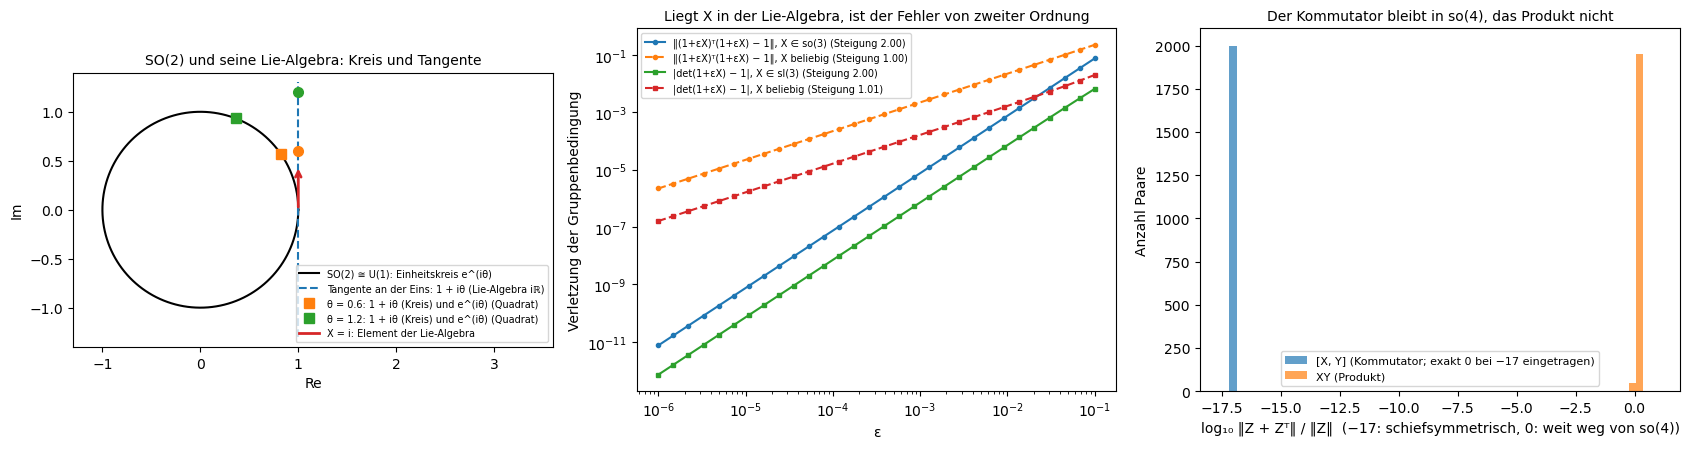

Dimension des Tangentialraums (numerisch) und Formel, n = 2, 3, 4, 5:
  SO(n)     [1, 3, 6, 10]   Formel [1, 3, 6, 10]
  SL(n,ℝ)   [3, 8, 15, 24]   Formel [3, 8, 15, 24]
  U(n)      [4, 9, 16, 25]   Formel [4, 9, 16, 25]
  SU(n)     [3, 8, 15, 24]   Formel [3, 8, 15, 24]
  Sp(2n,ℝ)  [10, 21, 36, 55]   Formel [10, 21, 36, 55]
  SO(1,3)   6   (3 Drehungen + 3 Boosts)
Kommutator: größter Abstand von so(4) 0.0e+00;  Produkt: kleinster Abstand 0.78


In [2]:
rng = np.random.default_rng(1)
Jsym = lambda n: np.block([[np.zeros((n, n)), np.eye(n)], [-np.eye(n), np.zeros((n, n))]])
eta = np.diag([-1.0, 1, 1, 1])

def constraint(name, n):
    """(Matrixgröße, komplex?, F) mit G = {g : F(g) = 0}; F liefert einen reellen Vektor."""
    cplx = lambda A: np.r_[A.real.ravel(), A.imag.ravel()]
    if name == "SO(n)":
        return n, False, lambda g: (g.T @ g - np.eye(n)).ravel()
    if name == "SL(n,ℝ)":
        return n, False, lambda g: np.array([np.linalg.det(g) - 1])
    if name == "U(n)":
        return n, True, lambda g: cplx(g.conj().T @ g - np.eye(n))
    if name == "SU(n)":
        return n, True, lambda g: np.r_[cplx(g.conj().T @ g - np.eye(n)), cplx(np.array([sdet(g) - 1]))]
    if name == "Sp(2n,ℝ)":
        return 2 * n, False, lambda g: (g.T @ Jsym(n) @ g - Jsym(n)).ravel()
    if name == "SO(1,3)":
        return 4, False, lambda g: (g.T @ eta @ g - eta).ravel()

def tangent_dim(name, n, h=1e-6):
    N, is_c, F = constraint(name, n)
    dirs = [np.eye(N * N)[k].reshape(N, N) for k in range(N * N)]
    if is_c:
        dirs = dirs + [1j * d for d in dirs]
    Jac = np.array([(F(np.eye(N) + h * d) - F(np.eye(N) - h * d)) / (2 * h) for d in dirs]).T
    return len(dirs) - np.linalg.matrix_rank(Jac, tol=1e-6)

formula = {"SO(n)": lambda n: n * (n - 1) // 2, "SL(n,ℝ)": lambda n: n * n - 1, "U(n)": lambda n: n * n,
           "SU(n)": lambda n: n * n - 1, "Sp(2n,ℝ)": lambda n: n * (2 * n + 1)}
dims = {g: [tangent_dim(g, n) for n in range(2, 6)] for g in formula}

eps = np.logspace(-6, -1, 30)
Xa = rng.normal(size=(3, 3)); Xa = Xa - Xa.T          # in so(3)
Xg = rng.normal(size=(3, 3))                           # beliebig
Xt = rng.normal(size=(3, 3)); Xt -= np.trace(Xt) / 3 * np.eye(3)   # spurfrei: in sl(3)
viol_so = lambda X: [np.linalg.norm((np.eye(3) + e * X).T @ (np.eye(3) + e * X) - np.eye(3)) for e in eps]
viol_sl = lambda X: [abs(np.linalg.det(np.eye(3) + e * X) - 1) for e in eps]
slope = lambda v: np.polyfit(np.log(eps), np.log(v), 1)[0]

pairs = rng.normal(size=(2000, 2, 4, 4)); pairs = pairs - np.transpose(pairs, (0, 1, 3, 2))
skew_res = lambda Z: np.linalg.norm(Z + Z.T) / np.linalg.norm(Z)
res_comm = np.array([skew_res(comm(X, Y)) for X, Y in pairs])
res_prod = np.array([skew_res(X @ Y) for X, Y in pairs])

fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
t = np.linspace(0, 2 * np.pi, 300)
ax = axes[0]
ax.plot(np.cos(t), np.sin(t), "k-", label="SO(2) ≅ U(1): Einheitskreis e^(iθ)")
ax.plot([1, 1], [-1.3, 1.3], "C0--", label="Tangente an der Eins: 1 + iθ (Lie-Algebra iℝ)")
for th, c in ((0.6, "C1"), (1.2, "C2")):
    ax.plot(1, th, "o", color=c, ms=7)
    ax.plot(np.cos(th), np.sin(th), "s", color=c, ms=7, label=f"θ = {th}: 1 + iθ (Kreis) und e^(iθ) (Quadrat)")
ax.annotate("", xy=(1, 0.45), xytext=(1, 0), arrowprops=dict(arrowstyle="->", color="C3", lw=2))
ax.plot([], [], color="C3", lw=2, label="X = i: Element der Lie-Algebra")
ax.set_aspect("equal"); ax.set_xlim(-1.3, 3.6); ax.set_ylim(-1.4, 1.4)
ax.set_xlabel("Re"); ax.set_ylabel("Im")
ax.set_title("SO(2) und seine Lie-Algebra: Kreis und Tangente", fontsize=10)
ax.legend(fontsize=7, loc="lower right")
ax = axes[1]
for v, lab, st in ((viol_so(Xa), "‖(1+εX)ᵀ(1+εX) − 1‖, X ∈ so(3)", "o-"), (viol_so(Xg), "‖(1+εX)ᵀ(1+εX) − 1‖, X beliebig", "o--"),
                   (viol_sl(Xt), "|det(1+εX) − 1|, X ∈ sl(3)", "s-"), (viol_sl(Xg), "|det(1+εX) − 1|, X beliebig", "s--")):
    ax.loglog(eps, v, st, ms=3, label=f"{lab} (Steigung {slope(v):.2f})")
ax.set_xlabel("ε")
ax.set_ylabel("Verletzung der Gruppenbedingung")
ax.set_title("Liegt X in der Lie-Algebra, ist der Fehler von zweiter Ordnung", fontsize=10)
ax.legend(fontsize=7)
ax = axes[2]
bins = np.linspace(-17.5, 1, 60)
ax.hist(np.log10(np.maximum(res_comm, 1e-17)), bins=bins, alpha=0.7, label="[X, Y] (Kommutator; exakt 0 bei −17 eingetragen)")
ax.hist(np.log10(res_prod), bins=bins, alpha=0.7, label="XY (Produkt)")
ax.set_xlabel("log₁₀ ‖Z + Zᵀ‖ / ‖Z‖  (−17: schiefsymmetrisch, 0: weit weg von so(4))")
ax.set_ylabel("Anzahl Paare")
ax.set_title("Der Kommutator bleibt in so(4), das Produkt nicht", fontsize=10)
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

print("Dimension des Tangentialraums (numerisch) und Formel, n = 2, 3, 4, 5:")
for g, f in formula.items():
    print(f"  {g:9s} {dims[g]}   Formel {[f(n) for n in range(2, 6)]}")
print(f"  SO(1,3)   {tangent_dim('SO(1,3)', 4)}   (3 Drehungen + 3 Boosts)")
print(f"Kommutator: größter Abstand von so(4) {res_comm.max():.1e};  Produkt: kleinster Abstand {res_prod.min():.2f}")

* **Links** liegt $SO(2)$ als Einheitskreis $e^{i\theta}$ in der komplexen Ebene; seine Lie-Algebra ist die Tangente an der Eins, die senkrechte Gerade $1 + i\theta$ (rot der Erzeuger $X = i$). Der Punkt $1 + i\theta$ auf der Tangente (Kreis) und $e^{i\theta}$ auf dem Einheitskreis (Quadrat) liegen für kleine $\theta$ dicht beieinander und laufen für größere auseinander: Die Lie-Algebra beschreibt die Gruppe nur in erster Ordnung, die Exponentialabbildung biegt die Tangente auf den Kreis zurück.
* In der **Mitte** (beide Achsen logarithmisch) verletzt $1 + \varepsilon X$ die Gruppenbedingung mit Steigung 2.00, wenn $X$ in $\mathfrak{so}(3)$ bzw. $\mathfrak{sl}(3)$ liegt, und mit Steigung 1.00 bzw. 1.01 für beliebiges $X$. Genau das definiert den Tangentialraum: Die linearisierte Bedingung ist erfüllt, wenn der Fehler erst in zweiter Ordnung auftritt. Laut **Ausgabe** stimmen die numerisch gezählten Dimensionen für alle fünf Familien und $n = 2$ bis 5 mit den Formeln überein, und die Lorentz-Gruppe hat 6 (3 Drehungen, 3 Boosts). Das beantwortet die Vorhersage: $X^T = -X$, drei unabhängige Richtungen für $SO(3)$.
* **Rechts** liegen alle 2000 Kommutatoren exakt in $\mathfrak{so}(4)$ (Abstand 0, bei −17 eingetragen), alle Produkte $XY$ dagegen weit davon entfernt (relativer Abstand laut Ausgabe mindestens 0.78). Die Lie-Algebra ist unter der Klammer abgeschlossen, nicht unter dem Produkt.
* **Wo es vorkommt:** Jede Linearisierung einer Symmetrie: kleine Drehungen in der Mechanik ($\delta\vec r = \vec\omega\times\vec r$), Kalman-Filter für Lagen (der Fehler lebt in $\mathfrak{so}(3)$, die Lage in $SO(3)$), Gradienten bei der Optimierung über Drehungen, orthogonale oder unitäre Matrizen (etwa orthogonale Gewichtsmatrizen in rekurrenten neuronalen Netzen) und die Erzeuger der Quantenmechanik (Impuls, Drehimpuls, Hamilton-Operator).

##### *2. Die Exponentialabbildung: von der Algebra zurück in die Gruppe*

Wie kommt man von einem infinitesimalen Erzeuger zu einer endlichen Transformation? Vorher vorhersagen: Wie viele Terme der Reihe $\sum_kX^k/k!$ braucht man für eine Drehmatrix mit $\Vert X\Vert = 20$, und wird das Ergebnis dann auf 15 Stellen genau?

Für schiefsymmetrische $4\times4$-Matrizen der Norm 1, 5 und 20 vergleicht der Code die abgebrochene Taylor-Reihe mit `scipy.linalg.expm` (Padé-Näherung mit Skalieren und Quadrieren). Dazu kommen die Diagonalisierung und das Lösen der Differentialgleichung $\dot g = Xg$ als weitere Wege. In der Mitte stehen die drei Typen einparametriger Untergruppen von $SL(2,\mathbb R)$, als Bahnen von Punkten der Ebene unter $e^{tX}$. Rechts werden Lorentz-Boosts in $x$-Richtung hintereinander ausgeführt, jeder mit der Geschwindigkeit $0.5c$.

**Hintergrund & Fachbegriffe:**
- **Matrixexponential** $e^X = \sum_{k\geq0}X^k/k!$; für Diagonalmatrizen die Exponentialfunktion der Einträge.
- **Einparametrige Untergruppe:** die Kurve $t\mapsto e^{tX}$; es gilt $e^{sX}e^{tX} = e^{(s + t)X}$.
- **Skalieren und Quadrieren:** $e^X = (e^{X/2^s})^{2^s}$; man berechnet das Exponential einer kleinen Matrix und quadriert $s$-mal.
- **Elliptisch, parabolisch, hyperbolisch:** die drei Konjugationsklassen-Typen in $SL(2,\mathbb R)$ nach dem Vorzeichen von $\delta = -\det X$ (für spurfreies $X$): Drehung ($\delta < 0$), Scherung ($\delta = 0$), Streckung ($\delta > 0$).
- **Lorentz-Boost:** Wechsel in ein mit der Geschwindigkeit $v$ bewegtes Bezugssystem; **Rapidität** $\varphi = \mathrm{artanh}(v/c)$.

**Theorie:**

- **Spurfreie $2\times2$-Matrizen:** Nach Cayley-Hamilton gilt $X^2 = \delta\cdot1$ mit $\delta = -\det X$. Die Reihe sortiert sich deshalb in gerade und ungerade Potenzen: $e^X = \cosh\sqrt\delta\cdot1 + \frac{\sinh\sqrt\delta}{\sqrt\delta}X$. Für $\delta < 0$ werden daraus $\cos$ und $\sin$ (eine Drehung, Bahnen sind Ellipsen), für $\delta = 0$ ist $e^X = 1 + X$ (eine Scherung, Bahnen sind Geraden), für $\delta > 0$ $\cosh$ und $\sinh$ (Bahnen sind Hyperbeln).
- **Rodrigues-Formel:** Für $X = [\omega]_\times\in\mathfrak{so}(3)$ mit $\theta = \vert\omega\vert$ gilt $X^3 = -\theta^2X$, also $e^X = 1 + \frac{\sin\theta}\theta X + \frac{1 - \cos\theta}{\theta^2}X^2$: die Drehung um die Achse $\omega/\theta$ um den Winkel $\theta$.
- **Lorentz-Boosts:** Der Erzeuger $K = \begin{pmatrix}0 & 1\cr 1 & 0\end{pmatrix}$ (in $t$ und $x$) liefert $e^{\varphi K} = \begin{pmatrix}\cosh\varphi & \sinh\varphi\cr\sinh\varphi & \cosh\varphi\end{pmatrix}$ mit $v/c = \tanh\varphi$. Boosts in dieselbe Richtung bilden eine einparametrige Untergruppe; Rapiditäten addieren sich, Geschwindigkeiten nicht: $v_{12} = (v_1 + v_2)/(1 + v_1v_2/c^2)$.
- **Rundungsfehler der Reihe:** Für große $\Vert X\Vert$ sind die mittleren Terme riesig ($\Vert X\Vert^k/k!$ hat sein Maximum bei $k\approx\Vert X\Vert$), während das Ergebnis klein ist; die Auslöschung kostet Stellen. Deshalb rechnet `expm` mit Skalieren und Quadrieren.

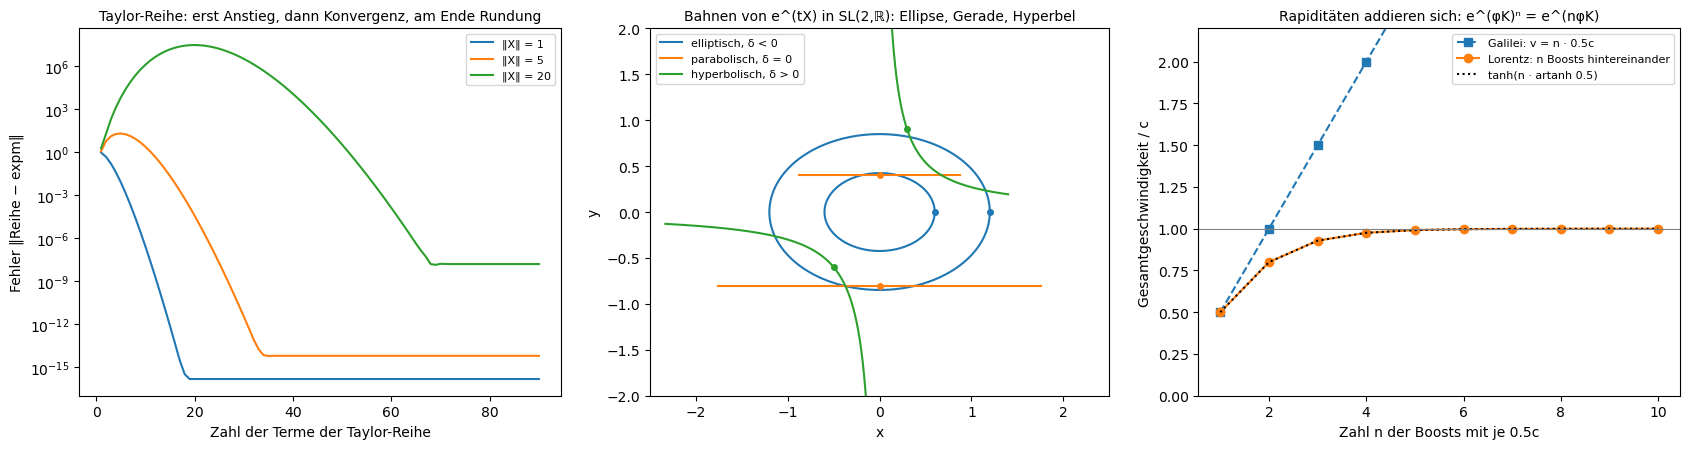

‖X‖ =  1: größter Term ‖X‖ᵏ/k! = 1.0e+00, Fehler < 1e-10: ab 14 Termen, bester Fehler 1.3e-16 (nach 19 Termen)
‖X‖ =  5: größter Term ‖X‖ᵏ/k! = 2.6e+01, Fehler < 1e-10: ab 29 Termen, bester Fehler 5.8e-15 (nach 35 Termen)
‖X‖ = 20: größter Term ‖X‖ᵏ/k! = 4.3e+07, Fehler < 1e-10: nie, bester Fehler 1.4e-08 (nach 69 Termen)
Vier Wege für ‖X‖ = 1: |Taylor(30) − expm| = 1.1e-16, |Eigenzerlegung − expm| = 6.7e-16, |Differentialgleichung − expm| = 5.0e-13
Formel cosh√δ·1 + sinh√δ/√δ·X für 500 zufällige X ∈ sl(2,ℝ): größte Abweichung 1.2e-12;  Rodrigues gegen expm: 3.3e-16
det e^X = e^(tr X): 4.039331 = 4.039331;  e^(sX)e^(tX) = e^((s+t)X): True;  e^(X+Y) = e^X e^Y für nicht vertauschende X, Y: False
Zwei Boosts mit 0.5c: 0.8000c (Formel (0.5 + 0.5)/(1 + 0.25) = 0.8c), zehn Boosts: 0.999966c


In [3]:
rng = np.random.default_rng(2)
def exp_taylor(X, terms):
    out, term = np.eye(len(X)), np.eye(len(X))
    for k in range(1, terms):
        term = term @ X / k
        out = out + term
    return out

A0 = rng.normal(size=(4, 4)); A0 = A0 - A0.T; A0 /= np.linalg.norm(A0, 2)        # schiefsymmetrisch, Spektralnorm 1
terms = np.arange(1, 91)
taylor_err = {s: np.array([np.linalg.norm(exp_taylor(s * A0, k) - expm(s * A0), 2) for k in terms]) for s in (1, 5, 20)}
w_, V_ = np.linalg.eig(A0)
via_eig = (V_ @ np.diag(np.exp(w_)) @ np.linalg.inv(V_)).real
via_ode = solve_ivp(lambda t, y: (A0 @ y.reshape(4, 4)).ravel(), (0, 1), np.eye(4).ravel(), rtol=1e-12, atol=1e-12).y[:, -1].reshape(4, 4)
Xs2 = rng.normal(size=(500, 2, 2)); Xs2[:, 1, 1] = -Xs2[:, 0, 0]
def exp_sl2(X):
    d = -np.linalg.det(X) + 0j
    r = np.sqrt(d)
    return np.real(np.cosh(r) * np.eye(2) + (np.sinh(r) / r if abs(r) > 1e-12 else 1) * X)
err_sl2 = max(np.abs(exp_sl2(X) - expm(X)).max() for X in Xs2)
w3 = rng.normal(size=3)
X1, Y1 = rng.normal(size=(2, 3, 3))

fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
ax = axes[0]
for s, c in zip(taylor_err, ("C0", "C1", "C2")):
    ax.semilogy(terms, taylor_err[s] + 1e-17, color=c, label=f"‖X‖ = {s}")
ax.set_xlabel("Zahl der Terme der Taylor-Reihe")
ax.set_ylabel("Fehler ‖Reihe − expm‖")
ax.set_title("Taylor-Reihe: erst Anstieg, dann Konvergenz, am Ende Rundung", fontsize=10)
ax.legend(fontsize=8)
ax = axes[1]
tt = np.linspace(-2.2, 2.2, 300)
tt_ell = np.linspace(0, 2 * np.pi / np.sqrt(0.5), 300)       # eine volle Periode der Ellipse
kinds = [("elliptisch, δ < 0", np.array([[0, 1.0], [-0.5, 0]]), [(0.6, 0), (1.2, 0)], "C0"),
         ("parabolisch, δ = 0", np.array([[0, 1.0], [0, 0]]), [(0, 0.4), (0, -0.8)], "C1"),
         ("hyperbolisch, δ > 0", np.array([[0.7, 0], [0, -0.7]]), [(0.3, 0.9), (-0.5, -0.6)], "C2")]
for lab, X, starts, c in kinds:
    for k, p in enumerate(starts):
        orb = np.array([expm(s * X) @ np.array(p) for s in (tt_ell if lab.startswith("ell") else tt)])
        ax.plot(orb[:, 0], orb[:, 1], color=c, label=lab if k == 0 else None)
        ax.plot(*p, "o", color=c, ms=4)
ax.set_xlim(-2.5, 2.5); ax.set_ylim(-2, 2); ax.set_aspect("equal")
ax.set_xlabel("x"); ax.set_ylabel("y")
ax.set_title("Bahnen von e^(tX) in SL(2,ℝ): Ellipse, Gerade, Hyperbel", fontsize=10)
ax.legend(fontsize=8, loc="upper left")
ax = axes[2]
phi0 = np.arctanh(0.5)
K = np.array([[0, 1.0], [1, 0]])
nb = np.arange(1, 11)
boost = [np.linalg.matrix_power(expm(phi0 * K), k) for k in nb]
v_rel = np.array([B[1, 0] / B[0, 0] for B in boost])
ax.plot(nb, 0.5 * nb, "s--", label="Galilei: v = n · 0.5c")
ax.plot(nb, v_rel, "o-", label="Lorentz: n Boosts hintereinander")
ax.plot(nb, np.tanh(nb * phi0), "k:", label="tanh(n · artanh 0.5)")
ax.axhline(1, color="grey", lw=0.8)
ax.set_ylim(0, 2.2)
ax.set_xlabel("Zahl n der Boosts mit je 0.5c")
ax.set_ylabel("Gesamtgeschwindigkeit / c")
ax.set_title("Rapiditäten addieren sich: e^(φK)ⁿ = e^(nφK)", fontsize=10)
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

for s in taylor_err:
    ok = taylor_err[s] < 1e-10
    reach = f"ab {int(terms[np.argmax(ok)])} Termen" if ok.any() else "nie"
    print(f"‖X‖ = {s:2d}: größter Term ‖X‖ᵏ/k! = {max(s ** k / factorial(k) for k in range(60)):.1e}, Fehler < 1e-10: {reach}, "
          f"bester Fehler {taylor_err[s].min():.1e} (nach {int(terms[np.argmin(taylor_err[s])])} Termen)")
print(f"Vier Wege für ‖X‖ = 1: |Taylor(30) − expm| = {np.abs(exp_taylor(A0, 30) - expm(A0)).max():.1e}, |Eigenzerlegung − expm| = "
      f"{np.abs(via_eig - expm(A0)).max():.1e}, |Differentialgleichung − expm| = {np.abs(via_ode - expm(A0)).max():.1e}")
print(f"Formel cosh√δ·1 + sinh√δ/√δ·X für 500 zufällige X ∈ sl(2,ℝ): größte Abweichung {err_sl2:.1e};  Rodrigues gegen expm: {np.abs(rodrigues(w3) - expm(hat(w3))).max():.1e}")
print(f"det e^X = e^(tr X): {np.linalg.det(expm(X1)):.6f} = {np.exp(np.trace(X1)):.6f};  e^(sX)e^(tX) = e^((s+t)X): {np.allclose(expm(0.3 * X1) @ expm(0.9 * X1), expm(1.2 * X1))};  "
      f"e^(X+Y) = e^X e^Y für nicht vertauschende X, Y: {np.allclose(expm(X1 + Y1), expm(X1) @ expm(Y1))}")
print(f"Zwei Boosts mit 0.5c: {v_rel[1]:.4f}c (Formel (0.5 + 0.5)/(1 + 0.25) = 0.8c), zehn Boosts: {v_rel[-1]:.6f}c")

* **Links** (logarithmische Achse) steigt der Fehler der abgebrochenen Taylor-Reihe zuerst an, weil die Terme $\Vert X\Vert^k/k!$ bis $k\approx\Vert X\Vert$ wachsen, und fällt dann schneller als exponentiell. Laut **Ausgabe** reichen bei $\Vert X\Vert = 1$ 14 Terme für einen Fehler unter $10^{-10}$, bei $\Vert X\Vert = 5$ 29 Terme. Bei $\Vert X\Vert = 20$ wird der größte Term $4.3\cdot10^7$, und der Fehler bleibt nach 69 Termen bei $1.4\cdot10^{-8}$ stehen: Die Auslöschung der riesigen Terme kostet etwa acht der sechzehn Stellen. Das beantwortet die Vorhersage. Diagonalisieren, Differentialgleichung und `expm` stimmen für $\Vert X\Vert = 1$ auf $10^{-12}$ überein.
* In der **Mitte** stehen die drei Typen einparametriger Untergruppen von $SL(2,\mathbb R)$: Ellipsen für $\delta < 0$ (eine Drehung in geeigneten Koordinaten), waagrechte Geraden für $\delta = 0$ (Scherung), Hyperbeln $xy = \text{const}$ für $\delta > 0$ (Streckung in $x$, Stauchung in $y$). Die geschlossene Formel $\cosh\sqrt\delta\cdot1 + \frac{\sinh\sqrt\delta}{\sqrt\delta}X$ stimmt laut Ausgabe für 500 zufällige $X$ auf $10^{-12}$, die Rodrigues-Formel auf $3\cdot10^{-16}$.
* **Rechts** wachsen hintereinander ausgeführte Boosts mit je $0.5c$ nicht linear (Galilei, blau), sondern wie $\tanh(n\,\mathrm{artanh}\,0.5)$: Zwei Boosts ergeben $0.8c$, zehn $0.999966c$, nie mehr als $c$. Die Rapidität addiert sich, weil Boosts in dieselbe Richtung eine einparametrige Untergruppe bilden. Außerdem bestätigt die Ausgabe $\det e^X = e^{\mathrm{tr}\,X}$ und $e^{X + Y}\neq e^Xe^Y$ für nicht vertauschende $X, Y$.
* **Wo es vorkommt:** Die Zeitentwicklung $e^{-iHt}$ der Quantenmechanik und jedes Quantengatter, lineare Differentialgleichungen $\dot x = Ax$ (Lösung $e^{tA}x_0$, etwa in der Regelungstechnik und bei Markov-Ketten in stetiger Zeit mit $e^{tQ}$), Drehungen aus Achse und Winkel (Rodrigues) in Robotik und Computergrafik, Lorentz-Transformationen in der Beschleunigerphysik und $SL(2,\mathbb R)$-Matrizen in der Strahlenoptik. Skalieren und Quadrieren mit Padé-Näherung (Higham 2005; Al-Mohy und Higham 2009) ist das Standardverfahren in scipy und MATLAB.

##### *3. Grenzen der Exponentialabbildung: Surjektivität und Logarithmus*

Ist jedes Element einer Lie-Gruppe die Exponentialfunktion eines Elements ihrer Lie-Algebra? Vorher vorhersagen: Gibt es eine reelle spurfreie Matrix $X$ mit $e^X = \mathrm{diag}(-2, -\tfrac12)$?

Für 20 000 zufällige spurfreie $2\times2$-Matrizen $X$ trägt der Code die Spur von $e^X$ gegen $\delta = -\det X$ auf und vergleicht mit der Formel aus Exp. 2. Dann sucht `scipy.linalg.logm` einen Logarithmus von $\mathrm{diag}(-2, -\tfrac12)\in SL(2,\mathbb R)$ und zerlegt die Matrix in ein Produkt von zwei Exponentialen. Rechts wird eine Drehung um die $z$-Achse um den Winkel $\theta$ von 0 bis $2\pi$ gedreht und aus dem Hauptwert des Logarithmus der Drehwinkel zurückgewonnen. Die Ausgabe prüft außerdem Haar-zufällige unitäre Matrizen.

**Hintergrund & Fachbegriffe:**
- **Surjektiv:** jedes Element der Gruppe wird getroffen.
- **Matrixlogarithmus:** eine Matrix $L$ mit $e^L = g$; der **Hauptwert** hat Eigenwerte mit Imaginärteil in $(-\pi, \pi]$.
- **Haar-zufällige unitäre Matrix:** gleichverteilt bezüglich des Haar-Maßes auf $U(n)$ (`scipy.stats.unitary_group`).
- **Injektiv:** verschiedene Urbilder haben verschiedene Bilder; $e^{2\pi J} = 1 = e^0$ zeigt, dass die Exponentialabbildung es nicht ist.

**Theorie:**

- **Spur in $SL(2,\mathbb R)$:** Aus der Formel von Exp. 2 folgt $\mathrm{tr}\,e^X = 2\cosh\sqrt\delta$ für $\delta\geq0$ und $2\cos\sqrt{-\delta}$ für $\delta < 0$, also immer $\mathrm{tr}\,e^X\geq-2$. Elemente mit Spur kleiner als $-2$, etwa $\mathrm{diag}(-2, -\tfrac12)$ mit Spur $-2.5$, sind keine Exponentiale. Sie sind aber Produkte von zweien: $-1 = e^{\pi J}$ mit $J = \begin{pmatrix}0 & 1\cr -1 & 0\end{pmatrix}$, und $\mathrm{diag}(2, \tfrac12) = e^{\mathrm{diag}(\ln2, -\ln2)}$.
- **Kompakte Gruppen:** In $SO(n)$, $U(n)$, $SU(n)$ ist jedes Element ein Exponential, weil man jede Matrix unitär diagonalisieren und die Eigenwerte $e^{i\theta}$ einzeln logarithmieren kann. Auch $GL(n,\mathbb C)$ ist das Bild von $\mathfrak{gl}(n,\mathbb C)$, aber in $GL(n,\mathbb R)$ hat $e^X$ immer positive Determinante $e^{\mathrm{tr}\,X}$.
- **Logarithmus:** Nahe der Eins ist $\log g = \sum_{k\geq1}(-1)^{k+1}(g - 1)^k/k$ eindeutig; weiter weg gibt es viele Logarithmen. Eine Drehung um $\theta > \pi$ ist dieselbe wie eine Drehung um $2\pi - \theta$ um die entgegengesetzte Achse, und der Hauptwert wählt diese.

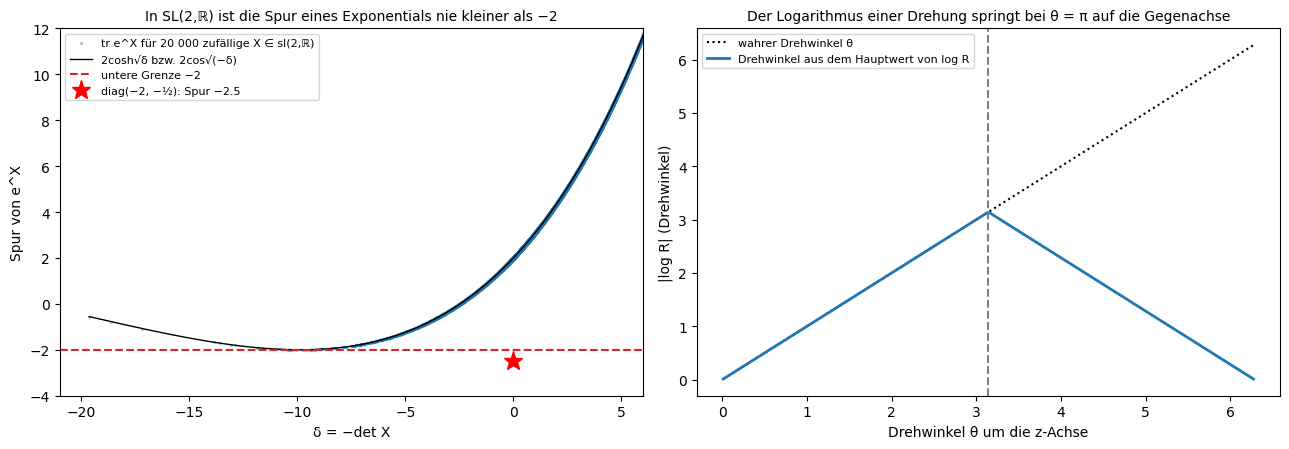

Kleinste Spur unter 20 000 Exponentialen: -1.9999 (Grenze −2);  Formel und expm stimmen überein: True
logm(diag(−2, −½)) = [[(0.6931+3.1416j), 0j], [0j, (-0.6931+3.1416j)]]: reell? False
Aber diag(−2, −½) = e^(πJ) · e^(diag(ln 2, −ln 2)): True;  e^(2πJ) = 1: True
Haar-zufällige U ∈ U(4): |e^(log U) − U| ≤ 4.7e-15, log U antihermitesch bis auf 7.4e-15
Drehwinkel aus dem Logarithmus bei θ = 0.9π, 1.1π, 1.5π: [0.9, 0.9, 0.5] · π


In [4]:
rng = np.random.default_rng(3)
Xs3 = rng.normal(scale=1.5, size=(20000, 2, 2)); Xs3[:, 1, 1] = -Xs3[:, 0, 0]
delta3 = -np.linalg.det(Xs3)
tr3 = np.array([np.trace(expm(X)) for X in Xs3])
dd = np.linspace(delta3.min(), delta3.max(), 600)
tr_formula = np.where(dd >= 0, 2 * np.cosh(np.sqrt(np.abs(dd))), 2 * np.cos(np.sqrt(np.abs(dd))))
target = np.diag([-2.0, -0.5])
L_target = logm(target)
Jrot = np.array([[0, 1.0], [-1, 0]])
product = expm(np.pi * Jrot) @ expm(np.diag([np.log(2), -np.log(2)]))
thetas = np.linspace(0.01, 2 * np.pi - 0.01, 300)
recovered = []
for th in thetas:
    L = logm(rodrigues([0, 0, th])).real
    recovered.append(np.linalg.norm([L[2, 1], L[0, 2], L[1, 0]]))
recovered = np.array(recovered)
U_haar = stats.unitary_group.rvs(4, size=200, random_state=rng)
log_err = max(np.abs(expm(logm(U)) - U).max() for U in U_haar)
antiherm = max(np.abs(logm(U) + logm(U).conj().T).max() for U in U_haar)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
ax = axes[0]
ax.scatter(delta3, tr3, s=2, alpha=0.3, label="tr e^X für 20 000 zufällige X ∈ sl(2,ℝ)")
ax.plot(dd, tr_formula, "k-", lw=1, label="2cosh√δ bzw. 2cos√(−δ)")
ax.axhline(-2, color="C3", ls="--", label="untere Grenze −2")
ax.plot(0, -2.5, "r*", ms=14, label="diag(−2, −½): Spur −2.5")
ax.set_xlim(-21, 6); ax.set_ylim(-4, 12)
ax.set_xlabel("δ = −det X")
ax.set_ylabel("Spur von e^X")
ax.set_title("In SL(2,ℝ) ist die Spur eines Exponentials nie kleiner als −2", fontsize=10)
ax.legend(fontsize=8)
ax = axes[1]
ax.plot(thetas, thetas, "k:", label="wahrer Drehwinkel θ")
ax.plot(thetas, recovered, "C0-", lw=2, label="Drehwinkel aus dem Hauptwert von log R")
ax.axvline(np.pi, color="grey", ls="--")
ax.set_xlabel("Drehwinkel θ um die z-Achse")
ax.set_ylabel("|log R| (Drehwinkel)")
ax.set_title("Der Logarithmus einer Drehung springt bei θ = π auf die Gegenachse", fontsize=10)
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

print(f"Kleinste Spur unter 20 000 Exponentialen: {tr3.min():.4f} (Grenze −2);  Formel und expm stimmen überein: {np.allclose(tr3, np.where(delta3 >= 0, 2 * np.cosh(np.sqrt(np.abs(delta3))), 2 * np.cos(np.sqrt(np.abs(delta3)))))}")
print(f"logm(diag(−2, −½)) = {np.round(L_target, 4).tolist()}: reell? {np.allclose(L_target.imag, 0)}")
print(f"Aber diag(−2, −½) = e^(πJ) · e^(diag(ln 2, −ln 2)): {np.allclose(product, target)};  e^(2πJ) = 1: {np.allclose(expm(2 * np.pi * Jrot), np.eye(2))}")
print(f"Haar-zufällige U ∈ U(4): |e^(log U) − U| ≤ {log_err:.1e}, log U antihermitesch bis auf {antiherm:.1e}")
print(f"Drehwinkel aus dem Logarithmus bei θ = 0.9π, 1.1π, 1.5π: {[round(float(np.interp(a * np.pi, thetas, recovered)) / np.pi, 4) for a in (0.9, 1.1, 1.5)]} · π")

* **Links** liegt die Spur von $e^X$ für alle 20 000 zufälligen $X\in\mathfrak{sl}(2,\mathbb R)$ auf der Kurve $2\cosh\sqrt\delta$ (rechts von 0) bzw. $2\cos\sqrt{-\delta}$ (links). Die Kurve erreicht bei $\delta = -\pi^2\approx-9.9$ den Wert $-2$ und unterschreitet ihn nie; laut **Ausgabe** ist die kleinste Spur $-1.9999$. Der rote Stern $\mathrm{diag}(-2, -\tfrac12)$ mit Spur $-2.5$ ist deshalb kein Exponential: `logm` findet nur einen komplexen Logarithmus mit Imaginärteil $\pi$ auf der Diagonale. Das beantwortet die Vorhersage. Als Produkt zweier Exponentiale $e^{\pi J}e^{\mathrm{diag}(\ln2, -\ln2)}$ lässt sich die Matrix laut Ausgabe aber schreiben.
* **Rechts** gibt der Hauptwert des Logarithmus den Drehwinkel bis $\theta = \pi$ richtig zurück (Diagonale). Danach fällt er wieder ab: Bei $1.1\pi$ und $1.5\pi$ liefert er $0.9\pi$ und $0.5\pi$, weil eine Drehung um $\theta$ dieselbe ist wie um $2\pi - \theta$ um die Gegenachse. Für Haar-zufällige $U\in U(4)$ findet `logm` laut Ausgabe immer einen antihermiteschen Logarithmus mit $e^{\log U} = U$ auf $5\cdot10^{-15}$: In der kompakten Gruppe ist jedes Element ein Exponential.
* **Wo es vorkommt:** Interpolation von Drehungen (SLERP: $R_0e^{t\log(R_0^TR_1)}$ in Animation und Robotik) und Mittelwerte von Orientierungen brauchen den Logarithmus und müssen den Sprung bei 180° beachten. In der Quantensteuerung sucht man zu einem gewünschten Gatter $U$ einen Hamilton-Operator $H$ mit $U = e^{-iHt}$, also einen Logarithmus. In der Strahlenoptik und Beschleunigerphysik zeigt die Spur einer Umlaufmatrix aus $SL(2,\mathbb R)$, ob eine Bahn stabil ist ($\vert\mathrm{tr}\vert < 2$) oder nicht.

##### *4. Die Baker-Campbell-Hausdorff-Formel*

Was ist $\log(e^Ae^B)$, wenn $A$ und $B$ nicht vertauschen? Vorher vorhersagen: Wenn $A$ und $B$ die Größe $\varepsilon$ haben, wie schnell fällt der Fehler mit $\varepsilon$, wenn man die Reihe nach $A + B + \tfrac12[A, B]$ abbricht?

Der Code nimmt zwei zufällige $4\times4$-Matrizen $A_0$, $B_0$ der Norm 1, setzt $A = \varepsilon A_0$, $B = \varepsilon B_0$ und vergleicht den exakten Wert $\log(e^Ae^B)$ (mit `logm`) mit der BCH-Reihe, abgebrochen nach der Ordnung 1, 2, 3 und 4, für $\varepsilon$ von $10^{-3}$ bis 3. Rechts dasselbe in der Heisenberg-Algebra $\mathfrak h_3$ (echte obere Dreiecksmatrizen), wo $[A, B]$ mit allem vertauscht.

**Hintergrund & Fachbegriffe:**
- **BCH-Reihe:** die Reihe $Z(A, B)$ mit $e^Ae^B = e^Z$, sortiert nach der Ordnung (Zahl der Faktoren $A$ oder $B$ in einem Term).
- **Verschachtelter Kommutator:** $[A, [A, B]]$, $[B, [A, [A, B]]]$ usw.
- **Konvergenzradius:** Die Reihe konvergiert sicher für $\Vert A\Vert + \Vert B\Vert < \ln2$, in der Praxis etwas weiter, und versagt für große Matrizen.
- **Heisenberg-Algebra** $\mathfrak h_3$: Basis $P = E_{12}$, $Q = E_{23}$, $C = E_{13}$ ($E_{ij}$ hat eine 1 an der Stelle $(i, j)$) mit $[P, Q] = C$ und $C$ zentral; sie ist **nilpotent**.

**Theorie:**

- **Die Formel:** $\log(e^Ae^B) = A + B + \tfrac12[A, B] + \tfrac1{12}([A, [A, B]] + [B, [B, A]]) - \tfrac1{24}[B, [A, [A, B]]] + O(\varepsilon^5)$. Nach Ordnung $k$ abgebrochen ist der Fehler von der Ordnung $\varepsilon^{k+1}$, im doppeltlogarithmischen Bild eine Gerade mit Steigung $k + 1$.
- **Warum nur Kommutatoren:** Die Formel ist ein Satz über die Lie-Algebra; das Produkt zweier Gruppenelemente nahe der Eins ist durch die Klammer allein bestimmt (daher die Lie-Korrespondenz).
- **Abbruch:** Vertauscht $[A, B]$ mit $A$ und $B$, verschwinden alle höheren Kommutatoren, und es gilt exakt $e^Ae^B = e^{A + B + [A, B]/2}$. Das ist die **Weyl-Relation** der Quantenmechanik ($[x, p] = i\hbar$ ist zentral) und die Grundlage der Verschiebungsoperatoren $D(\alpha)D(\beta) = e^{(\alpha\bar\beta - \bar\alpha\beta)/2}D(\alpha + \beta)$ der Quantenoptik.

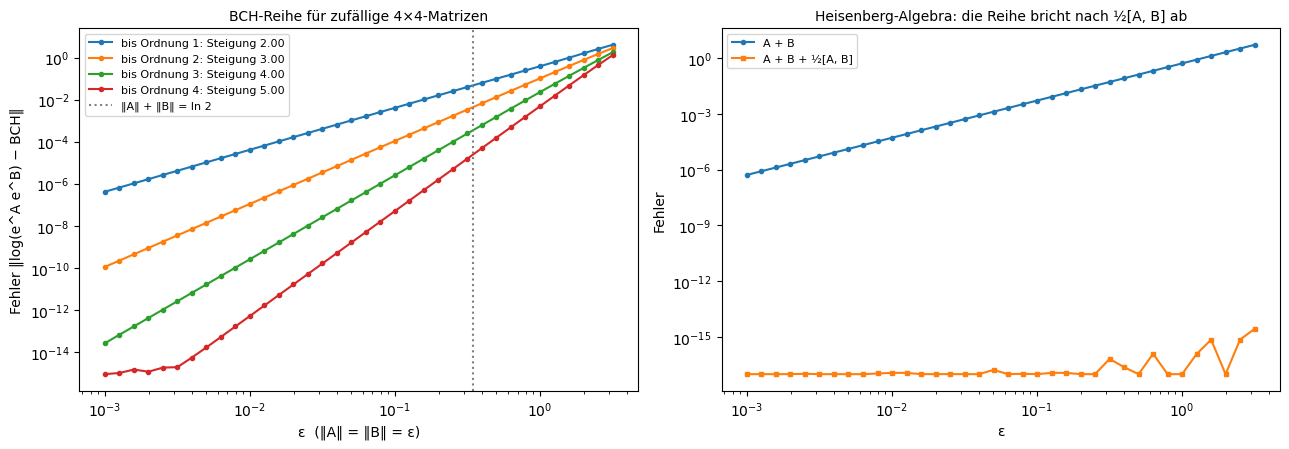

Steigungen für ε < 0.1, Fehler > 1e-12 (Theorie: Ordnung + 1): {1: 1.999, 2: 2.999, 3: 3.998, 4: 4.999}
Fehler bei ε = 0.100: ['4.1e-03', '1.1e-04', '2.5e-06', '5.0e-08'];  bei ε = 2.00: ['1.6e+00', '7.7e-01', '3.2e-01', '1.5e-01']
Heisenberg: größter Fehler mit ½[A, B] 2.7e-15, ohne 5.2e+00;  [A, B] vertauscht mit A und B: True


In [5]:
rng = np.random.default_rng(4)
A0, B0 = rng.normal(size=(2, 4, 4)); A0 /= np.linalg.norm(A0, 2); B0 /= np.linalg.norm(B0, 2)

def bch(A, B, order):
    Z = A + B
    if order >= 2:
        Z = Z + comm(A, B) / 2
    if order >= 3:
        Z = Z + (comm(A, comm(A, B)) + comm(B, comm(B, A))) / 12
    if order >= 4:
        Z = Z - comm(B, comm(A, comm(A, B))) / 24
    return Z

eps4 = np.logspace(-3, 0.5, 36)
bch_err = {k: [] for k in (1, 2, 3, 4)}
for e in eps4:
    A, B = e * A0, e * B0
    Z = logm(expm(A) @ expm(B))
    for k in bch_err:
        bch_err[k].append(np.linalg.norm(Z - bch(A, B, k), 2))
bch_err = {k: np.array(v) for k, v in bch_err.items()}
slopes4 = {}
for k in bch_err:
    small = (eps4 < 0.1) & (bch_err[k] > 1e-12)          # unterhalb von 1e-12 begrenzt die Rundung in logm
    slopes4[k] = np.polyfit(np.log(eps4[small]), np.log(bch_err[k][small]), 1)[0]
P3 = np.zeros((3, 3)); P3[0, 1] = 1
Q3 = np.zeros((3, 3)); Q3[1, 2] = 1
heis = {k: [] for k in (1, 2)}
for e in eps4:
    A, B = e * 1.3 * P3, e * 0.8 * Q3
    Z = logm(expm(A) @ expm(B)).real
    for k in heis:
        heis[k].append(np.linalg.norm(Z - bch(A, B, k), 2))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
ax = axes[0]
for k in bch_err:
    ax.loglog(eps4, bch_err[k] + 1e-17, "o-", ms=3, label=f"bis Ordnung {k}: Steigung {slopes4[k]:.2f}")
ax.axvline(np.log(2) / 2, color="grey", ls=":", label="‖A‖ + ‖B‖ = ln 2")
ax.set_xlabel("ε  (‖A‖ = ‖B‖ = ε)")
ax.set_ylabel("Fehler ‖log(e^A e^B) − BCH‖")
ax.set_title("BCH-Reihe für zufällige 4×4-Matrizen", fontsize=10)
ax.legend(fontsize=8)
ax = axes[1]
ax.loglog(eps4, np.array(heis[1]) + 1e-17, "o-", ms=3, label="A + B")
ax.loglog(eps4, np.array(heis[2]) + 1e-17, "s-", ms=3, label="A + B + ½[A, B]")
ax.set_xlabel("ε")
ax.set_ylabel("Fehler")
ax.set_title("Heisenberg-Algebra: die Reihe bricht nach ½[A, B] ab", fontsize=10)
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

print("Steigungen für ε < 0.1, Fehler > 1e-12 (Theorie: Ordnung + 1):", {k: round(float(v), 3) for k, v in slopes4.items()})
i1 = np.argmin(np.abs(eps4 - 0.1)); i3 = np.argmin(np.abs(eps4 - 2.0))
print(f"Fehler bei ε = {eps4[i1]:.3f}: {[f'{bch_err[k][i1]:.1e}' for k in bch_err]};  bei ε = {eps4[i3]:.2f}: {[f'{bch_err[k][i3]:.1e}' for k in bch_err]}")
print(f"Heisenberg: größter Fehler mit ½[A, B] {max(heis[2]):.1e}, ohne {max(heis[1]):.1e};  [A, B] vertauscht mit A und B: "
      f"{np.allclose(comm(P3, comm(P3, Q3)), 0) and np.allclose(comm(Q3, comm(P3, Q3)), 0)}")

* **Links** (beide Achsen logarithmisch) sind die Fehler der abgebrochenen BCH-Reihe Geraden mit den Steigungen 1.999, 2.999, 3.998 und 4.999 (laut **Ausgabe**, gemessen für $\varepsilon < 0.1$ und Fehler über $10^{-12}$). Das beantwortet die Vorhersage: Nach $\tfrac12[A, B]$ abgebrochen fällt der Fehler wie $\varepsilon^3$. Unterhalb von etwa $10^{-14}$ begrenzt die Rundung in `logm` die rote Kurve. Rechts der gepunkteten Linie ($\Vert A\Vert + \Vert B\Vert = \ln2$) rücken die Kurven zusammen; bei $\varepsilon = 2$ sind die Fehler 1.6, 0.77, 0.32 und 0.15, so groß wie die Matrizen selbst. Für große Matrizen hilft die Reihe nicht mehr.
* **Rechts** ist in der Heisenberg-Algebra schon $A + B + \tfrac12[A, B]$ exakt (Fehler $2.7\cdot10^{-15}$), weil $[A, B]$ mit $A$ und $B$ vertauscht und alle höheren Kommutatoren verschwinden; ohne den Kommutator wächst der Fehler wie $\varepsilon^2$.
* **Wo es vorkommt:** Fehleranalyse von Trotter-Formeln (Exp. 5) und Splitting-Verfahren für Differentialgleichungen, die Magnus-Entwicklung für zeitabhängige Hamilton-Operatoren (Pulsfolgen in der Kernspinresonanz, „Average Hamiltonian Theory“), Verschiebungsoperatoren und kohärente Zustände der Quantenoptik (Weyl-Relation) und die Zusammensetzung kleiner Drehungen in Navigation und Robotik.

##### *5. Trotter-Produktformeln: Quantensimulation mit einfachen Bausteinen*

Wie berechnet ein Quantencomputer $e^{-iHt}$, wenn er nur die Exponentiale der einzelnen Terme von $H$ ausführen kann? Vorher vorhersagen: Um welchen Faktor sinkt der Fehler, wenn man die Zahl der Schritte verdoppelt, bei der Formel erster und bei der zweiter Ordnung?

Der Hamilton-Operator ist das Ising-Modell im transversalen Feld auf 8 Qubits, $H = A + B$ mit $A = -\sum_iZ_iZ_{i+1}$ und $B = -h\sum_iX_i$, $h = 1$, Zeit $t = 2$. $A$ und $B$ vertauschen nicht, aber jedes einzeln ist leicht zu exponieren: $e^{-iA\tau}$ ist diagonal, $e^{-iB\tau}$ ein Produkt von Ein-Qubit-Drehungen. Verglichen werden Lie-Trotter, Strang und Suzuki 4. Ordnung, links als Fehler gegen die Zahl der Schritte $n$, rechts als Fehler gegen die Zahl der Exponentialfaktoren, also die Länge des Quantenschaltkreises.

**Hintergrund & Fachbegriffe:**
- **Pauli-Matrizen** $X$, $Y$, $Z$; $Z_iZ_{i+1}$ wirkt mit $Z$ auf die Qubits $i$ und $i + 1$.
- **Ising-Modell im transversalen Feld:** eine Spinkette mit Kopplung $ZZ$ und einem Feld in $x$-Richtung; Standardbeispiel der Quantensimulation.
- **Lie-Trotter-Formel** (1. Ordnung): $(e^{-iA\tau}e^{-iB\tau})^n$ mit $\tau = t/n$.
- **Strang-Formel** (2. Ordnung, symmetrisch): $(e^{-iA\tau/2}e^{-iB\tau}e^{-iA\tau/2})^n$.
- **Suzuki-Formel** (4. Ordnung): fünf Strang-Schritte mit den Längen $p\tau, p\tau, (1 - 4p)\tau, p\tau, p\tau$ und $p = 1/(4 - 4^{1/3})$; der mittlere läuft rückwärts in der Zeit.
- **Spektralnorm** $\Vert U - V\Vert$: die größte Abweichung, die die beiden Operatoren auf einem Zustand erzeugen können.

**Theorie:**

- **Fehler erster Ordnung:** Nach BCH ist $e^{-iA\tau}e^{-iB\tau} = e^{-i(A + B)\tau - \frac{\tau^2}2[A, B] + O(\tau^3)}$; pro Schritt entsteht ein Fehler $\frac{\tau^2}2\Vert[A, B]\Vert$, nach $n$ Schritten höchstens $\frac{t^2}{2n}\Vert[A, B]\Vert$. Doppelt so viele Schritte halbieren den Fehler.
- **Symmetrische Formeln:** Bei der Strang-Formel heben sich die Terme gerader Ordnung weg, der Fehler pro Schritt ist $O(\tau^3)$, insgesamt $O(t^3/n^2)$. Suzukis Rekursion macht aus einer Formel der Ordnung $2k$ eine der Ordnung $2k + 2$, auf Kosten von fünfmal so vielen Faktoren; insgesamt $O(1/n^4)$.
- **Kosten:** Für eine Genauigkeit $\epsilon$ braucht man etwa $n\propto\epsilon^{-1}$, $\epsilon^{-1/2}$ und $\epsilon^{-1/4}$ Schritte. Formeln höherer Ordnung lohnen sich, wenn man sehr genau sein muss.
- **Vertauschende Teile:** Ist $[A, B] = 0$, sind alle Formeln exakt.

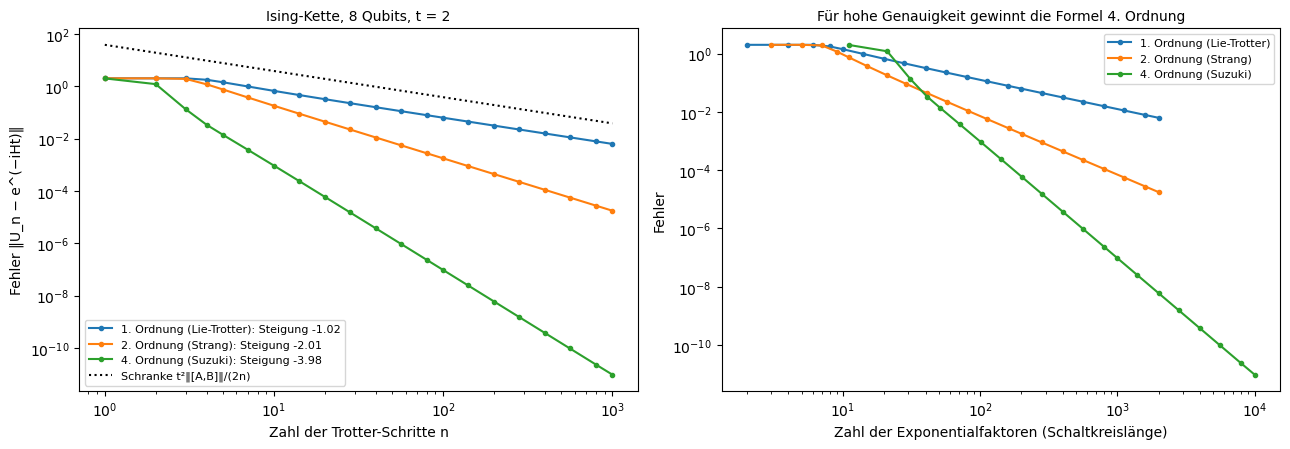

Steigungen: {'1. Ordnung (Lie-Trotter)': -1.02, '2. Ordnung (Strang)': -2.01, '4. Ordnung (Suzuki)': -3.98}
1. Ordnung (Lie-Trotter)   n = 10: 6.63e-01, n = 20: 3.19e-01 (Faktor 2.1);  Faktoren für Fehler < 1e-6: mehr als 2000 (bei n = 1000 noch 6.2e-03)
2. Ordnung (Strang)        n = 10: 1.79e-01, n = 20: 4.41e-02 (Faktor 4.1);  Faktoren für Fehler < 1e-6: mehr als 2001 (bei n = 1000 noch 1.8e-05)
4. Ordnung (Suzuki)        n = 10: 9.25e-04, n = 20: 5.92e-05 (Faktor 15.6);  Faktoren für Fehler < 1e-6: 561
‖[A, B]‖ = 19.04;  Schranke 1. Ordnung bei n = 100: 0.381, gemessen 0.063


In [6]:
n_q, h_field, t_sim = 8, 1.0, 2.0
Zs = [site_op(PZ, i, n_q) for i in range(n_q)]
A_diag = -np.real(sum(np.diag(Zs[i] @ Zs[i + 1]) for i in range(n_q - 1)))
B_op = -h_field * sum(site_op(PX, i, n_q) for i in range(n_q))
H_tfim = np.diag(A_diag) + B_op
U_exact = expm(-1j * H_tfim * t_sim)
eA = lambda tau: np.diag(np.exp(-1j * A_diag * tau))
def eB(tau):
    r = np.cos(h_field * tau) * np.eye(2) + 1j * np.sin(h_field * tau) * PX   # e^{+i h τ X}, weil B = −h ΣX
    out = np.array([[1.0 + 0j]])
    for _ in range(n_q):
        out = np.kron(out, r)
    return out
S2 = lambda tau: eA(tau / 2) @ eB(tau) @ eA(tau / 2)
p_s = 1 / (4 - 4 ** (1 / 3))
S4 = lambda tau: S2(p_s * tau) @ S2(p_s * tau) @ S2((1 - 4 * p_s) * tau) @ S2(p_s * tau) @ S2(p_s * tau)
steps = np.array([1, 2, 3, 4, 5, 7, 10, 14, 20, 28, 40, 56, 80, 100, 140, 200, 280, 400, 560, 800, 1000])
trotter = {"1. Ordnung (Lie-Trotter)": (lambda n: np.linalg.matrix_power(eA(t_sim / n) @ eB(t_sim / n), n), lambda n: 2 * n),
           "2. Ordnung (Strang)": (lambda n: np.linalg.matrix_power(S2(t_sim / n), n), lambda n: 2 * n + 1),
           "4. Ordnung (Suzuki)": (lambda n: np.linalg.matrix_power(S4(t_sim / n), n), lambda n: 10 * n + 1)}
terr = {name: np.array([np.linalg.norm(f(n) - U_exact, 2) for n in steps]) for name, (f, _) in trotter.items()}
comm_norm = np.linalg.norm(comm(np.diag(A_diag), B_op), 2)
tslopes = {}
for name in terr:
    ok = (terr[name] > 1e-11) & (steps >= 4)
    tslopes[name] = np.polyfit(np.log(steps[ok]), np.log(terr[name][ok]), 1)[0]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
for name, (f, cost) in trotter.items():
    axes[0].loglog(steps, terr[name], "o-", ms=3, label=f"{name}: Steigung {tslopes[name]:.2f}")
    axes[1].loglog([cost(n) for n in steps], terr[name], "o-", ms=3, label=name)
axes[0].loglog(steps, t_sim ** 2 / (2 * steps) * comm_norm, "k:", label="Schranke t²‖[A,B]‖/(2n)")
axes[0].set_xlabel("Zahl der Trotter-Schritte n")
axes[0].set_ylabel("Fehler ‖U_n − e^(−iHt)‖")
axes[0].set_title("Ising-Kette, 8 Qubits, t = 2", fontsize=10)
axes[0].legend(fontsize=8)
axes[1].set_xlabel("Zahl der Exponentialfaktoren (Schaltkreislänge)")
axes[1].set_ylabel("Fehler")
axes[1].set_title("Für hohe Genauigkeit gewinnt die Formel 4. Ordnung", fontsize=10)
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

print("Steigungen:", {k: round(float(v), 2) for k, v in tslopes.items()})
for name, (f, cost) in trotter.items():
    i10, i20 = list(steps).index(10), list(steps).index(20)
    need = next((cost(n) for n, e in zip(steps, terr[name]) if e < 1e-6), None)
    need = need if need is not None else f"mehr als {cost(steps[-1])} (bei n = 1000 noch {terr[name][-1]:.1e})"
    print(f"{name:26s} n = 10: {terr[name][i10]:.2e}, n = 20: {terr[name][i20]:.2e} (Faktor {terr[name][i10] / terr[name][i20]:.1f});  Faktoren für Fehler < 1e-6: {need}")
print(f"‖[A, B]‖ = {comm_norm:.2f};  Schranke 1. Ordnung bei n = 100: {t_sim ** 2 / 200 * comm_norm:.3f}, gemessen {terr['1. Ordnung (Lie-Trotter)'][list(steps).index(100)]:.3f}")

* **Links** (beide Achsen logarithmisch) fallen die Fehler der drei Formeln mit den Steigungen $-1.02$, $-2.01$ und $-3.98$, wie die Theorie verlangt. Laut **Ausgabe** halbiert eine Verdopplung von 10 auf 20 Schritte den Fehler der Lie-Trotter-Formel (Faktor 2.1), viertelt den der Strang-Formel (Faktor 4.1) und teilt den der Suzuki-Formel durch 15.6 (Theorie 16). Das beantwortet die Vorhersage. Die gepunktete Schranke $t^2\Vert[A, B]\Vert/(2n)$ liegt über der Messung (bei $n = 100$: 0.381 gegen 0.063); sie ist eine obere Grenze, wie man sie für Fehlerabschätzungen benutzt.
* **Rechts** steht derselbe Fehler gegen die Zahl der Exponentialfaktoren, also die Länge des Schaltkreises. Für grobe Genauigkeit ist die einfache Formel am billigsten. Für einen Fehler unter $10^{-6}$ braucht die Suzuki-Formel laut Ausgabe 561 Faktoren, während die beiden anderen auch mit 2000 Faktoren nicht dorthin kommen (Fehler $6.2\cdot10^{-3}$ und $1.8\cdot10^{-5}$ bei $n = 1000$).
* **Wo es vorkommt:** Hamilton-Simulation auf Quantencomputern (Lloyd 1996; Trotterisierung in Chemie- und Materialsimulationen, Kommutator-Fehlerschranken von Childs et al. 2021), Split-Step-Fourier-Verfahren für Schrödinger-Gleichungen und Lichtpulse in Glasfasern, symplektische Integratoren in Himmelsmechanik und Moleküldynamik (das Verlet-Verfahren ist eine Strang-Zerlegung) und Quanten-Monte-Carlo (Trotter-Zerlegung der Zustandssumme).

##### *6. Lie-Gruppen-Integratoren: Drehbewegungen, ohne die Gruppe zu verlassen*

Wie integriert man die Lage eines rotierenden Körpers aus gemessenen Winkelgeschwindigkeiten, wie es ein Kreiselsensor (IMU) in Drohne, Smartphone oder Raumsonde tut? Vorher vorhersagen: Wie weit ist die Matrix nach 30 Sekunden explizitem Euler-Verfahren mit Schrittweite 0.01 s von einer Drehmatrix entfernt?

Die Lage $R(t)\in SO(3)$ erfüllt $\dot R = R\,[\omega(t)]_\times$, wobei $\omega(t)$ die Winkelgeschwindigkeit im körperfesten System ist. Gewählt ist eine Taumelbewegung, deren exakte Lösung bekannt ist: $R(t) = e^{t[a]_\times}e^{t[b]_\times}$ mit $a = (0.6, 0, 0.8)$ und $b = (0, 0, 1.5)$, dazu gehört $\omega(t) = e^{-t[b]_\times}a + b$. Vier Verfahren integrieren mit $h = 0.01$ s über 30 s: das explizite Euler-Verfahren, Runge-Kutta 4. Ordnung (beide rechnen mit den neun Einträgen von $R$ wie mit gewöhnlichen Zahlen), und zwei Lie-Gruppen-Verfahren, die jeden Schritt als Drehung $e^{h[\omega]_\times}$ ausführen. Links steht der Abstand von $SO(3)$, rechts der Fehler gegen die exakte Lösung.

**Hintergrund & Fachbegriffe:**
- **Körperfeste Winkelgeschwindigkeit:** die Drehgeschwindigkeit, wie sie ein mitbewegter Sensor misst; $[\omega]_\times$ ist das zugehörige Element von $\mathfrak{so}(3)$.
- **Explizites Euler-Verfahren:** $R_{k+1} = R_k + hR_k[\omega(t_k)]_\times$; **Runge-Kutta 4:** vier Auswertungen pro Schritt, Fehler $O(h^4)$.
- **Lie-Euler-Verfahren:** $R_{k+1} = R_k\,e^{h[\omega(t_k)]_\times}$; **Lie-Mittelpunktsregel:** $R_{k+1} = R_k\,e^{h[\omega(t_k + h/2)]_\times}$ (die einfachste Magnus-Methode, Ordnung 2).
- **Abstand von $SO(3)$:** $\Vert R^TR - 1\Vert$, null genau für orthogonale Matrizen.

**Theorie:**

- **Warum Euler die Gruppe verlässt:** $(1 + hX)^T(1 + hX) = 1 + h^2X^TX$ für schiefsymmetrisches $X = [\omega]_\times$; jeder Schritt streckt die Ebene senkrecht zu $\omega$ um den Faktor $\sqrt{1 + h^2\vert\omega\vert^2}$ und das Volumen um $\det(1 + hX) = 1 + h^2\vert\omega\vert^2$. Nach $N$ Schritten ist $\det R = (1 + h^2\vert\omega\vert^2)^N\approx e^{Nh^2\vert\omega\vert^2}$: Die Matrix wächst, statt sich nur zu drehen.
- **Warum Lie-Verfahren in der Gruppe bleiben:** Jeder Schritt multipliziert mit $e^{h[\omega]_\times}\in SO(3)$, und Produkte von Drehungen sind Drehungen; der Abstand von $SO(3)$ bleibt bei der Rundungsgenauigkeit. Der Fehler gegen die exakte Lösung hängt dann nur noch von der Ordnung des Verfahrens ab: halbe Schrittweite halbiert ihn beim Lie-Euler-Verfahren und viertelt ihn bei der Mittelpunktsregel.
- **Allgemein:** Lie-Gruppen-Integratoren (Crouch-Grossman, Munthe-Kaas, Magnus) lösen $\dot g = gX(t)$ auf beliebigen Lie-Gruppen, so dass die Lösung exakt in der Gruppe bleibt. Sie gehören zur **geometrischen Integration**, wie die symplektischen Verfahren der Mechanik.

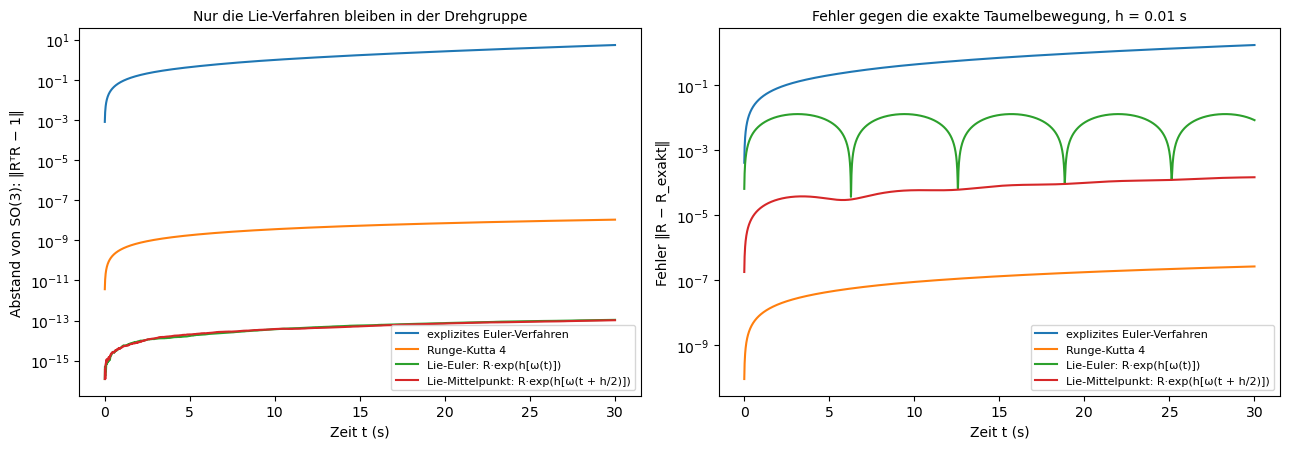

|ω| = 2.377 rad/s für alle t (Schwankung 0e+00); nur die Richtung im Körper ändert sich
explizites Euler-Verfahren               nach 30 s: Abstand von SO(3) 5.4e+00, Fehler 1.7e+00, det R = 5.444040
Runge-Kutta 4                            nach 30 s: Abstand von SO(3) 1.1e-08, Fehler 2.6e-07, det R = 1.000000
Lie-Euler: R·exp(h[ω(t)])                nach 30 s: Abstand von SO(3) 1.1e-13, Fehler 8.3e-03, det R = 1.000000
Lie-Mittelpunkt: R·exp(h[ω(t + h/2)])    nach 30 s: Abstand von SO(3) 1.0e-13, Fehler 1.4e-04, det R = 1.000000
Lie-Euler: R·exp(h[ω(t)])                halbe Schrittweite: Fehler 4.14e-03, Verhältnis 2.00
Lie-Mittelpunkt: R·exp(h[ω(t + h/2)])    halbe Schrittweite: Fehler 3.62e-05, Verhältnis 4.00
Euler: det R wächst pro Schritt um 1 + h²|ω|²; Vorhersage (1 + h²|ω|²)^3000 = 5.444, gemessen 5.444; Singulärwerte [2.201, 2.191, 1.129]


In [7]:
a6, b6 = np.array([0.6, 0.0, 0.8]), np.array([0.0, 0.0, 1.5])
omega6 = lambda t: rodrigues(-t * b6) @ a6 + b6
R_exact6 = lambda t: rodrigues(t * a6) @ rodrigues(t * b6)

def integrate6(step, h, T=30.0):
    R, out = np.eye(3), []
    for k in range(int(round(T / h))):
        R = step(R, k * h, h)
        out.append(R)
    return np.array(out)

def rk4_step(R, t, h):
    f = lambda s, M: M @ hat(omega6(s))
    k1 = f(t, R); k2 = f(t + h / 2, R + h / 2 * k1); k3 = f(t + h / 2, R + h / 2 * k2); k4 = f(t + h, R + h * k3)
    return R + h / 6 * (k1 + 2 * k2 + 2 * k3 + k4)

methods6 = {"explizites Euler-Verfahren": lambda R, t, h: R + h * R @ hat(omega6(t)),
            "Runge-Kutta 4": rk4_step,
            "Lie-Euler: R·exp(h[ω(t)])": lambda R, t, h: R @ rodrigues(h * omega6(t)),
            "Lie-Mittelpunkt: R·exp(h[ω(t + h/2)])": lambda R, t, h: R @ rodrigues(h * omega6(t + h / 2))}
h6 = 0.01
t6 = h6 * np.arange(1, 3001)
Rex = np.array([R_exact6(t) for t in t6])
paths6 = {name: integrate6(f, h6) for name, f in methods6.items()}
orth6 = {name: np.linalg.norm(np.transpose(P, (0, 2, 1)) @ P - np.eye(3), axis=(1, 2)) for name, P in paths6.items()}
err6 = {name: np.linalg.norm(P - Rex, axis=(1, 2)) for name, P in paths6.items()}
half6 = {name: np.linalg.norm(integrate6(methods6[name], h6 / 2)[-1] - Rex[-1]) for name in list(methods6)[2:]}

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
for name in methods6:
    axes[0].semilogy(t6, orth6[name] + 1e-17, label=name)
    axes[1].semilogy(t6, err6[name] + 1e-17, label=name)
axes[0].set_xlabel("Zeit t (s)")
axes[0].set_ylabel("Abstand von SO(3): ‖RᵀR − 1‖")
axes[0].set_title("Nur die Lie-Verfahren bleiben in der Drehgruppe", fontsize=10)
axes[0].legend(fontsize=8)
axes[1].set_xlabel("Zeit t (s)")
axes[1].set_ylabel("Fehler ‖R − R_exakt‖")
axes[1].set_title("Fehler gegen die exakte Taumelbewegung, h = 0.01 s", fontsize=10)
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

print(f"|ω| = {np.linalg.norm(omega6(0)):.3f} rad/s für alle t (Schwankung {np.ptp([np.linalg.norm(omega6(t)) for t in t6]):.0e}); nur die Richtung im Körper ändert sich")
for name in methods6:
    print(f"{name:40s} nach 30 s: Abstand von SO(3) {orth6[name][-1]:.1e}, Fehler {err6[name][-1]:.1e}, det R = {np.linalg.det(paths6[name][-1]):.6f}")
for name, e in half6.items():
    print(f"{name:40s} halbe Schrittweite: Fehler {e:.2e}, Verhältnis {err6[name][-1] / e:.2f}")
w2 = np.linalg.norm(omega6(0)) ** 2
print(f"Euler: det R wächst pro Schritt um 1 + h²|ω|²; Vorhersage (1 + h²|ω|²)^3000 = {(1 + h6 ** 2 * w2) ** 3000:.3f}, gemessen {np.linalg.det(paths6['explizites Euler-Verfahren'][-1]):.3f}; "
      f"Singulärwerte {np.round(np.linalg.svd(paths6['explizites Euler-Verfahren'][-1], compute_uv=False), 3).tolist()}")

* **Links** (logarithmische Achse) wächst der Abstand von $SO(3)$ beim Euler-Verfahren auf 5.4 nach 30 s. Laut **Ausgabe** ist dann $\det R = 5.444$, genau $(1 + h^2\vert\omega\vert^2)^{3000}$ mit $\vert\omega\vert = 2.377$ rad/s, und die Singulärwerte sind 2.20, 2.19 und 1.13: Die Matrix ist gestreckt und keine Drehung mehr. Das beantwortet die Vorhersage. Runge-Kutta 4 verlässt die Gruppe langsam ($1.1\cdot10^{-8}$), die beiden Lie-Verfahren bleiben bei $10^{-13}$, der Rundungsgenauigkeit nach 3000 Multiplikationen.
* **Rechts** steht der Fehler gegen die exakte Lösung. Runge-Kutta 4 ist hier am genauesten ($2.6\cdot10^{-7}$), weil es von vierter Ordnung ist. Das Lie-Euler-Verfahren hat $8.3\cdot10^{-3}$ (der Fehler schwankt mit der Periode $2\pi$ der Drehung um $a$), die Lie-Mittelpunktsregel $1.4\cdot10^{-4}$. Halbe Schrittweite halbiert laut Ausgabe den Fehler des Lie-Euler-Verfahrens (Verhältnis 2.00) und viertelt den der Mittelpunktsregel (4.00). Lie-Verfahren garantieren also die Struktur (das Ergebnis ist immer eine echte Drehung), die Genauigkeit kommt von der Ordnung; Verfahren wie Runge-Kutta-Munthe-Kaas verbinden beides.
* **Wo es vorkommt:** Lagebestimmung aus Kreiselsensoren in Smartphones, Drohnen, Flugzeugen und Satelliten (die Rotationsvektor-Methode von Bortz 1971 integriert in der Lie-Algebra und wendet dann die Exponentialabbildung an), Starrkörpersimulation in Spielen und Robotik, Optimierung auf Lie-Gruppen (Gauß-Newton auf $SE(3)$ in SLAM und Bündelausgleichung, wo jeder Schritt als $R\,e^{[\delta]_\times}$ ausgeführt wird) und Moleküldynamik mit starren Molekülen. Ohne diese Technik muss man die Matrix immer wieder nachorthogonalisieren.

##### *7. Strukturkonstanten, adjungierte Darstellung und Killing-Form*

Woran erkennt man einer Lie-Algebra an, ob sie zu einer kompakten Gruppe gehört, ob sie einfach, auflösbar oder nilpotent ist? Vorher vorhersagen: Welches Vorzeichen hat die Killing-Form von $\mathfrak{so}(3)$, und wie viele positive und negative Richtungen hat die der Lorentz-Algebra $\mathfrak{so}(1,3)$?

Für neun Lie-Algebren, jede durch eine Basis aus Matrizen gegeben, berechnet der Code die Strukturkonstanten, prüft die Jacobi-Identität und bestimmt die Killing-Form mit ihrer Signatur, die abgeleitete Reihe, die absteigende Zentralreihe und das Zentrum. Links werden $\mathrm{ad}_{T_3}$ und $\mathrm{ad}_{T_8}$ in $\mathfrak{su}(3)$ gleichzeitig diagonalisiert, rechts stehen die Signaturen. Die Ausgabe prüft außerdem $\mathrm{Ad}_{e^X} = e^{\mathrm{ad}_X}$.

**Hintergrund & Fachbegriffe:**
- **Strukturkonstanten** $c_{ijk}$: $[e_i, e_j] = \sum_kc_{ijk}e_k$.
- **Adjungierte Darstellung** $\mathrm{ad}_X(Y) = [X, Y]$, als Matrix in der Basis $e_k$: $(\mathrm{ad}_{e_i})_{kj} = c_{ijk}$.
- **Killing-Form** $K(X, Y) = \mathrm{tr}(\mathrm{ad}_X\mathrm{ad}_Y)$; **Signatur** $(n_+, n_-, n_0)$: die Zahl positiver, negativer und verschwindender Eigenwerte der Matrix $K_{ij}$.
- **Gell-Mann-Matrizen** $\lambda_1, \dots, \lambda_8$: die hermiteschen, spurfreien $3\times3$-Matrizen, deren Hälften $T_a = \lambda_a/2$ die Quarks drehen; $T_3$ und $T_8$ sind diagonal.
- **$\mathfrak{se}(2)$:** die Lie-Algebra der Bewegungen der Ebene (eine Drehung, zwei Verschiebungen); **$\mathfrak{aff}(1)$:** Streckung und Verschiebung der Geraden.
- **Abgeleitete Reihe, absteigende Zentralreihe, Zentrum:** siehe Theorie, Abschnitt 2.

**Theorie:**

- **Signatur und Kompaktheit:** Für eine kompakte Gruppe ist $\mathrm{ad}_X$ in einem invarianten Skalarprodukt schiefsymmetrisch, seine Eigenwerte sind rein imaginär, also $K(X, X) = \mathrm{tr}(\mathrm{ad}_X^2)\leq0$: Die Killing-Form ist negativ semidefinit und bei halbeinfachen Algebren negativ definit. Nichtkompakte Richtungen (Boosts, Streckungen) haben reelle Eigenwerte und tragen positiv bei.
- **Ausgeartet heißt nicht halbeinfach:** In auflösbaren und nilpotenten Algebren hat $K$ Nullrichtungen; in einer nilpotenten ist jedes $\mathrm{ad}_X$ nilpotent und $K = 0$.
- **Wurzeln:** In $\mathfrak{su}(3)$ vertauschen $T_3$ und $T_8$. Die gemeinsamen Eigenwerte von $\mathrm{ad}_{T_3}$ und $\mathrm{ad}_{T_8}$ (auf den komplexen Kombinationen der Basis) sind die **Wurzeln**: sechs Vektoren, die ein regelmäßiges Sechseck bilden, und zweimal 0 für $T_3$ und $T_8$ selbst. Daraus wird in Exp. 8 die Klassifikation.
- **$\mathrm{Ad}$ und $\mathrm{ad}$:** $e^XYe^{-X} = e^{\mathrm{ad}_X}Y$, weil beide Seiten dieselbe Differentialgleichung in $X$ lösen.

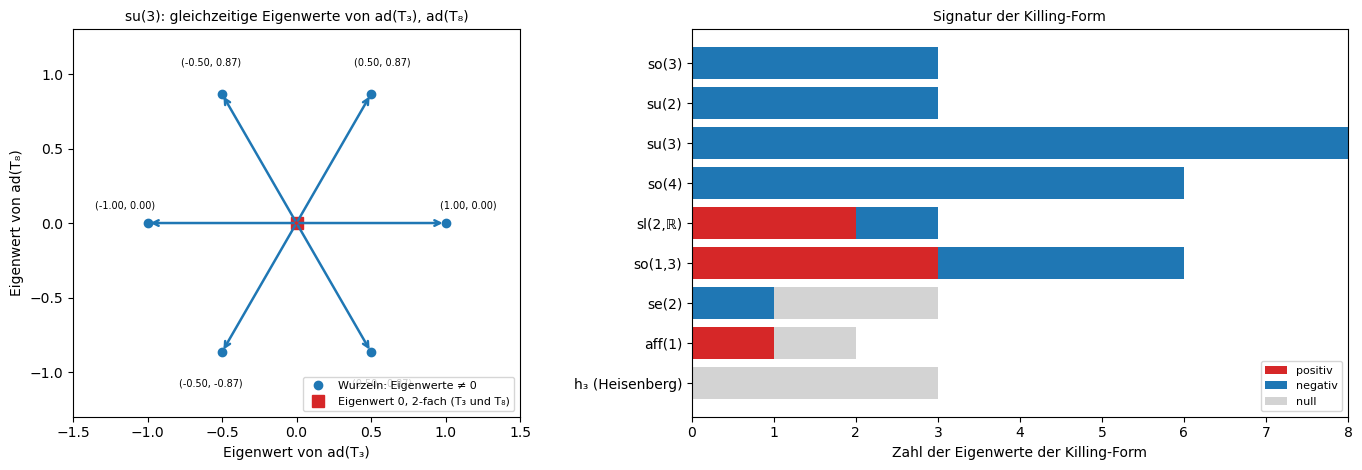

Algebra          dim  Signatur (+,−,0)  halbeinfach  kompakt  abgeleitete Reihe  Zentralreihe  Zentrum  Jacobi-Fehler
so(3)              3  (0, 3, 0)         True         True     [3]                [3]                0   0e+00
su(2)              3  (0, 3, 0)         True         True     [3]                [3]                0   0e+00
su(3)              8  (0, 8, 0)         True         True     [8]                [8]                0   0e+00
so(4)              6  (0, 6, 0)         True         True     [6]                [6]                0   0e+00
sl(2,ℝ)            3  (2, 1, 0)         True         False    [3]                [3]                0   0e+00
so(1,3)            6  (3, 3, 0)         True         False    [6]                [6]                0   0e+00
se(2)              3  (0, 1, 2)         False        False    [3, 2, 0]          [3, 2]             0   0e+00
aff(1)             2  (1, 0, 1)         False        False    [2, 1, 0]          [2, 1]             0   0e+00
h₃

In [8]:
def span_basis(mats, tol=1e-9):
    if len(mats) == 0:
        return []
    M = np.array([m.ravel() for m in mats])
    _, s, vh = np.linalg.svd(M, full_matrices=False)
    r = int(np.sum(s > tol * max(1.0, s[0])))
    return [vh[k].reshape(mats[0].shape) for k in range(r)]

def series(basis, kind):
    """Dimensionen der abgeleiteten Reihe ('derived') oder der absteigenden Zentralreihe ('lower')."""
    g = span_basis(basis)
    cur, dims_ = g, [len(g)]
    for _ in range(6):
        new = span_basis([comm(a, b) for a, b in itertools.combinations(cur, 2)] if kind == "derived" else [comm(a, b) for a in g for b in cur])
        if len(new) == len(cur):
            break
        cur = new
        dims_.append(len(cur))
        if not cur:
            break
    return dims_

E = lambda i, j, n: np.eye(n)[:, [i]] @ np.eye(n)[[j], :]
lam = gell_mann()
algebras = {
    "so(3)": [hat(v) for v in np.eye(3)],
    "su(2)": [-0.5j * P for P in (PX, PY, PZ)],
    "su(3)": [-0.5j * l for l in lam],
    "so(4)": [E(i, j, 4) - E(j, i, 4) for i, j in itertools.combinations(range(4), 2)],
    "sl(2,ℝ)": [np.diag([1.0, -1]), E(0, 1, 2), E(1, 0, 2)],
    "so(1,3)": [E(i, j, 4) - E(j, i, 4) for i, j in itertools.combinations(range(1, 4), 2)] + [E(0, i, 4) + E(i, 0, 4) for i in range(1, 4)],
    "se(2)": [E(1, 0, 3) - E(0, 1, 3), E(0, 2, 3), E(1, 2, 3)],
    "aff(1)": [E(0, 0, 2), E(0, 1, 2)],
    "h₃ (Heisenberg)": [E(0, 1, 3), E(1, 2, 3), E(0, 2, 3)],
}
info7 = {}
for name, basis in algebras.items():
    Kf, ad = killing(basis)
    ev = np.linalg.eigvalsh(Kf)
    tol = 1e-9 * max(1, np.abs(ev).max())
    sig = (int(np.sum(ev > tol)), int(np.sum(ev < -tol)), int(np.sum(np.abs(ev) <= tol)))
    jac = max(np.abs(comm(x, comm(y, z)) + comm(y, comm(z, x)) + comm(z, comm(x, y))).max() for x, y, z in itertools.combinations(basis, 3)) if len(basis) >= 3 else 0.0
    centre = len(basis) - np.linalg.matrix_rank(np.array([a.ravel() for a in ad]).T, tol=1e-9)
    info7[name] = dict(dim=len(basis), sig=sig, jac=jac, derived=series(basis, "derived"), lower=series(basis, "lower"), centre=centre)

Th = lam / 2                                         # hermitesche Basis: [T_a, T_b] = i f_abc T_c
_, adT = killing(list(Th))
w7, V7 = np.linalg.eigh(adT[2] + 0.37 * adT[7])
roots7 = np.array([[np.real(v.conj() @ adT[2] @ v), np.real(v.conj() @ adT[7] @ v)] for v in V7.T])
rng = np.random.default_rng(7)
xs7 = rng.normal(size=8)
Xr = sum(x * b for x, b in zip(xs7, algebras["su(3)"]))
_, ad_su3 = killing(algebras["su(3)"])
coef = lambda M: np.real(np.linalg.lstsq(np.array([b.ravel() for b in algebras["su(3)"]]).T, M.ravel(), rcond=None)[0])
Ad_err = max(np.abs(coef(expm(Xr) @ Y @ expm(-Xr)) - expm(np.real(np.tensordot(xs7, ad_su3, axes=(0, 0)))) @ np.eye(8)[k]).max() for k, Y in enumerate(algebras["su(3)"]))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), gridspec_kw={"width_ratios": [1, 1.3]})
ax = axes[0]
nonzero = np.linalg.norm(roots7, axis=1) > 1e-6
for r in roots7[nonzero]:
    ax.annotate("", xy=r, xytext=(0, 0), arrowprops=dict(arrowstyle="->", color="C0", lw=1.8))
ax.plot(*roots7[nonzero].T, "o", color="C0", label="Wurzeln: Eigenwerte ≠ 0")
ax.plot(0, 0, "s", color="C3", ms=9, label=f"Eigenwert 0, {int(np.sum(~nonzero))}-fach (T₃ und T₈)")
for r in roots7[nonzero]:
    ax.text(r[0] * 1.15, r[1] * 1.15 + (0.12 if abs(r[1]) < 1e-6 else 0.08 * np.sign(r[1])), f"({r[0]:.2f}, {r[1]:.2f})", ha="center", va="center", fontsize=7)
ax.set_aspect("equal"); ax.set_xlim(-1.5, 1.5); ax.set_ylim(-1.3, 1.3)
ax.set_xlabel("Eigenwert von ad(T₃)")
ax.set_ylabel("Eigenwert von ad(T₈)")
ax.set_title("su(3): gleichzeitige Eigenwerte von ad(T₃), ad(T₈)", fontsize=10)
ax.legend(fontsize=8, loc="lower right")
ax = axes[1]
names7 = list(info7)
sig_arr = np.array([info7[n]["sig"] for n in names7])
left = np.zeros(len(names7))
for k, (lab, c) in enumerate([("positiv", "C3"), ("negativ", "C0"), ("null", "lightgrey")]):
    ax.barh(names7, sig_arr[:, k], left=left, color=c, label=lab)
    left += sig_arr[:, k]
ax.invert_yaxis()
ax.set_xlabel("Zahl der Eigenwerte der Killing-Form")
ax.set_title("Signatur der Killing-Form", fontsize=10)
ax.legend(fontsize=8, loc="lower right")
plt.tight_layout()
plt.show()

print(f"{'Algebra':16s} dim  Signatur (+,−,0)  halbeinfach  kompakt  abgeleitete Reihe  Zentralreihe  Zentrum  Jacobi-Fehler")
for name, d in info7.items():
    p_, m_, z_ = d["sig"]
    print(f"{name:16s} {d['dim']:3d}  {str(d['sig']):17s} {str(z_ == 0):11s}  {str(z_ == 0 and p_ == 0):7s}  {str(d['derived']):18s} {str(d['lower']):13s} {d['centre']:6d}   {d['jac']:.0e}")
print("Wurzeln von su(3) (Eigenwerte von ad T₃, ad T₈):", sorted(map(tuple, np.round(roots7[nonzero], 4))))
print(f"Ad(e^X) = e^(ad X) in su(3): größte Abweichung {Ad_err:.1e};  Killing-Form von su(3) in der Basis −iλ/2: Diagonale {np.round(np.diag(killing(algebras['su(3)'])[0]), 6).tolist()}")

* **Links** liegen die gemeinsamen Eigenwerte von $\mathrm{ad}_{T_3}$ und $\mathrm{ad}_{T_8}$: sechs Wurzeln auf einem regelmäßigen Sechseck mit Radius 1, $(\pm1, 0)$ und $(\pm\tfrac12, \pm\tfrac{\sqrt3}2)$, und zweimal 0 (rot) für $T_3$ und $T_8$ selbst. Die Wurzeln sind die Gewichte der adjungierten Darstellung; sie kehren in Exp. 8 als Wurzelsystem $A_2$ und in Exp. 14 als Oktett wieder.
* **Rechts** und laut **Ausgabe** ist die Killing-Form von $\mathfrak{so}(3)$, $\mathfrak{su}(2)$, $\mathfrak{su}(3)$ und $\mathfrak{so}(4)$ negativ definit (blau): halbeinfach und kompakt; für $\mathfrak{su}(3)$ in der Basis $-i\lambda_a/2$ ist sie $-3\cdot1$. Das beantwortet die Vorhersage: $\mathfrak{so}(3)$ ist negativ, die Lorentz-Algebra hat drei positive Richtungen (Boosts) und drei negative (Drehungen), $\mathfrak{sl}(2,\mathbb R)$ zwei positive und eine negative. $\mathfrak{se}(2)$ und $\mathfrak{aff}(1)$ haben ausgeartete Formen, ihre abgeleiteten Reihen enden bei 0 (auflösbar: $[3, 2, 0]$ und $[2, 1, 0]$), ihre Zentralreihen bleiben bei 2 und 1 stehen (nicht nilpotent). Die Heisenberg-Algebra hat $K = 0$, eine bei 0 endende Zentralreihe (nilpotent) und ein eindimensionales Zentrum. Die Jacobi-Identität gilt überall exakt, und $\mathrm{Ad}_{e^X} = e^{\mathrm{ad}_X}$ stimmt auf $6\cdot10^{-16}$.
* **Wo es vorkommt:** Die Killing-Form ist die natürliche Metrik auf kompakten Lie-Gruppen; sie liefert das invariante Skalarprodukt, mit dem man die Wirkung von Eichtheorien (Yang-Mills) aufschreibt. Ob eine Symmetriealgebra auflösbar ist, entscheidet, ob man eine Differentialgleichung mit dieser Symmetrie durch Integrationen lösen kann (Lies ursprüngliches Ziel). In der Quantensteuerung prüft man mit denselben Werkzeugen, ob die dynamische Lie-Algebra einfach ist (Exp. 9). $\mathfrak{se}(2)$ und $\mathfrak{se}(3)$ sind die Algebren der Fahrzeug- und Roboterbewegung.

##### *8. Wurzelsysteme, Dynkin-Diagramme und E₈*

Wie sehen die Wurzeln der einfachen Lie-Algebren aus, und was macht $E_8$ besonders? Vorher vorhersagen: Wie viele Wurzeln hat $G_2$, und welche Drehsymmetrie zeigt die Projektion der 240 Wurzeln von $E_8$ in die Coxeter-Ebene?

Aus den einfachen Wurzeln (für die großen Typen von `sympy.liealgebras`, für $F_4$ von Hand, siehe Ausgabe) erzeugt der Code jeweils das ganze Wurzelsystem, indem er die Wurzeln so lange an den Ebenen senkrecht zu den einfachen Wurzeln spiegelt, bis nichts Neues mehr hinzukommt. Er berechnet die Cartan-Matrix (und vergleicht sie mit sympy), die Ordnung der Weyl-Gruppe als Größe der Bahn eines allgemeinen Vektors und die Coxeter-Zahl. Oben stehen die vier Wurzelsysteme vom Rang 2, unten links die Projektion von $E_8$ auf die Ebene, in der das Coxeter-Element als Drehung um $2\pi/30$ wirkt, und unten rechts die Dynkin-Diagramme, gezeichnet aus den berechneten Cartan-Matrizen.

**Hintergrund & Fachbegriffe:**
- **Wurzelsystem, einfache Wurzeln, Cartan-Matrix, Dynkin-Diagramm, Weyl-Gruppe:** siehe Theorie, Abschnitt 4.
- **Spiegelung an einer Wurzel:** $s_\alpha(v) = v - 2\frac{(v, \alpha)}{(\alpha, \alpha)}\alpha$.
- **Coxeter-Element:** das Produkt $c = s_1s_2\cdots s_r$ der Spiegelungen an allen einfachen Wurzeln; seine Ordnung ist die **Coxeter-Zahl** $h$.
- **Coxeter-Ebene:** die Ebene, auf der $c$ als Drehung um $2\pi/h$ wirkt (aufgespannt von Real- und Imaginärteil des Eigenvektors zum Eigenwert $e^{2\pi i/h}$).
- **Grade** $d_1, \dots, d_r$: die Grade der Polynome, die unter der Weyl-Gruppe invariant bleiben; für $SU(3)$ sind es 2 und 3.

**Theorie:**

- **Rang 2:** Es gibt genau vier Wurzelsysteme: $A_1\times A_1$ (zwei senkrechte Paare, $\mathfrak{so}(4)$), $A_2$ (Sechseck, $\mathfrak{su}(3)$), $B_2$ (Quadrat mit Diagonalen, $\mathfrak{so}(5)$) und $G_2$ (zwei Sechsecke mit Längenverhältnis $\sqrt3$). Die erlaubten Winkel zwischen zwei Wurzeln sind 90°, 60°, 45° und 30° (und ihre Ergänzungen), weil $4\cos^2\theta = \frac{2(\alpha, \beta)}{(\alpha, \alpha)}\cdot\frac{2(\alpha, \beta)}{(\beta, \beta)}$ eine ganze Zahl $\leq3$ sein muss.
- **Zählformeln:** Die Dimension der Algebra ist Rang plus Zahl der Wurzeln; die Ordnung der Weyl-Gruppe ist $d_1d_2\cdots d_r$, die Zahl der positiven Wurzeln $\sum_i(d_i - 1)$ und $h = \max d_i$, außerdem $\vert\Phi\vert = rh$.
- **$E_8$:** 240 Wurzeln im $\mathbb R^8$, alle der Länge $\sqrt2$: die 112 Vektoren $\pm e_i\pm e_j$ und die 128 Vektoren $(\pm\tfrac12, \dots, \pm\tfrac12)$ mit gerader Zahl von Minuszeichen. Sie sind die kürzesten Vektoren des $E_8$-Gitters, das die dichteste Kugelpackung im $\mathbb R^8$ liefert (Viazovska 2016). Die Coxeter-Zahl ist 30, die Grade sind 2, 8, 12, 14, 18, 20, 24, 30.

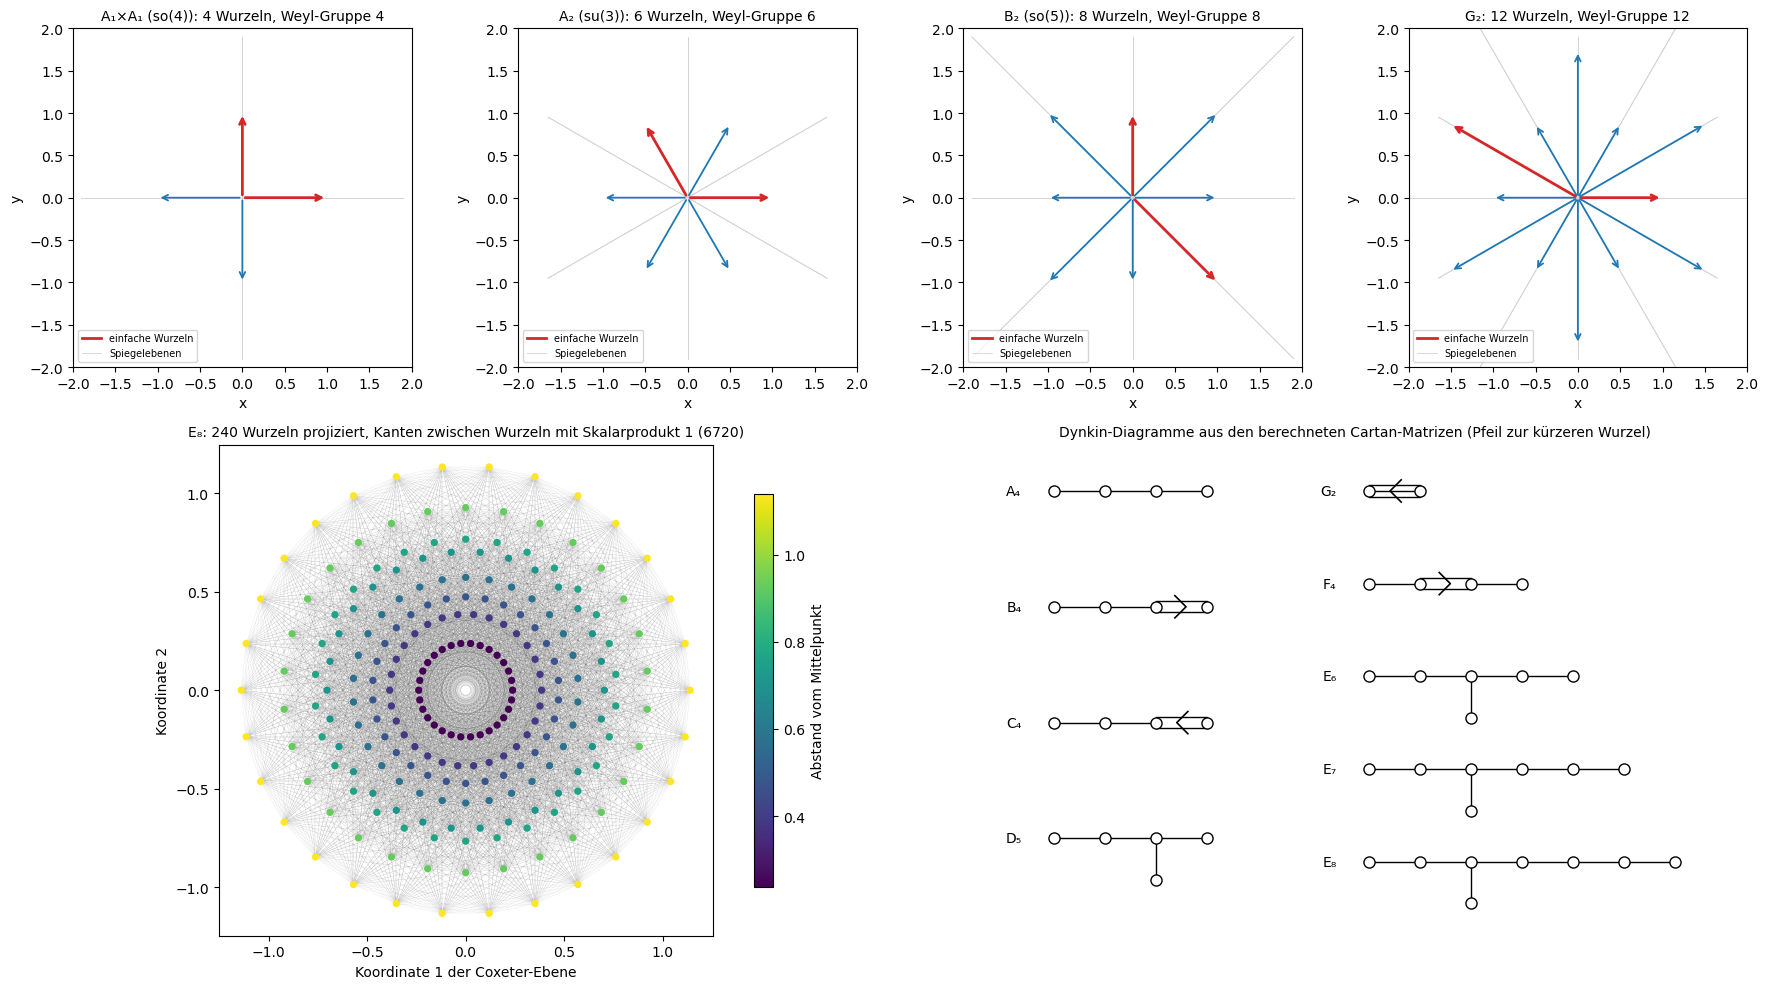

Typ  Rang  Wurzeln  Dimension  |W| (Bahn)   Produkt der Grade  h = Wurzeln/Rang  größter Grad  Cartan-Matrix = sympy
A4      4       20         24          120                120                 5             5   True
B4      4       32         36          384                384                 8             8   True
C4      4       32         36          384                384                 8             8   True
D5      5       40         45        1 920              1 920                 8             8   True
G2      2       12         14           12                 12                 6             6   True
F4      4       48         52        1 152              1 152                12            12   True
E6      6       72         78       51 840             51 840                12            12   True
E7      7      126        133            –          2 903 040                18            18   True
E8      8      240        248            –        696 729 600              

In [9]:
def reflect(v, a):
    return v - 2 * (v @ a) / (a @ a) * a

def root_system(simple):
    simple = [np.asarray(a, float) for a in simple]
    roots = {tuple(np.round(a, 9)) for a in simple}
    frontier = list(roots)
    while frontier:
        new = []
        for r in frontier:
            for a in simple:
                s = tuple(np.round(reflect(np.array(r), a), 9))
                if s not in roots:
                    roots.add(s); new.append(s)
        frontier = new
    return np.array(sorted(roots))

def cartan(simple):
    S = np.asarray(simple, float)
    return np.round(2 * (S @ S.T) / np.diag(S @ S.T)[None, :]).astype(int)      # a_ij = 2(α_i, α_j)/(α_j, α_j), wie in sympy

def weyl_order(simple):
    """Größe der Bahn eines allgemeinen Vektors unter den einfachen Spiegelungen = |W|."""
    simple = [np.asarray(a, float) for a in simple]
    v0 = np.array([np.sqrt(k + 2) + 0.1 * k * k for k in range(len(simple[0]))])
    seen, frontier = {tuple(np.round(v0, 7))}, [v0]
    while frontier:
        new = []
        for v in frontier:
            for a in simple:
                w = reflect(v, a)
                key = tuple(np.round(w, 7))
                if key not in seen:
                    seen.add(key); new.append(w)
        frontier = new
    return len(seen)

F4_simple = [np.array([0, 1, -1, 0.]), np.array([0, 0, 1, -1.]), np.array([0, 0, 0, 1.]), np.array([0.5, -0.5, -0.5, -0.5])]
def sym_simple(t):
    """Einfache Wurzeln aus sympy; für F₄ von Hand, weil sympy 1.14 dort Wurzeln liefert, die nicht zu seiner eigenen Cartan-Matrix passen."""
    if t == "F4":
        return F4_simple
    return [np.array(CartanType(t).simple_root(i + 1), dtype=float) for i in range(CartanType(t).rank())]
sympy_F4 = [np.array(CartanType("F4").simple_root(i + 1), dtype=float) for i in range(4)]
degrees = {"A4": [2, 3, 4, 5], "B4": [2, 4, 6, 8], "C4": [2, 4, 6, 8], "D5": [2, 4, 5, 6, 8], "G2": [2, 6], "F4": [2, 6, 8, 12],
           "E6": [2, 5, 6, 8, 9, 12], "E7": [2, 6, 8, 10, 12, 14, 18], "E8": [2, 8, 12, 14, 18, 20, 24, 30]}
table8 = []
for t, dg in degrees.items():
    S_ = sym_simple(t)
    R_ = root_system(S_)
    W_ = weyl_order(S_) if len(S_) <= 6 else None
    table8.append((t, len(S_), len(R_), len(R_) + len(S_), W_, int(np.prod(dg)), len(R_) // len(S_), max(dg),
                   np.array_equal(cartan(S_), np.array(CartanType(t).cartan_matrix().tolist(), dtype=int)), cartan(S_)))
rank2 = {"A₁×A₁ (so(4))": [[1, 0], [0, 1]], "A₂ (su(3))": [[1, 0], [-0.5, np.sqrt(3) / 2]],
         "B₂ (so(5))": [[1, -1], [0, 1]], "G₂": [[1, 0], [-1.5, np.sqrt(3) / 2]]}
E8s = sym_simple("E8")
R8 = root_system(E8s)
Cox = np.eye(8)
for a in E8s:
    Cox = Cox @ (np.eye(8) - 2 * np.outer(a, a) / (a @ a))
wc, Vc = np.linalg.eig(Cox)
vc = Vc[:, np.argmin(np.abs(wc - np.exp(2j * np.pi / 30)))]
plane, _ = np.linalg.qr(np.c_[vc.real, vc.imag])
xy8 = R8 @ plane
rad8 = np.round(np.hypot(*xy8.T), 6)
G8 = R8 @ R8.T
nb_i, nb_j = np.where(np.triu(np.isclose(G8, 1)))

def dynkin(ax, C, x0, y0, name, dx=0.55):
    r = len(C)
    adj = {i: [j for j in range(r) if j != i and C[i][j] != 0] for i in range(r)}
    def bfs(s):
        dist, prev, q = {s: 0}, {s: None}, [s]
        for u in q:
            for v in adj[u]:
                if v not in dist:
                    dist[v], prev[v] = dist[u] + 1, u
                    q.append(v)
        return max(dist, key=dist.get), prev
    a_, _ = bfs(0)
    b_, prev = bfs(a_)
    path = [b_]
    while prev[path[-1]] is not None:
        path.append(prev[path[-1]])
    pos = {v: (x0 + k * dx, y0) for k, v in enumerate(path)}
    for v in range(r):
        if v not in pos:
            u = next(w for w in adj[v] if w in pos)
            pos[v] = (pos[u][0], y0 - 0.45)
    for i, j in itertools.combinations(range(r), 2):
        lines = C[i][j] * C[j][i]
        if lines == 0:
            continue
        (xa, ya), (xb, yb) = pos[i], pos[j]
        for o in np.linspace(-0.06, 0.06, lines) if lines > 1 else [0]:
            ax.plot([xa, xb], [ya + o, yb + o], "k-", lw=1)
        if lines > 1:
            src, dst = (pos[i], pos[j]) if abs(C[i][j]) > abs(C[j][i]) else (pos[j], pos[i])
            mx, my = (src[0] + dst[0]) / 2, (src[1] + dst[1]) / 2
            sgn = np.sign(dst[0] - src[0]) or 1
            ax.plot([mx - 0.07 * sgn, mx + 0.05 * sgn, mx - 0.07 * sgn], [my + 0.12, my, my - 0.12], "k-", lw=1.2)
    for v, (px, py) in pos.items():
        ax.plot(px, py, "o", ms=8, mfc="white", mec="k")
    ax.text(x0 - 0.35, y0, name, ha="right", va="center", fontsize=10)

fig = plt.figure(figsize=(18, 10))
gs = fig.add_gridspec(2, 4, height_ratios=[1, 1.45])
for k, (name, s) in enumerate(rank2.items()):
    ax = fig.add_subplot(gs[0, k])
    R_ = root_system(s)
    for r in R_:
        ax.plot([-1.9 * r[1], 1.9 * r[1]], [1.9 * r[0], -1.9 * r[0]], color="lightgrey", lw=0.6, zorder=0)
        is_simple = any(np.allclose(r, si) for si in np.asarray(s, float))
        ax.annotate("", xy=r, xytext=(0, 0), arrowprops=dict(arrowstyle="->", color="C3" if is_simple else "C0", lw=2 if is_simple else 1.3))
    ax.plot([], [], color="C3", lw=2, label="einfache Wurzeln")
    ax.plot([], [], color="lightgrey", lw=0.6, label="Spiegelebenen")
    ax.set_xlim(-2, 2); ax.set_ylim(-2, 2); ax.set_aspect("equal")
    ax.set_title(f"{name}: {len(R_)} Wurzeln, Weyl-Gruppe {weyl_order(s)}", fontsize=10)
    ax.set_xlabel("x"); ax.set_ylabel("y")
    ax.legend(fontsize=7, loc="lower left")
ax = fig.add_subplot(gs[1, :2])
segs = np.stack([xy8[nb_i], xy8[nb_j]], axis=1)
ax.add_collection(LineCollection(segs, colors="grey", linewidths=0.15, alpha=0.35))
sc = ax.scatter(*xy8.T, c=rad8, cmap="viridis", s=18, zorder=3)
ax.set_aspect("equal"); ax.autoscale()
ax.set_xlabel("Koordinate 1 der Coxeter-Ebene"); ax.set_ylabel("Koordinate 2")
ax.set_title(f"E₈: {len(R8)} Wurzeln projiziert, Kanten zwischen Wurzeln mit Skalarprodukt 1 ({len(nb_i)})", fontsize=10)
plt.colorbar(sc, ax=ax, shrink=0.8, label="Abstand vom Mittelpunkt")
ax = fig.add_subplot(gs[1, 2:])
for k, t in enumerate(["A4", "B4", "C4", "D5"]):
    dynkin(ax, cartan(sym_simple(t)), 0.6, -1.25 * k, f"{t[0]}{chr(0x2080 + int(t[1]))}")
for k, t in enumerate(["G2", "F4", "E6", "E7", "E8"]):
    dynkin(ax, cartan(sym_simple(t)), 4.0, -1.0 * k, f"{t[0]}{chr(0x2080 + int(t[1]))}")
ax.set_xlim(-0.6, 8.3); ax.set_ylim(-4.8, 0.5)
ax.set_axis_off()
ax.set_title("Dynkin-Diagramme aus den berechneten Cartan-Matrizen (Pfeil zur kürzeren Wurzel)", fontsize=10)
plt.tight_layout()
plt.show()

print("Typ  Rang  Wurzeln  Dimension  |W| (Bahn)   Produkt der Grade  h = Wurzeln/Rang  größter Grad  Cartan-Matrix = sympy")
for t, r, nr, dim, W_, Wd, hh, dmax, same, _ in table8:
    print(f"{t:4s} {r:4d} {nr:8d} {dim:10d}  {('–' if W_ is None else f'{W_:,}'.replace(',', ' ')):>11s}  {f'{Wd:,}'.replace(',', ' '):>17s} {hh:17d} {dmax:13d}   {same}")
print(f"E₈: Längenquadrate {sorted(set(np.round(np.sum(R8 ** 2, axis=1), 6)))}, Skalarprodukte {sorted(set(np.round(G8.ravel(), 6)))}, Nachbarn pro Wurzel {int(np.isclose(G8, 1).sum(axis=1)[0])}")
print(f"Eigenwerte des Coxeter-Elements: e^(2πi·m/30) mit m = {sorted(int(round(a)) % 30 for a in np.angle(wc) * 30 / (2 * np.pi))}")
print(f"Projektion: {len(set(rad8))} Ringe mit je {sorted(set(np.unique(rad8, return_counts=True)[1].tolist()))} Wurzeln")
print("Cartan-Matrix von G₂:", table8[4][-1].tolist(), " von F₄:", table8[5][-1].tolist())
print(f"sympy-Wurzeln für F₄: Cartan-Matrix {cartan(sympy_F4).tolist()}, {len(root_system(sympy_F4))} Wurzeln statt 48")

* **Oben** stehen die vier Wurzelsysteme vom Rang 2 mit ihren einfachen Wurzeln (rot) und den Spiegelebenen (grau): $A_1\times A_1$ mit 4 Wurzeln, $A_2$ mit 6 (Sechseck, Winkel 60°), $B_2$ mit 8 (zwei Längen, Winkel 45°) und $G_2$ mit 12 (zwei Sechsecke mit Längenverhältnis $\sqrt3$, Winkel 30°). Die Weyl-Gruppen haben die Ordnungen 4, 6, 8 und 12. Das beantwortet den ersten Teil der Vorhersage.
* **Unten links** sind die 240 Wurzeln von $E_8$ in die Coxeter-Ebene projiziert: acht Ringe mit je 30 Punkten, eine 30-zählige Drehsymmetrie, weil das Coxeter-Element dort als Drehung um $2\pi/30$ wirkt. Das beantwortet den zweiten Teil. Laut **Ausgabe** sind seine Eigenwerte $e^{2\pi im/30}$ mit $m = 1, 7, 11, 13, 17, 19, 23, 29$ (die Grade minus 1). Die Kanten verbinden Wurzeln mit Skalarprodukt 1; jede Wurzel hat 56 solche Nachbarn, zusammen 6720 Kanten. Alle Wurzeln haben das Längenquadrat 2, alle Skalarprodukte sind ganzzahlig.
* **Unten rechts** stehen die Dynkin-Diagramme, aus den berechneten Cartan-Matrizen gezeichnet: Ketten für $A$, $B$, $C$ (doppelte Linie mit Pfeil zur kürzeren Wurzel), eine Gabel für $D$ und die Ausnahmen mit dreifacher ($G_2$) bzw. doppelter Linie ($F_4$) und den Verzweigungen von $E_6$, $E_7$, $E_8$. Laut Ausgabe stimmen alle Cartan-Matrizen mit sympy überein, die Ordnungen der Weyl-Gruppen aus der Bahn eines Vektors (bis Rang 6) sind gleich dem Produkt der Grade, und Wurzeln geteilt durch Rang ergibt die Coxeter-Zahl. Für $F_4$ liefert sympy 1.14 einfache Wurzeln, die nicht zu seiner eigenen Cartan-Matrix passen (sie erzeugen nur 12 Wurzeln statt 48); deshalb stehen sie im Code von Hand.
* **Wo es vorkommt:** Wurzelsysteme ordnen die Symmetrien der Teilchenphysik ($A_2$ für $SU(3)$, $D_5 = \mathfrak{so}(10)$ und $E_6$ in vereinheitlichten Theorien) und die Gitter der Kristallographie und Codierung: $D_4$ gibt die dichteste Gitterpackung von Kugeln in 4 Dimensionen, das $E_8$-Gitter die dichteste Packung überhaupt in 8 Dimensionen (Viazovska 2016). $E_8$ wurde 2010 auch im Labor sichtbar: Coldea et al. maßen in der Ising-Kette $\mathrm{CoNb_2O_6}$ am kritischen Punkt zwei Anregungen mit dem Massenverhältnis 1.6, nahe am goldenen Schnitt, den Zamolodchikovs $E_8$-Theorie vorhersagt.

##### *9. Dynamische Lie-Algebren: Was ein Quantenschaltkreis erreicht und wo Barren Plateaus entstehen*

Welche unitären Operationen kann ein parametrisierter Quantenschaltkreis überhaupt erzeugen, und warum werden seine Gradienten bei vielen Qubits oft exponentiell klein? Vorher vorhersagen: Wie wächst die Dimension der erzeugten Lie-Algebra mit der Zahl $n$ der Qubits, wenn die Gatter $e^{-i\theta X_i}$ und $e^{-i\theta Z_iZ_{i+1}}$ sind, und wie, wenn noch $e^{-i\theta Z_i}$ hinzukommt?

Ein Schaltkreis aus Gattern $e^{-i\theta_kG_k}$ mit frei wählbaren Winkeln erzeugt die Gruppe $e^{\mathfrak g}$ zur **dynamischen Lie-Algebra** $\mathfrak g$, dem Lie-Abschluss von $\lbrace iG_k\rbrace$. Sind die $G_k$ Pauli-Strings, ist der Kommutator zweier Strings null oder wieder ein String (bis auf einen Faktor $2i$), und der Abschluss lässt sich mit Bit-Operationen exakt berechnen. Links stehen die Dimensionen für fünf Gattersätze auf einer Kette von $n = 2$ bis 7 Qubits. Dann werden tiefe Schaltkreise mit zufälligen Winkeln simuliert ($16n$ Schichten, 1500 Stichproben), für den Ising-Satz und den universellen Satz, und die Varianz von $\ell = \langle\psi\vert X_1\vert\psi\rangle$ über die Stichproben gemessen: in der Mitte gegen die Tiefe bei $n = 6$, rechts gegen $n$ mit der Formel von Ragone et al. (2024).

**Hintergrund & Fachbegriffe:**
- **Pauli-String:** ein Tensorprodukt von $I, X, Y, Z$ auf $n$ Qubits, etwa $Z_1Z_2 = Z\otimes Z\otimes I\otimes\dots$; zwei Strings vertauschen oder antikommutieren.
- **Lie-Abschluss:** der kleinste Unterraum, der die Erzeuger enthält und unter Kommutatoren abgeschlossen ist.
- **Dynamische Lie-Algebra (DLA):** der Lie-Abschluss der Erzeuger $iG_k$ eines Schaltkreises; die erreichbaren Operationen sind genau die Elemente der Gruppe $e^{\mathfrak g}$ (**Steuerbarkeit**, wenn $\mathfrak g = \mathfrak{su}(2^n)$).
- **Barren Plateau:** Die Ausgaben und Gradienten eines zufällig initialisierten Schaltkreises schwanken so wenig, dass man exponentiell viele Messungen braucht, um eine Richtung zu finden.
- **Jordan-Wigner-Transformation:** übersetzt Spinketten in freie Fermionen; $X_i$ und $Z_iZ_{i+1}$ werden quadratisch in $2n$ Majorana-Operatoren.

**Theorie:**

- **Ising-Satz** $\lbrace X_i, Z_iZ_{i+1}\rbrace$ auf der Linie: Nach Jordan-Wigner sind alle Erzeuger quadratisch in Majorana-Operatoren, und quadratische Ausdrücke in $2n$ Majoranas bilden $\mathfrak{so}(2n)$ mit Dimension $n(2n - 1)$; der Schaltkreis ist ein Schaltkreis freier Fermionen und klassisch effizient simulierbar. Auf dem Ring kommt $Z_nZ_1$ hinzu, das nach Jordan-Wigner vom Paritätssektor abhängt; die Algebra verdoppelt sich für $n\geq3$ auf $2n(2n - 1)$.
- **Universeller Satz** $\lbrace X_i, Z_i, Z_iZ_{i+1}\rbrace$: Ein-Qubit-Drehungen um zwei Achsen plus eine verschränkende Kopplung erzeugen ganz $\mathfrak{su}(2^n)$ mit Dimension $4^n - 1$.
- **Ohne Kopplung:** $\lbrace X_i\rbrace$ ist abelsch (Dimension $n$), $\lbrace X_i, Y_i\rbrace$ ist $\mathfrak{su}(2)^{\oplus n}$ (Dimension $3n$).
- **Varianz tiefer Schaltkreise:** Sind die Winkel zufällig und der Schaltkreis tief, ist er Haar-verteilt auf der Gruppe $e^{\mathfrak g}$. Liegt die Observable $O$ in $i\mathfrak g$ und ist $\mathfrak g$ einfach, gilt $\mathrm{Var}[\ell] = \Vert O_{\mathfrak g}\Vert^2\,\Vert\rho_{\mathfrak g}\Vert^2/\dim\mathfrak g$ (Ragone et al. 2024; Fontana et al. 2024), wobei $A_{\mathfrak g}$ die Projektion auf den Raum der Pauli-Strings in $\mathfrak g$ ist und $\Vert\cdot\Vert$ die Frobenius-Norm. Für $\mathfrak{su}(2^n)$ ergibt das $1/(2^n + 1)$, exponentiell klein; für $\mathfrak{so}(2n)$ und $\rho = \vert0\cdots0\rangle\langle0\cdots0\vert$ ergibt es $(n - 1)/(n(2n - 1))$, nur polynomiell klein. Eine kleine DLA verhindert Barren Plateaus, macht den Schaltkreis aber oft auch klassisch simulierbar.

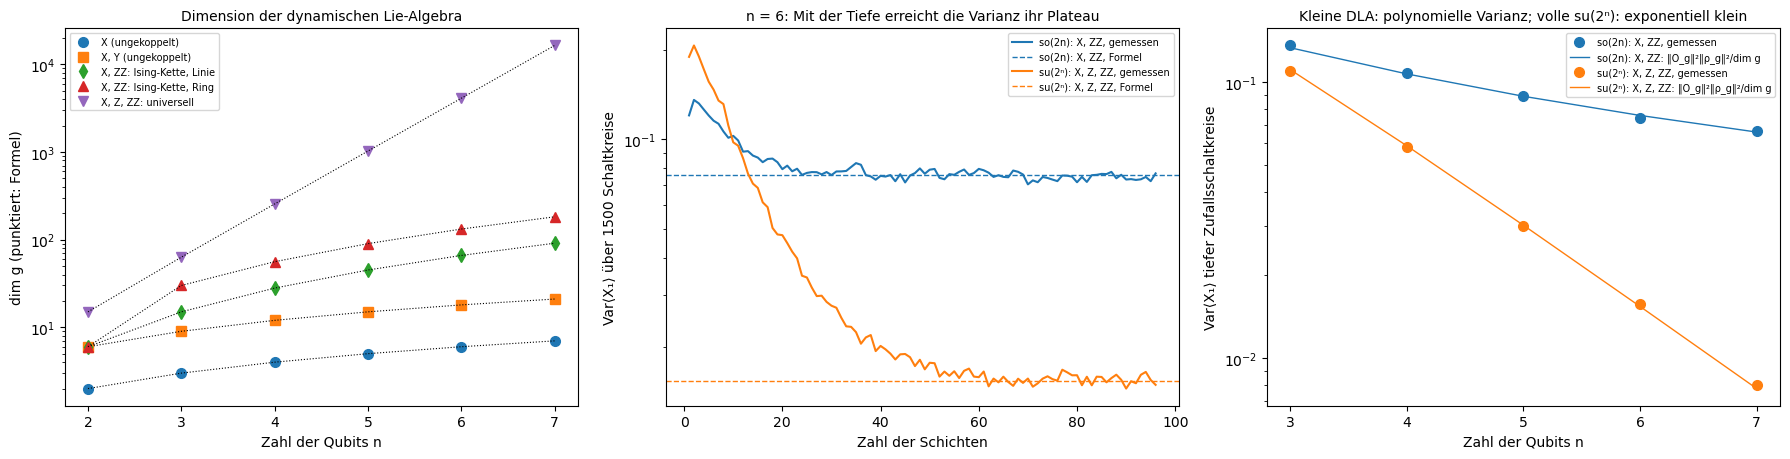

dim g für n = 2 … 7:
  X (ungekoppelt)              [2, 3, 4, 5, 6, 7]   Formel [2, 3, 4, 5, 6, 7]
  X, Y (ungekoppelt)           [6, 9, 12, 15, 18, 21]   Formel [6, 9, 12, 15, 18, 21]
  X, ZZ: Ising-Kette, Linie    [6, 15, 28, 45, 66, 91]   Formel [6, 15, 28, 45, 66, 91]
  X, ZZ: Ising-Kette, Ring     [6, 30, 56, 90, 132, 182]   Formel [6, 30, 56, 90, 132, 182]
  X, Z, ZZ: universell         [15, 63, 255, 1023, 4095, 16383]   Formel [15, 63, 255, 1023, 4095, 16383]
Varianz, n = 3 … 7:
  so(2n): X, ZZ      gemessen ['0.1358', '0.1081', '0.0889', '0.0745', '0.0663']
                     Formel   ['0.1333', '0.1071', '0.0889', '0.0758', '0.0659']
  su(2ⁿ): X, Z, ZZ   gemessen ['0.1099', '0.0584', '0.0301', '0.0157', '0.0080']
                     Formel   ['0.1111', '0.0588', '0.0303', '0.0154', '0.0078']
Verhältnis der Varianzen bei n = 7: 8.3


In [10]:
def parity(v):
    v = np.array(v, dtype=np.int64)
    for s in (32, 16, 8, 4, 2, 1):
        v = v ^ (v >> s)
    return v & 1

def pauli(s):
    """'XZIY' → (x, z) als Bitmasken; Qubit k ist Bit k. X: x = 1, Z: z = 1, Y: beide."""
    return sum(1 << k for k, c in enumerate(s) if c in "XY"), sum(1 << k for k, c in enumerate(s) if c in "ZY")

def lie_closure(gens, n):
    """Lie-Abschluss von Pauli-Strings: antikommutieren zwei, ist ihr Kommutator (bis auf 2i) ihr Produkt (x₁⊕x₂, z₁⊕z₂)."""
    present = np.zeros(4 ** n, bool)
    X = np.array([g[0] for g in gens], np.int64); Z = np.array([g[1] for g in gens], np.int64)
    _, first = np.unique((X << n) | Z, return_index=True)
    X, Z = X[np.sort(first)], Z[np.sort(first)]
    present[(X << n) | Z] = True
    k = 0
    while k < len(X):
        anti = parity((X[k] & Z) ^ (Z[k] & X)) == 1
        cx, cz = X[anti] ^ X[k], Z[anti] ^ Z[k]
        code = (cx << n) | cz
        new = ~present[code]
        if new.any():
            code_new, idx = np.unique(code[new], return_index=True)
            present[code_new] = True
            X = np.concatenate([X, cx[new][idx]]); Z = np.concatenate([Z, cz[new][idx]])
        k += 1
    return X, Z

def chain(n, *terms, ring=False):
    gens = []
    for t in terms:
        if len(t) == 1:
            gens += [pauli("I" * i + t + "I" * (n - i - 1)) for i in range(n)]
        else:
            gens += [pauli("I" * i + t + "I" * (n - i - 2)) for i in range(n - 1)]
            if ring and n > 2:
                gens.append(pauli(t[1] + "I" * (n - 2) + t[0]))
    return gens

dla_sets = {"X (ungekoppelt)": (lambda n: chain(n, "X"), lambda n: n),
            "X, Y (ungekoppelt)": (lambda n: chain(n, "X", "Y"), lambda n: 3 * n),
            "X, ZZ: Ising-Kette, Linie": (lambda n: chain(n, "X", "ZZ"), lambda n: n * (2 * n - 1)),
            "X, ZZ: Ising-Kette, Ring": (lambda n: chain(n, "X", "ZZ", ring=True), lambda n: 2 * n * (2 * n - 1) if n >= 3 else n * (2 * n - 1)),
            "X, Z, ZZ: universell": (lambda n: chain(n, "X", "Z", "ZZ"), lambda n: 4 ** n - 1)}
ns9 = np.arange(2, 8)
dla_dims = {name: [len(lie_closure(f(int(n)), int(n))[0]) for n in ns9] for name, (f, _) in dla_sets.items()}

def gate_data(x, z, n):
    c = np.arange(2 ** n)
    return c ^ x, (1j) ** bin(x & z).count("1") * (-1.0) ** parity((c ^ x) & z)     # P|b⟩ = i^{|x∧z|}(−1)^{|b∧z|}|b⊕x⟩

def random_circuits(gens, n, layers, samples, rng):
    data = [gate_data(x, z, n) for x, z in gens]
    perm_o, ph_o = gate_data(*pauli("X" + "I" * (n - 1)), n)
    psi = np.zeros((samples, 2 ** n), complex); psi[:, 0] = 1
    var_by_layer = []
    for _ in range(layers):
        for perm, ph in data:
            th = rng.uniform(0, 2 * np.pi, samples)[:, None]
            psi = np.cos(th) * psi - 1j * np.sin(th) * (ph * psi[:, perm])
        var_by_layer.append(np.real(np.sum(psi.conj() * (ph_o * psi[:, perm_o]), axis=1)).var())
    return np.array(var_by_layer)

def var_theory(gens, n):
    X, Z = lie_closure(gens, n)
    in_g = np.any((X == pauli("X" + "I" * (n - 1))[0]) & (Z == 0))
    return np.sum(X == 0) / len(X) if in_g else np.nan          # ‖O_g‖² = 2ⁿ, ‖ρ_g‖² = (Zahl der Z-Strings in g)/2ⁿ

rng = np.random.default_rng(9)
ns_var = np.arange(3, 8)
var9 = {"so(2n): X, ZZ": [], "su(2ⁿ): X, Z, ZZ": []}
theo9 = {k: [] for k in var9}
depth6 = {}
for n in ns_var:
    for key, gens in (("so(2n): X, ZZ", chain(int(n), "X", "ZZ")), ("su(2ⁿ): X, Z, ZZ", chain(int(n), "X", "Z", "ZZ"))):
        v = random_circuits(gens, int(n), 16 * int(n), 1500, rng)
        var9[key].append(v[-4 * int(n):].mean())          # Mittel über das letzte Viertel der Schichten
        theo9[key].append(var_theory(gens, int(n)))
        if n == 6:
            depth6[key] = v

fig, axes = plt.subplots(1, 3, figsize=(18, 4.7))
ax = axes[0]
for (name, (_, f)), mk in zip(dla_sets.items(), "osd^v"):
    ax.semilogy(ns9, dla_dims[name], mk, ms=7, label=name)
    ax.semilogy(ns9, [f(int(n)) for n in ns9], "k:", lw=0.8)
ax.set_xlabel("Zahl der Qubits n")
ax.set_ylabel("dim g (punktiert: Formel)")
ax.set_title("Dimension der dynamischen Lie-Algebra", fontsize=10)
ax.legend(fontsize=7)
ax = axes[1]
for key, c in zip(depth6, ("C0", "C1")):
    ax.semilogy(np.arange(1, len(depth6[key]) + 1), depth6[key], color=c, label=f"{key}, gemessen")
    ax.axhline(theo9[key][list(ns_var).index(6)], color=c, ls="--", lw=1, label=f"{key}, Formel")
ax.set_xlabel("Zahl der Schichten")
ax.set_ylabel("Var⟨X₁⟩ über 1500 Schaltkreise")
ax.set_title("n = 6: Mit der Tiefe erreicht die Varianz ihr Plateau", fontsize=10)
ax.legend(fontsize=7)
ax = axes[2]
for key, c in zip(var9, ("C0", "C1")):
    ax.semilogy(ns_var, var9[key], "o", color=c, ms=7, label=f"{key}, gemessen")
    ax.semilogy(ns_var, theo9[key], "-", color=c, lw=1, label=f"{key}: ‖O_g‖²‖ρ_g‖²/dim g")
ax.set_xticks(ns_var)
ax.set_xlabel("Zahl der Qubits n")
ax.set_ylabel("Var⟨X₁⟩ tiefer Zufallsschaltkreise")
ax.set_title("Kleine DLA: polynomielle Varianz; volle su(2ⁿ): exponentiell klein", fontsize=10)
ax.legend(fontsize=7)
plt.tight_layout()
plt.show()

print("dim g für n = 2 … 7:")
for name, (_, f) in dla_sets.items():
    print(f"  {name:28s} {dla_dims[name]}   Formel {[f(int(n)) for n in ns9]}")
print("Varianz, n = 3 … 7:")
for key in var9:
    print(f"  {key:18s} gemessen {[f'{v:.4f}' for v in var9[key]]}")
    print(f"  {'':18s} Formel   {[f'{v:.4f}' for v in theo9[key]]}")
print(f"Verhältnis der Varianzen bei n = 7: {var9['so(2n): X, ZZ'][-1] / var9['su(2ⁿ): X, Z, ZZ'][-1]:.1f}")

* **Links** (logarithmische Achse) liegen die berechneten Dimensionen genau auf den Formeln (punktiert): $n$ für ungekoppelte $X$-Drehungen, $3n$ für ungekoppelte Ein-Qubit-Drehungen, $n(2n - 1)$ für die Ising-Kette auf der Linie (91 bei 7 Qubits) und doppelt so viel auf dem Ring (182; bei $n = 2$ ist der Randterm derselbe wie der innere, deshalb dort nur 6) und $4^n - 1$ für den universellen Satz (16 383 bei 7 Qubits). Das beantwortet die Vorhersage: Mit $X$ und $ZZ$ wächst die Algebra quadratisch, mit $Z$ dazu exponentiell. Eine einzige zusätzliche Gattersorte macht aus einem klassisch simulierbaren Schaltkreis freier Fermionen einen universellen.
* In der **Mitte** ($n = 6$) fällt die Varianz mit der Zahl der Schichten und erreicht nach etwa 20 (Ising) bzw. 60 Schichten (universell) ein Plateau, auf dem der Schaltkreis Haar-zufällig auf seiner Gruppe ist; gestrichelt die Formel. **Rechts** stimmen die Plateau-Werte für $n = 3$ bis 7 auf wenige Prozent mit $\Vert O_{\mathfrak g}\Vert^2\Vert\rho_{\mathfrak g}\Vert^2/\dim\mathfrak g$ überein (laut **Ausgabe** 0.0663 gegen 0.0659 und 0.0080 gegen 0.0078 bei $n = 7$). Für $\mathfrak{su}(2^n)$ halbiert sich die Varianz mit jedem Qubit ($1/(2^n + 1)$), für $\mathfrak{so}(2n)$ fällt sie nur wie $1/(2n)$; bei 7 Qubits ist sie schon 8.3-mal größer.
* **Wo es vorkommt:** Variationelle Quantenalgorithmen (VQE, QAOA, Quantum Machine Learning): Die Dimension der DLA entscheidet, ob ein Ansatz trainierbar ist (kleine DLA) und ob er etwas kann, was ein klassischer Rechner nicht kann (große DLA). Die Steuerbarkeit von Quantensystemen in NMR, Ionenfallen und supraleitenden Qubits ist dieselbe Frage (Lie-Rang-Bedingung). PennyLane berechnet DLAs mit `qml.lie_closure`, und Ansätze, die eine Symmetrie erhalten (Teilchenzahl, Gesamtspin), sind gerade Schaltkreise mit kleinerer DLA.

##### *10. Charaktertafeln endlicher Gruppen*

Wie findet man alle irreduziblen Darstellungen einer endlichen Gruppe, ohne eine einzige Matrix zu kennen? Vorher vorhersagen: Wie viele irreduzible Darstellungen hat $S_4$, und welche Grade haben sie?

Für sechs Gruppen ($S_3$, $D_4$, $Q_8$, $A_4$, $S_4$, $A_5$, alle als Permutationsgruppen aus sympy) berechnet `character_table` die Konjugationsklassen, die Klassenkonstanten und daraus die Charaktere. Die Bilder zeigen die Tafeln: Zeilen sind die irreduziblen Darstellungen, Spalten die Klassen (mit Größe und Elementordnung), die Farbe ist der Realteil. Die Ausgabe prüft die Orthogonalitätsrelationen und zerlegt drei Permutationsdarstellungen von $S_4$: auf den 4 Ecken eines Tetraeders, auf seinen 6 Kanten und die reguläre Darstellung auf den 24 Gruppenelementen.

**Hintergrund & Fachbegriffe:**
- **Konjugationsklasse:** die Menge $\lbrace hgh^{-1}\rbrace$; in $S_n$ die Permutationen mit demselben Zyklentyp.
- **Charakter, Klassenfunktion, Charaktertafel, Grad:** siehe Theorie, Abschnitt 5.
- **Klassensumme:** die Summe aller Elemente einer Klasse im Gruppenring; Klassensummen vertauschen mit allem und multiplizieren sich mit ganzzahligen **Klassenkonstanten** $c_{ijk}$.
- **Permutationsdarstellung:** Die Gruppe vertauscht die Basisvektoren $e_1, \dots, e_m$; ihr Charakter ist die Zahl der Fixpunkte.
- **$\omega = e^{2\pi i/3}$** und der goldene Schnitt $\varphi = (1 + \sqrt5)/2$ treten als Charakterwerte auf.

**Theorie:**

- **Burnsides Verfahren:** Auf einer irreduziblen Darstellung wirkt jede Klassensumme $\hat C_i$ nach Schur als Zahl $\omega_\chi(C_i) = \vert C_i\vert\chi(g_i)/\chi(1)$. Aus $\hat C_i\hat C_j = \sum_kc_{ijk}\hat C_k$ folgt $\omega(C_i)\omega(C_j) = \sum_kc_{ijk}\omega(C_k)$: Die Vektoren $\omega_\chi$ sind gemeinsame Eigenvektoren der Matrizen $(c_{ijk})_{jk}$. Mit $\omega(\lbrace e\rbrace) = 1$ und der Orthogonalität $\sum_i\vert C_i\vert\,\vert\chi(g_i)\vert^2 = \vert G\vert$ erhält man $\chi(1)$ und damit die ganze Zeile.
- **Kontrollen:** So viele Zeilen wie Klassen; Zeilen und Spalten sind orthogonal; die Grade teilen $\vert G\vert$ und ihre Quadratsumme ist $\vert G\vert$.
- **Grenzen der Tafel:** $D_4$ und $Q_8$ haben dieselbe Charaktertafel, obwohl sie verschiedene Gruppen sind (fünf Elemente der Ordnung 2 gegen eines); die Tafel kennt die Klassen, aber nicht, wie sich ihre Elemente multiplizieren.
- **Reguläre Darstellung:** Ihr Charakter ist $\vert G\vert$ auf der Eins und 0 sonst; jede irreduzible Darstellung kommt darin so oft vor, wie ihr Grad angibt, daher $\sum d_i^2 = \vert G\vert$.

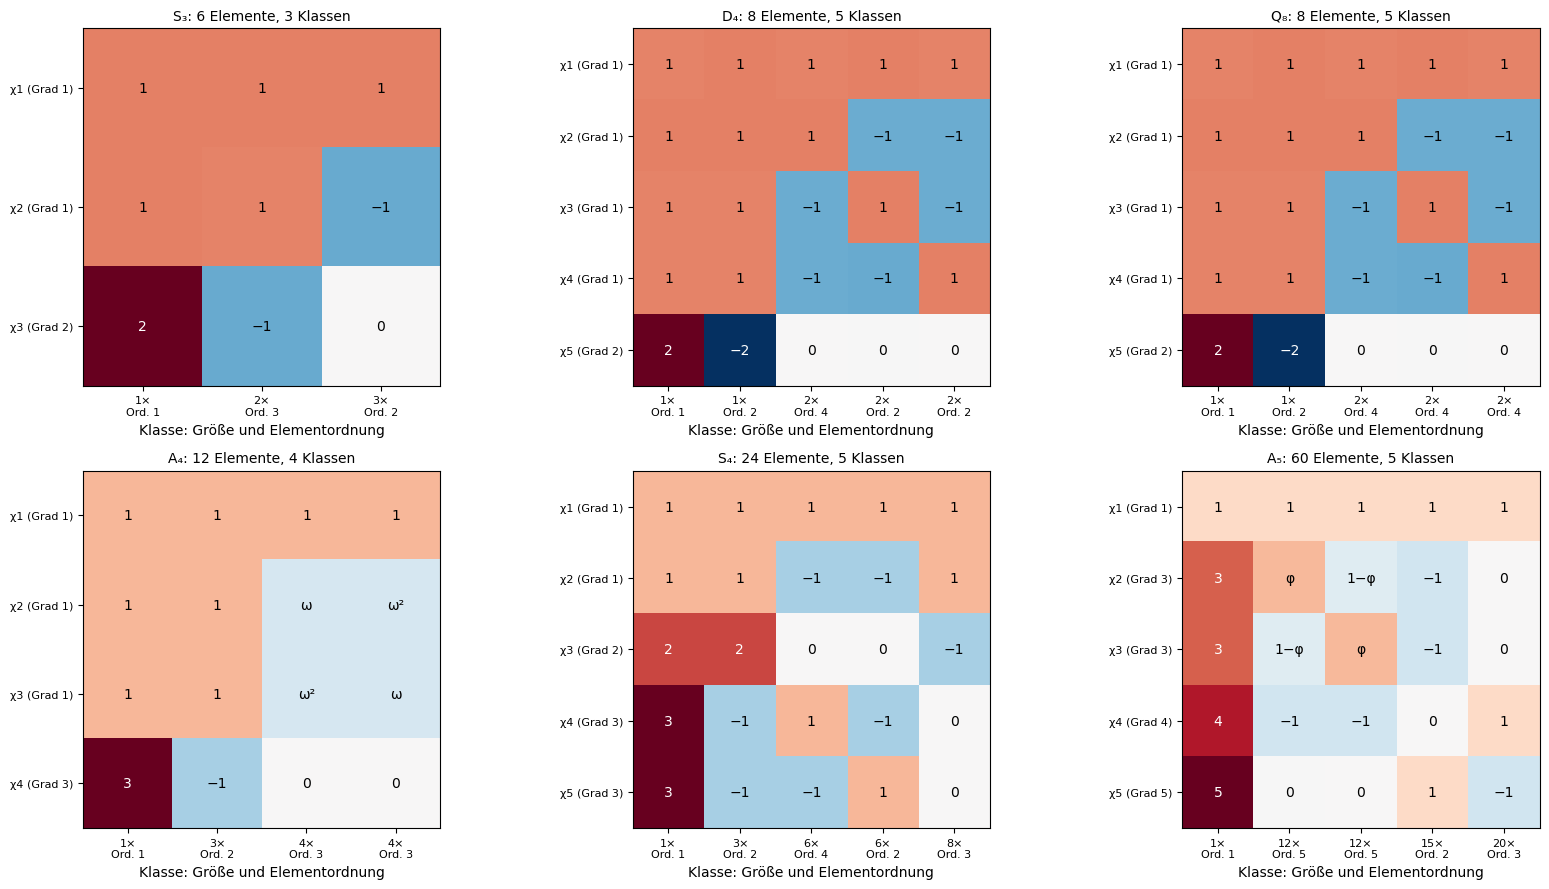

S₃: Grade [1, 1, 2], Σd² = 6 = |G| = 6, Grade teilen |G|: True, Zeilen orthonormal: True, Spalten orthogonal: True, Elemente der Ordnung 2: 3
D₄: Grade [1, 1, 1, 1, 2], Σd² = 8 = |G| = 8, Grade teilen |G|: True, Zeilen orthonormal: True, Spalten orthogonal: True, Elemente der Ordnung 2: 5
Q₈: Grade [1, 1, 1, 1, 2], Σd² = 8 = |G| = 8, Grade teilen |G|: True, Zeilen orthonormal: True, Spalten orthogonal: True, Elemente der Ordnung 2: 1
A₄: Grade [1, 1, 1, 3], Σd² = 12 = |G| = 12, Grade teilen |G|: True, Zeilen orthonormal: True, Spalten orthogonal: True, Elemente der Ordnung 2: 3
S₄: Grade [1, 1, 2, 3, 3], Σd² = 24 = |G| = 24, Grade teilen |G|: True, Zeilen orthonormal: True, Spalten orthogonal: True, Elemente der Ordnung 2: 9
A₅: Grade [1, 3, 3, 4, 5], Σd² = 60 = |G| = 60, Grade teilen |G|: True, Zeilen orthonormal: True, Spalten orthogonal: True, Elemente der Ordnung 2: 15
Tafeln von D₄ und Q₈ gleich: True
S₄ auf 4 Ecken     : Charakter [4, 0, 0, 2, 1], Vielfachheiten der irreduziblen 

In [11]:
def perm_group_data(G):
    els = list(G.generate())
    idx = {tuple(g.array_form): i for i, g in enumerate(els)}
    return els, (lambda i, j: idx[tuple((els[i] * els[j]).array_form)]), (lambda i: idx[tuple((~els[i]).array_form)])

def fmt_char(z):
    z = complex(z)
    gold = (1 + 5 ** 0.5) / 2
    named = {"ω": np.exp(2j * np.pi / 3), "ω²": np.exp(-2j * np.pi / 3), "φ": gold, "1−φ": 1 - gold, "i": 1j, "−i": -1j}
    for s, v in named.items():
        if abs(z - v) < 1e-8:
            return s
    if abs(z) < 1e-8:
        return "0"
    return f"{z.real:.0f}".replace("-", "−") if abs(z.imag) < 1e-8 and abs(z.real - round(z.real)) < 1e-8 else f"{z.real:.2f}"

Q8 = PermutationGroup([Permutation([[0, 1, 2, 3], [4, 5, 6, 7]]), Permutation([[0, 4, 2, 6], [1, 7, 3, 5]])])   # i und j als Permutationen
groups10 = {"S₃": SymmetricGroup(3), "D₄": DihedralGroup(4), "Q₈": Q8, "A₄": AlternatingGroup(4), "S₄": SymmetricGroup(4), "A₅": AlternatingGroup(5)}
tables10 = {}
for name, G in groups10.items():
    els, mul, inv = perm_group_data(G)
    chi, classes, sizes = character_table(len(els), mul, inv)
    orders = [els[c[0]].order() for c in classes]
    tables10[name] = (chi, classes, sizes, orders, els)

fig, axes = plt.subplots(2, 3, figsize=(17, 9))
for ax, (name, (chi, classes, sizes, orders, els)) in zip(axes.ravel(), tables10.items()):
    vmax = np.abs(chi.real).max()
    ax.imshow(chi.real, cmap="RdBu_r", vmin=-vmax, vmax=vmax)
    for i in range(chi.shape[0]):
        for j in range(chi.shape[1]):
            ax.text(j, i, fmt_char(chi[i, j]), ha="center", va="center", fontsize=10, color="white" if abs(chi[i, j].real) > 0.55 * vmax else "black")
    ax.set_xticks(range(len(sizes)), [f"{s}×\nOrd. {o}" for s, o in zip(sizes, orders)], fontsize=8)
    ax.set_yticks(range(len(sizes)), [f"χ{k + 1} (Grad {int(round(chi[k, 0].real))})" for k in range(len(sizes))], fontsize=8)
    ax.set_title(f"{name}: {len(els)} Elemente, {len(sizes)} Klassen", fontsize=10)
    ax.set_xlabel("Klasse: Größe und Elementordnung")
plt.tight_layout()
plt.show()

for name, (chi, classes, sizes, orders, els) in tables10.items():
    n_ = len(els)
    rows = (chi * sizes) @ chi.conj().T / n_
    cols = chi.conj().T @ chi
    dims_ = [int(round(d.real)) for d in chi[:, 0]]
    print(f"{name}: Grade {dims_}, Σd² = {sum(d * d for d in dims_)} = |G| = {n_}, Grade teilen |G|: {all(n_ % d == 0 for d in dims_)}, "
          f"Zeilen orthonormal: {np.allclose(rows, np.eye(len(sizes)))}, Spalten orthogonal: {np.allclose(cols, np.diag(n_ / sizes))}, "
          f"Elemente der Ordnung 2: {sum(g.order() == 2 for g in els)}")
print("Tafeln von D₄ und Q₈ gleich:", np.allclose(tables10["D₄"][0], tables10["Q₈"][0]))
chi4, cl4, sz4, _, els4 = tables10["S₄"]
reps4 = [els4[c[0]] for c in cl4]
perm_chars = {"4 Ecken": [sum(g(i) == i for i in range(4)) for g in reps4],
              "6 Kanten": [sum({g(a), g(b)} == {a, b} for a, b in itertools.combinations(range(4), 2)) for g in reps4],
              "regulär (24)": [24 if g.is_Identity else 0 for g in reps4]}
for lab, ch in perm_chars.items():
    m = np.real(np.round((chi4.conj() * sz4) @ np.array(ch) / 24, 6))
    print(f"S₄ auf {lab:12s}: Charakter {ch}, Vielfachheiten der irreduziblen (Grade {[int(round(d.real)) for d in chi4[:, 0]]}): {m.astype(int).tolist()}")

* Die **Bilder** zeigen die sechs Charaktertafeln. Die erste Zeile ist jeweils die triviale Darstellung (lauter Einsen), die erste Spalte die Klasse der Eins mit den Graden. Laut **Ausgabe** gilt für alle sechs Gruppen $\sum d_i^2 = \vert G\vert$, jeder Grad teilt $\vert G\vert$, die Zeilen sind orthonormal und die Spalten orthogonal. Das beantwortet die Vorhersage: $S_4$ hat 5 Klassen und damit 5 irreduzible Darstellungen mit den Graden 1, 1, 2, 3, 3 ($1 + 1 + 4 + 9 + 9 = 24$). Die beiden dreidimensionalen sind $S_4$ als Drehgruppe des Würfels und $S_4$ als Symmetriegruppe $T_d$ des Tetraeders (mit Spiegelungen).
* $D_4$ und $Q_8$ haben laut Ausgabe genau dieselbe Tafel, obwohl $D_4$ fünf Elemente der Ordnung 2 hat und $Q_8$ nur eines. In $A_4$ treten die dritten Einheitswurzeln $\omega$ und $\omega^2$ auf (zwei zueinander komplex konjugierte eindimensionale Darstellungen), in $A_5$ der goldene Schnitt $\varphi$ und $1 - \varphi$ auf den beiden Klassen der Fünferdrehungen. Die Ikosaedergruppe hat zwei dreidimensionale Darstellungen, die sich durch Vertauschen der Drehungen um 72° und um 144° unterscheiden.
* Die **Zerlegungen** der Permutationsdarstellungen von $S_4$: Auf den 4 Ecken ist sie die triviale plus die dreidimensionale Standarddarstellung, auf den 6 Kanten $1 + 2 + 3$, und die reguläre Darstellung enthält jede irreduzible so oft wie ihren Grad (1, 1, 2, 3, 3).
* **Wo es vorkommt:** Charaktertafeln stehen in jedem Lehrbuch der Chemie (Exp. 11) und der Festkörperphysik (Symmetrie von Bandstrukturen, Aufspaltung von d-Orbitalen im Kristallfeld), in der Wahrscheinlichkeitstheorie (Diaconis und Shahshahani bewiesen 1981 mit den Charakteren von $S_n$, dass zufällige Vertauschungen nach etwa $\tfrac12n\ln n$ Schritten mischen), in der Kombinatorik (Zählen mit Burnside) und in der Quanteninformation (Twirling und Randomized Benchmarking).

##### *11. Molekülschwingungen: IR- und Raman-Auswahlregeln aus der Charaktertafel*

Welche Schwingungen eines Moleküls sieht man im Infrarot-Spektrum, welche im Raman-Spektrum, und welche gar nicht? Vorher vorhersagen: $C_{60}$ hat $3\cdot60 - 6 = 174$ Schwingungen. Wie viele Linien erwartet man im IR-Spektrum?

Für Wasser, Ammoniak, Methan, Schwefelhexafluorid, Benzol und $C_{60}$ sucht der Code alle Symmetrieoperationen (wie in Exp. 12 des Notebooks Gruppentheorie), berechnet aus der Multiplikationstafel dieser $3\times3$-Matrizen die Charaktertafel der Punktgruppe und benennt die irreduziblen Darstellungen nach Mulliken. Dann zerlegt er die Darstellung auf den $3N$ Auslenkungen der Atome, zieht Verschiebungen und Drehungen des ganzen Moleküls ab und prüft für jede Schwingungsart, ob sie IR- oder Raman-aktiv ist. Links stehen die Zahlen der Linien, rechts die gemessenen Linien von $C_{60}$ (gerundete Literaturwerte).

**Hintergrund & Fachbegriffe:**
- **Normalschwingung:** eine Schwingung, bei der alle Atome mit derselben Frequenz schwingen; ein Molekül mit $N$ Atomen (nicht linear) hat $3N - 6$.
- **Punktgruppe:** die Symmetrieoperationen, die das Molekül auf sich abbilden und einen Punkt festlassen; Schoenflies-Symbole wie $C_{2v}$, $T_d$, $O_h$, $D_{6h}$, $I_h$.
- **Mulliken-Symbole:** A und B für eindimensionale Darstellungen (symmetrisch bzw. antisymmetrisch unter der Hauptdrehachse), E für zwei-, T für drei-, G für vier-, H für fünfdimensionale; Index g/u für gerade/ungerade unter der Inversion, Ziffern zur Unterscheidung.
- **IR-aktiv:** Die Schwingung ändert das Dipolmoment, sie absorbiert Infrarotlicht. **Raman-aktiv:** Sie ändert die Polarisierbarkeit und streut Licht mit verschobener Frequenz. **Stumm:** weder noch.
- **Wellenzahl** in $\mathrm{cm}^{-1}$: die übliche Einheit von Schwingungsfrequenzen in der Spektroskopie ($1\,\mathrm{cm}^{-1}\approx30\,\mathrm{GHz}$).

**Theorie:**

- **Darstellung der Auslenkungen:** Eine Symmetrieoperation $R$ bildet die Auslenkungen eines Atoms auf die eines anderen ab. Nur Atome, die $R$ festlässt, tragen zur Spur bei, jedes mit $\mathrm{tr}\,R$: $\chi_{3N}(R) = N_{\mathrm{fest}}(R)\cdot\mathrm{tr}\,R$. Verschiebungen transformieren wie ein Vektor ($\chi = \mathrm{tr}\,R$), Drehungen wie ein axialer Vektor ($\chi = \det R\cdot\mathrm{tr}\,R$). Die Schwingungen sind $\Gamma_{\mathrm{vib}} = \Gamma_{3N} - \Gamma_{\mathrm{trans}} - \Gamma_{\mathrm{rot}}$, zerlegt mit der Formel aus Abschnitt 5 der Theorie. Zu jeder irreduziblen Darstellung der Vielfachheit $m$ gehören $m$ verschiedene Frequenzen.
- **Auswahlregeln:** Die Übergangswahrscheinlichkeit ist ein Matrixelement $\langle1\vert O\vert0\rangle$ zwischen Grundzustand (total symmetrisch) und angeregtem Zustand (Typ $\Gamma$). Es kann nur dann von null verschieden sein, wenn $O$ eine Komponente vom Typ $\Gamma$ hat. Für IR ist $O$ das Dipolmoment, das wie $(x, y, z)$ transformiert; für Raman die Polarisierbarkeit, die wie die quadratischen Funktionen $x^2, xy, \dots$ transformiert (Charakter $(\chi(R)^2 + \chi(R^2))/2$ mit $\chi = \mathrm{tr}\,R$).
- **Alternativverbot:** Bei Molekülen mit Inversionszentrum ist $(x, y, z)$ ungerade (u) und $x^2, xy, \dots$ gerade (g). Keine Schwingung ist dann zugleich IR- und Raman-aktiv.
- **$C_{60}$:** Die Gruppe $I_h$ hat 120 Elemente und 10 irreduzible Darstellungen. Nur die 4 Schwingungen vom Typ $T_{1u}$ sind IR-aktiv. Die vier IR-Linien, die Krätschmer, Lamb, Fostiropoulos und Huffman 1990 maßen, waren ein Beleg für die Fußballstruktur.

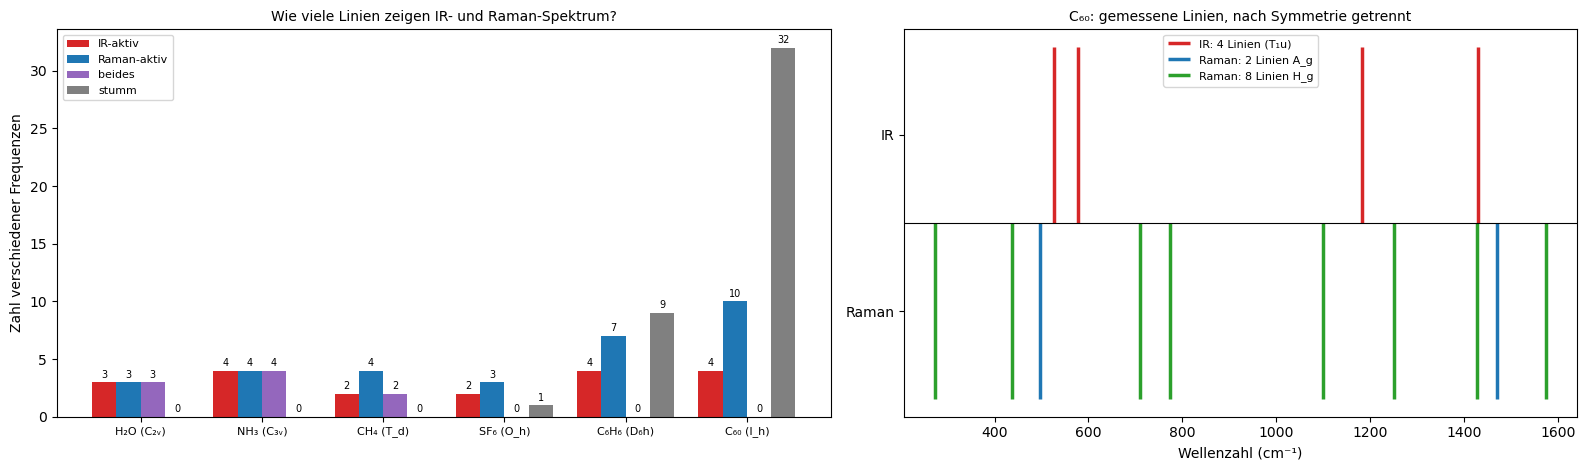

H₂O (C₂ᵥ)    Gruppe   4: Γ_vib = 2A₁ + B₂  (3 Schwingungen, 3 Frequenzen); IR: A₁, B₂; Raman: A₁, B₂
NH₃ (C₃ᵥ)    Gruppe   6: Γ_vib = 2A₁ + 2E  (6 Schwingungen, 4 Frequenzen); IR: A₁, E; Raman: A₁, E
CH₄ (T_d)    Gruppe  24: Γ_vib = A₁ + E + 2T₂  (9 Schwingungen, 4 Frequenzen); IR: T₂; Raman: A₁, E, T₂
SF₆ (O_h)    Gruppe  48: Γ_vib = A₁g + Eg + T₂g + 2T₁u + T₂u  (15 Schwingungen, 6 Frequenzen); IR: T₁u; Raman: A₁g, Eg, T₂g
C₆H₆ (D₆h)   Gruppe  24: Γ_vib = 2A₁g + A₂g + 2B₁u + 2B₂u + A₂u + 2B₂g + 4E₂g + 3E₁u + 2E₂u + E₁g  (30 Schwingungen, 20 Frequenzen); IR: A₂u, E₁u; Raman: A₁g, E₂g, E₁g
C₆₀ (I_h)    Gruppe 120: Γ_vib = 2Ag + Au + 3T₁g + 4T₂g + 4T₁u + 5T₂u + 6Gg + 6Gu + 8Hg + 7Hu  (174 Schwingungen, 46 Frequenzen); IR: T₁u; Raman: Ag, Hg

Charaktertafel von T_d, aus den Symmetrieoperationen von CH₄ berechnet:
            1E    3C2     6σ    6S4    8C3
A₁           1      1      1      1      1
A₂           1      1     −1     −1      1
E            2      2      0      0     −1
T₂    

In [12]:
def symmetry_ops(types, X, tol=1e-4):
    """Alle orthogonalen Abbildungen, die das Molekül auf sich abbilden (aus dem Notebook Gruppentheorie)."""
    X = X - X.mean(axis=0)
    idx = [i for i in range(len(X)) if np.linalg.norm(X[i]) > 1e-8]
    a = idx[0]
    b = next(j for j in idx if np.linalg.norm(np.cross(X[a], X[j])) > 1e-6)
    ops = []
    for a2, b2 in itertools.product(range(len(X)), repeat=2):
        if types[a2] != types[a] or types[b2] != types[b]:
            continue
        if abs(np.linalg.norm(X[a2]) - np.linalg.norm(X[a])) > tol or abs(np.linalg.norm(X[b2]) - np.linalg.norm(X[b])) > tol or abs(X[a2] @ X[b2] - X[a] @ X[b]) > tol:
            continue
        Fm = np.c_[X[a], X[b], np.cross(X[a], X[b])]
        for sgn in (1, -1):
            R = np.c_[X[a2], X[b2], sgn * np.cross(X[a2], X[b2])] @ np.linalg.inv(Fm)
            dist = np.linalg.norm((X @ R.T)[:, None, :] - X[None, :, :], axis=2)
            j = dist.argmin(axis=1)
            if dist[np.arange(len(X)), j].max() < tol and all(types[i] == types[k] for i, k in enumerate(j)) and not any(np.allclose(R, S, atol=1e-6) for S in ops):
                ops.append(R)
    return ops

def elem_order(R):
    P, k = R.copy(), 1
    while not np.allclose(P, np.eye(3), atol=1e-6):
        P, k = P @ R, k + 1
    return k

def fixed_axis(R, ev):
    w, v = np.linalg.eig(R)
    return np.real(v[:, np.argmin(np.abs(w - ev))])

def class_name(R):
    if np.linalg.det(R) > 0:
        return "E" if np.allclose(R, np.eye(3)) else f"C{elem_order(R)}"
    if np.allclose(R, -np.eye(3)):
        return "i"
    return "σ" if np.isclose(np.trace(R), 1) else f"S{elem_order(R)}"

def mulliken(chi, reps, sizes, Xc):
    """Mulliken-Symbole nach den Regeln der Spektroskopie (Hauptachse, Inversion, C₂ senkrecht durch Atome, σ_v, C₄/S₄, C₅)."""
    det = [np.linalg.det(R) for R in reps]
    order = [elem_order(R) for R in reps]
    proper = [k for k in range(len(reps)) if det[k] > 0]
    n_max = max(order[k] for k in proper)
    principal = next(k for k in proper if order[k] == n_max and np.isclose(np.trace(reps[k]), 1 + 2 * np.cos(2 * np.pi / n_max)))
    cubic = sum(sizes[k] for k in proper if order[k] == 3) >= 8
    inv = next((k for k in range(len(reps)) if np.allclose(reps[k], -np.eye(3))), None)
    ord4 = next((k for k in range(len(reps)) if order[k] == 4), None)
    c5 = next((k for k in proper if order[k] == 5 and np.trace(reps[k]) > 1.5), None)
    ax_ = fixed_axis(reps[principal], 1)
    def atoms_on(k):
        if det[k] > 0:
            a = fixed_axis(reps[k], 1)
            return sum(np.linalg.norm(np.cross(p, a)) < 1e-3 and np.linalg.norm(p) > 1e-3 for p in Xc)
        return sum(abs(p @ fixed_axis(reps[k], -1)) < 1e-3 for p in Xc)
    c2perp = [k for k in proper if order[k] == 2 and abs(fixed_axis(reps[k], 1) @ ax_) < 1e-6]
    sig_v = [k for k in range(len(reps)) if det[k] < 0 and np.isclose(np.trace(reps[k]), 1) and abs(fixed_axis(reps[k], -1) @ ax_) < 1e-6]
    ref = ord4 if cubic else (max(c2perp, key=atoms_on) if c2perp else (min(sig_v, key=atoms_on) if sig_v else None))
    labels = []
    for row in chi:
        d = int(round(row[0].real))
        letter = ("A" if cubic or np.isclose(row[principal].real, 1) else "B") if d == 1 else {2: "E", 3: "T", 4: "G", 5: "H"}[d]
        labels.append([letter, "", "" if inv is None else ("g" if row[inv].real > 0 else "u")])
    for t, row in enumerate(chi):
        L, _, par = labels[t]
        same = [s for s in range(len(chi)) if labels[s][0] == L and labels[s][2] == par]
        if len(same) < 2:
            continue
        if L == "E":
            labels[t][1] = str(int(round(np.arccos(np.clip(row[principal].real / 2, -1, 1)) * n_max / (2 * np.pi))))
        elif L == "T":
            labels[t][1] = "1" if (row[ord4].real > 0 if ord4 is not None else row[c5].real > 0) else "2"
        else:
            labels[t][1] = ("1" if row[ref].real > 0 else "2") if ref is not None else str(same.index(t) + 1)
    sub = str.maketrans("0123456789", "₀₁₂₃₄₅₆₇₈₉")
    return [L + s.translate(sub) + p for L, s, p in labels]

def vibrations(types, X):
    X = np.array(X, float)
    ops = symmetry_ops(types, X)
    key = lambda R: tuple(np.round(R, 5).ravel() + 0.0)
    index = {key(R): i for i, R in enumerate(ops)}
    chi, classes, sizes = character_table(len(ops), lambda i, j: index[key(ops[i] @ ops[j])], lambda i: index[key(ops[i].T)])
    reps = [ops[c[0]] for c in classes]
    Xc = X - X.mean(axis=0)
    labels = mulliken(chi, reps, sizes, Xc)
    fixed = np.array([sum(np.linalg.norm(R @ p - p) < 1e-4 for p in Xc) for R in reps])
    trR = np.array([np.trace(R) for R in reps]); detR = np.array([np.linalg.det(R) for R in reps])
    mult = lambda gam: np.rint(np.real((chi.conj() * sizes) @ gam / len(ops))).astype(int)
    vib = mult(fixed * trR - trR - detR * trR)
    ir = mult(trR) > 0
    raman = mult((trR ** 2 + np.array([np.trace(R @ R) for R in reps])) / 2) > 0
    return dict(group=len(ops), chi=chi, sizes=sizes, reps=reps, labels=labels, vib=vib, ir=ir, raman=raman)

gold = (1 + 5 ** 0.5) / 2
def buckyball():
    pts = set()
    for v in [(0, 1, 3 * gold), (1, 2 + gold, 2 * gold), (gold, 2, gold ** 3)]:
        for sh in range(3):
            w = v[sh:] + v[:sh]
            for sg in itertools.product([1, -1], repeat=3):
                pts.add(tuple(round(s * x, 9) for s, x in zip(sg, w)))
    return (np.array(sorted(pts)) * 0.7).tolist()
ringpts = lambda r, k: [[r * np.cos(2 * np.pi * i / k), r * np.sin(2 * np.pi * i / k), 0] for i in range(k)]
molecules11 = {
    "H₂O (C₂ᵥ)": (["O", "H", "H"], [[0, 0, 0.117], [0.757, 0, -0.469], [-0.757, 0, -0.469]]),
    "NH₃ (C₃ᵥ)": (["N", "H", "H", "H"], [[0, 0, 0.38]] + ringpts(0.94, 3)),
    "CH₄ (T_d)": (["C"] + ["H"] * 4, (np.array([[0, 0, 0], [1, 1, 1], [1, -1, -1], [-1, 1, -1], [-1, -1, 1]]) * 0.63).tolist()),
    "SF₆ (O_h)": (["S"] + ["F"] * 6, [[0, 0, 0], [1.56, 0, 0], [-1.56, 0, 0], [0, 1.56, 0], [0, -1.56, 0], [0, 0, 1.56], [0, 0, -1.56]]),
    "C₆H₆ (D₆h)": (["C"] * 6 + ["H"] * 6, ringpts(1.39, 6) + ringpts(2.48, 6)),
    "C₆₀ (I_h)": (["C"] * 60, buckyball()),
}
vib11 = {name: vibrations(*m) for name, m in molecules11.items()}
c60_ir = [527, 577, 1183, 1429]                                       # T₁u (Krätschmer et al. 1990)
c60_raman = {"A_g": [496, 1470], "H_g": [273, 437, 710, 774, 1099, 1250, 1428, 1575]}   # Bethune et al. 1991

fig, axes = plt.subplots(1, 2, figsize=(16, 4.8), gridspec_kw={"width_ratios": [1.15, 1]})
ax = axes[0]
cats = ["IR-aktiv", "Raman-aktiv", "beides", "stumm"]
counts11 = {}
for name, r in vib11.items():
    v, ir, ra = r["vib"], r["ir"], r["raman"]
    counts11[name] = [int(v[ir].sum()), int(v[ra].sum()), int(v[ir & ra].sum()), int(v[~ir & ~ra].sum())]
xpos = np.arange(len(vib11))
for k, (cat, c) in enumerate(zip(cats, ("C3", "C0", "C4", "grey"))):
    vals = [counts11[n][k] for n in vib11]
    ax.bar(xpos + (k - 1.5) * 0.2, vals, 0.2, color=c, label=cat)
    for x_, v_ in zip(xpos, vals):
        ax.text(x_ + (k - 1.5) * 0.2, v_ + 0.4, str(v_), ha="center", fontsize=7)
ax.set_xticks(xpos, list(vib11), fontsize=8)
ax.set_ylabel("Zahl verschiedener Frequenzen")
ax.set_title("Wie viele Linien zeigen IR- und Raman-Spektrum?", fontsize=10)
ax.legend(fontsize=8)
ax = axes[1]
ax.vlines(c60_ir, 0, 1, color="C3", lw=2.5, label="IR: 4 Linien (T₁u)")
ax.vlines(c60_raman["A_g"], -1, 0, color="C0", lw=2.5, label="Raman: 2 Linien A_g")
ax.vlines(c60_raman["H_g"], -1, 0, color="C2", lw=2.5, label="Raman: 8 Linien H_g")
ax.axhline(0, color="k", lw=0.8)
ax.set_yticks([-0.5, 0.5], ["Raman", "IR"])
ax.set_xlabel("Wellenzahl (cm⁻¹)")
ax.set_title("C₆₀: gemessene Linien, nach Symmetrie getrennt", fontsize=10)
ax.legend(fontsize=8, loc="upper center")
plt.tight_layout()
plt.show()

for name, r in vib11.items():
    terms = " + ".join(f"{m if m > 1 else ''}{l}" for l, m in zip(r["labels"], r["vib"]) if m > 0)
    modes = int(sum(m * round(c[0].real) for m, c in zip(r["vib"], r["chi"])))
    act = lambda mask: ", ".join(l for l, m, a in zip(r["labels"], r["vib"], mask) if a and m > 0)
    print(f"{name:12s} Gruppe {r['group']:3d}: Γ_vib = {terms}  ({modes} Schwingungen, {int(r['vib'].sum())} Frequenzen); IR: {act(r['ir'])}; Raman: {act(r['raman'])}")
td = vib11["CH₄ (T_d)"]
print("\nCharaktertafel von T_d, aus den Symmetrieoperationen von CH₄ berechnet:")
print("       " + "".join(f"{f'{s}{class_name(R)}':>7s}" for s, R in zip(td["sizes"], td["reps"])))
for lab, row in zip(td["labels"], td["chi"]):
    print(f"{lab:6s} " + "".join(f"{fmt_char(v):>7s}" for v in row))
print(f"\nC₆₀: Raman-Linien {sorted(c60_raman['A_g'] + c60_raman['H_g'])}, IR-Linien {c60_ir}; dieselbe Wellenzahl in beiden Listen: {sorted(set(c60_ir) & set(c60_raman['A_g'] + c60_raman['H_g']))}")

* **Links** stehen die Zahlen verschiedener Frequenzen. Wasser hat drei Schwingungen ($2A_1 + B_2$), alle IR- und Raman-aktiv; bei Ammoniak ($2A_1 + 2E$) ebenso. Methan ($A_1 + E + 2T_2$) hat 9 Schwingungen, aber nur 4 verschiedene Frequenzen, 2 davon im IR- ($T_2$) und alle 4 im Raman-Spektrum. Bei den Molekülen mit Inversionszentrum ($SF_6$, Benzol, $C_{60}$) ist die Spalte „beides“ leer: das Alternativverbot. Benzol hat 30 Schwingungen auf 20 Frequenzen, davon 4 im IR- und 7 im Raman-Spektrum, 9 sind stumm; $SF_6$ hat eine stumme ($T_{2u}$).
* $C_{60}$ hat laut **Ausgabe** $\Gamma_{\mathrm{vib}} = 2A_g + A_u + 3T_{1g} + 4T_{2g} + 4T_{1u} + 5T_{2u} + 6G_g + 6G_u + 8H_g + 7H_u$: 174 Schwingungen auf nur 46 Frequenzen, davon 4 im IR- und 10 im Raman-Spektrum, 32 stumm. Das beantwortet die Vorhersage: 4 IR-Linien. **Rechts** stehen die gemessenen Linien: genau 4 im IR (527, 577, 1183, 1429 cm⁻¹) und 10 im Raman-Spektrum, keine Wellenzahl in beiden Listen; 1428 und 1429 cm⁻¹ liegen nahe beieinander, gehören aber zu verschiedenen Schwingungen ($H_g$ und $T_{1u}$). Die berechnete Tafel von $T_d$ in der Ausgabe ist die aus den Chemiebüchern.
* **Wo es vorkommt:** Die Zuordnung von IR- und Raman-Spektren ist Routine in der analytischen Chemie, der Materialforschung und der Pharmazie (Identifizierung von Substanzen, Kristallformen von Wirkstoffen), in der Astronomie (die IR-Banden von $C_{60}$ wurden 2010 mit dem Spitzer-Teleskop im planetarischen Nebel Tc 1 gefunden, und $C_{60}^+$ erklärt zwei der diffusen interstellaren Banden) und bei Halbleitern (Raman-Spektroskopie an Silizium und Graphen). Dieselbe Rechnung liefert die Aufspaltung von Orbitalen im Kristallfeld (Farben von Edelsteinen und Komplexen) und die Auswahlregeln für Phononen in Kristallen.

##### *12. Spin j: die irreduziblen Darstellungen von SU(2)*

Wie sehen die irreduziblen Darstellungen der Drehgruppe aus, und was misst ein Stern-Gerlach-Versuch an einem gedrehten Spin? Vorher vorhersagen: Ein Spin $j = 10$ zeigt in $z$-Richtung ($m = 10$) und wird um 60° um die $y$-Achse gedreht. Welcher Wert von $m$ ist bei einer Messung entlang $z$ am wahrscheinlichsten?

Der Code baut für $j = \tfrac12, 1, \tfrac32, 2, 5$ die Spinmatrizen aus den Leiteroperatoren, prüft die Vertauschungsrelationen und den Casimir-Operator und berechnet die Wigner-d-Matrizen $d^j(\beta) = e^{-i\beta J_y}$, die er für $j\leq2$ mit sympy vergleicht. Links steht $\vert d^{10}_{mm'}(\pi/2)\vert^2$, die Wahrscheinlichkeit, nach einer Drehung um 90° von $m'$ nach $m$ zu kommen; in der Mitte die Stern-Gerlach-Verteilung des gedrehten Spins mit der Binomialverteilung; rechts die Charaktere $\chi_j(\theta)$ über zwei volle Umdrehungen.

**Hintergrund & Fachbegriffe:**
- **Spin $j$:** die irreduzible Darstellung von $\mathfrak{su}(2)$ der Dimension $2j + 1$; Basis $\vert j, m\rangle$ mit $J_z\vert j, m\rangle = m\vert j, m\rangle$.
- **Leiteroperatoren** $J_\pm = J_x\pm iJ_y$: $J_+\vert j, m\rangle = \sqrt{j(j + 1) - m(m + 1)}\,\vert j, m + 1\rangle$.
- **Casimir-Operator** $J^2 = J_x^2 + J_y^2 + J_z^2$: vertauscht mit allen $J_a$ und ist auf Spin $j$ gleich $j(j + 1)$.
- **Wigner-D-Matrix:** die Matrix der Drehung $e^{-i\alpha J_z}e^{-i\beta J_y}e^{-i\gamma J_z}$ in der Spin-$j$-Darstellung; **d-Matrix:** der Teil $e^{-i\beta J_y}$.
- **Stern-Gerlach-Versuch:** Ein inhomogenes Magnetfeld trennt einen Atomstrahl nach dem Wert von $m$; die Häufigkeiten sind $\vert\langle m\vert\psi\rangle\vert^2$.
- **Weyl-Integrationsformel:** Für Klassenfunktionen auf $SU(2)$ hat der Winkel $\theta$ (Eigenwerte $e^{\pm i\theta/2}$) die Haar-Dichte $\frac1\pi\sin^2(\theta/2)$ auf $[0, 2\pi]$.

**Theorie:**

- **Konstruktion:** Aus $[J_z, J_\pm] = \pm J_\pm$ folgt, dass $J_\pm$ Eigenwerte von $J_z$ um 1 verschieben. Eine endlichdimensionale Darstellung braucht einen höchsten Wert $m = j$ mit $J_+\vert j\rangle = 0$; absteigend erreicht man $m = -j$, also ist $2j$ eine ganze Zahl. Das ist das Muster jeder Darstellungstheorie halbeinfacher Lie-Algebren: höchstes Gewicht plus absteigende Operatoren.
- **Halbzahliger Spin:** $e^{-2\pi iJ_z}$ ist $(-1)^{2j}$: Für halbzahliges $j$ ist die Drehung um 360° gleich $-1$. Das ist eine Darstellung von $SU(2)$, aber nicht von $SO(3)$; erst 720° ergeben die Eins.
- **Gedrehter Spin:** $\vert j, j\rangle$ ist ein Spin, der so genau wie möglich in $z$-Richtung zeigt (ein **Spin-kohärenter Zustand**); um $\beta$ gedreht, ist die Verteilung von $m$ binomial: $P(m) = \binom{2j}{j + m}\cos^{2(j+m)}(\beta/2)\sin^{2(j-m)}(\beta/2)$, als bestünde er aus $2j$ unabhängigen Spins $\tfrac12$. Der Mittelwert ist $j\cos\beta$.
- **Charaktere:** $\chi_j(\theta) = \sum_{m=-j}^je^{im\theta} = \frac{\sin((2j + 1)\theta/2)}{\sin(\theta/2)}$ (Weylsche Charakterformel für $SU(2)$); sie sind orthonormal bezüglich der Weyl-Dichte (Peter-Weyl).

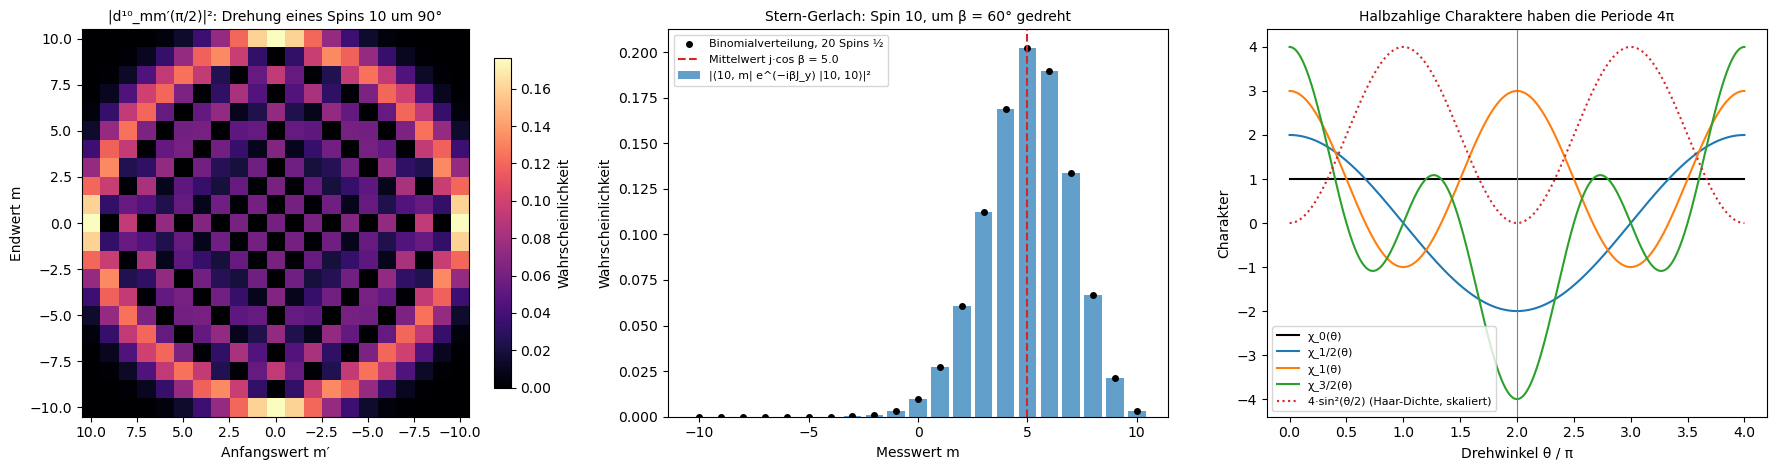

  j  dim  |[Jx,Jy] − iJz|   |J² − j(j+1)|   e^(−2πiJz)   |d − sympy|
 0.5    2         0.0e+00         0.0e+00          -1   5.6e-17
 1.0    3         2.2e-16         4.4e-16          +1   1.7e-16
 1.5    4         2.2e-16         0.0e+00          -1   1.1e-16
 2.0    5         5.6e-16         8.9e-16          +1   1.7e-16
 5.0   11         4.0e-15         3.6e-15          +1   –
Stern-Gerlach: wahrscheinlichstes m = 5 (P = 0.202), Mittelwert 5.0000, |P − Binomial| ≤ 1.4e-16
Charaktere χ_j, j = 0 … 3, orthonormal mit der Dichte sin²(θ/2)/π: größte Abweichung von der Einheitsmatrix 8.0e-15


In [13]:
spin_checks = []
for j in (0.5, 1, 1.5, 2, 5):
    Jx, Jy, Jz, Jp = spin_matrices(j)
    d = 2 * j + 1
    c1 = np.abs(comm(Jx, Jy) - 1j * Jz).max()
    c2 = np.abs(Jx @ Jx + Jy @ Jy + Jz @ Jz - j * (j + 1) * np.eye(int(d))).max()
    rot2pi = np.real(np.diag(expm(-2j * np.pi * Jz)))[0]
    if j <= 2:
        beta = 0.7
        ms = np.arange(j, -j - 1, -1)
        R_ = lambda q: Rational(int(round(2 * q)), 2)
        dsym = np.array([[complex(Rotation.d(R_(j), R_(a), R_(b), beta).doit().evalf()) for b in ms] for a in ms])
        derr = np.abs(expm(-1j * beta * Jy) - dsym).max()
    else:
        derr = np.nan
    spin_checks.append((j, int(d), c1, c2, rot2pi, derr))

j12 = 10
Jx, Jy, Jz, Jp = spin_matrices(j12)
m12 = np.arange(j12, -j12 - 1, -1)
d_half = np.abs(expm(-1j * np.pi / 2 * Jy)) ** 2
beta12 = np.pi / 3
psi12 = expm(-1j * beta12 * Jy)[:, 0]                     # Spalte von |j, j⟩
p_sg = np.abs(psi12) ** 2
p_binom = np.array([comb(2 * j12, int(j12 + m)) * np.cos(beta12 / 2) ** (2 * (j12 + m)) * np.sin(beta12 / 2) ** (2 * (j12 - m)) for m in m12])
th12 = np.linspace(1e-4, 4 * np.pi - 1e-4, 1000)
chi_j = lambda j, th: np.sin((2 * j + 1) * th / 2) / np.sin(th / 2)
xg, wg = np.polynomial.legendre.leggauss(200)
thq = np.pi * (xg + 1); wq = np.pi * wg
jlist = [0, 0.5, 1, 1.5, 2, 2.5, 3]
orth12 = np.array([[np.sum(wq * chi_j(a, thq) * chi_j(b, thq) * np.sin(thq / 2) ** 2 / np.pi) for b in jlist] for a in jlist])

fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
ax = axes[0]
im = ax.imshow(d_half, cmap="magma", extent=[j12 + 0.5, -j12 - 0.5, -j12 - 0.5, j12 + 0.5])
ax.set_xlabel("Anfangswert m′")
ax.set_ylabel("Endwert m")
ax.set_title("|d¹⁰_mm′(π/2)|²: Drehung eines Spins 10 um 90°", fontsize=10)
plt.colorbar(im, ax=ax, shrink=0.85, label="Wahrscheinlichkeit")
ax = axes[1]
ax.bar(m12, p_sg, width=0.8, alpha=0.7, label="|⟨10, m| e^(−iβJ_y) |10, 10⟩|²")
ax.plot(m12, p_binom, "ko", ms=4, label="Binomialverteilung, 20 Spins ½")
ax.axvline(j12 * np.cos(beta12), color="C3", ls="--", label=f"Mittelwert j·cos β = {j12 * np.cos(beta12):.1f}")
ax.set_xlabel("Messwert m")
ax.set_ylabel("Wahrscheinlichkeit")
ax.set_title("Stern-Gerlach: Spin 10, um β = 60° gedreht", fontsize=10)
ax.legend(fontsize=8)
ax = axes[2]
for j, c in zip((0, 0.5, 1, 1.5), ("k", "C0", "C1", "C2")):
    ax.plot(th12 / np.pi, chi_j(j, th12), color=c, label=f"χ_{Fraction(j)}(θ)")
ax.plot(th12 / np.pi, 4 * np.sin(th12 / 2) ** 2, "C3:", label="4·sin²(θ/2) (Haar-Dichte, skaliert)")
ax.axvline(2, color="grey", lw=0.8)
ax.set_xlabel("Drehwinkel θ / π")
ax.set_ylabel("Charakter")
ax.set_title("Halbzahlige Charaktere haben die Periode 4π", fontsize=10)
ax.legend(fontsize=8, loc="lower left")
plt.tight_layout()
plt.show()

print("  j  dim  |[Jx,Jy] − iJz|   |J² − j(j+1)|   e^(−2πiJz)   |d − sympy|")
for j, d, c1, c2, r2, de in spin_checks:
    print(f"{j:4.1f} {d:4d}  {c1:14.1e}  {c2:14.1e}  {r2:+10.0f}   {'–' if np.isnan(de) else f'{de:.1e}'}")
print(f"Stern-Gerlach: wahrscheinlichstes m = {int(m12[np.argmax(p_sg)])} (P = {p_sg.max():.3f}), Mittelwert {np.sum(m12 * p_sg):.4f}, |P − Binomial| ≤ {np.abs(p_sg - p_binom).max():.1e}")
print(f"Charaktere χ_j, j = 0 … 3, orthonormal mit der Dichte sin²(θ/2)/π: größte Abweichung von der Einheitsmatrix {np.abs(orth12 - np.eye(len(jlist))).max():.1e}")

* **Links** steht $\vert d^{10}_{mm'}(\pi/2)\vert^2$: Nach einer Drehung um 90° verteilt sich ein Zustand mit festem $m'$ auf viele $m$. Die hellen Ränder liegen auf dem Kreis $m^2 + m'^2\approx j^2$; dort häufen sich die klassischen Bahnen eines Kreisels mit Drehimpulskomponente $m'$ (nach der Drehung liegt seine $z$-Komponente zwischen $\pm\sqrt{j^2 - m'^2}$). Das Schachbrettmuster im Inneren ist Interferenz.
* In der **Mitte** ist die Stern-Gerlach-Verteilung des um 60° gedrehten Spins $\vert10, 10\rangle$ genau binomial (Abweichung $1.4\cdot10^{-16}$ laut **Ausgabe**), mit Maximum bei $m = 5$ (Wahrscheinlichkeit 0.202) und Mittelwert $j\cos\beta = 5$. Das beantwortet die Vorhersage. Der Spin 10 verhält sich wie 20 unabhängige Spins $\tfrac12$, die alle in dieselbe Richtung zeigen.
* **Rechts** haben die Charaktere der ganzzahligen Spins ($\chi_0$, $\chi_1$) die Periode $2\pi$, die der halbzahligen ($\chi_{1/2}$, $\chi_{3/2}$) erst $4\pi$; bei $\theta = 2\pi$ sind sie $-2$ und $-4$, also $-(2j + 1)$: Die Drehung um 360° ist $-1$. Laut Ausgabe sind die Charaktere für $j = 0$ bis 3 mit der Dichte $\sin^2(\theta/2)/\pi$ orthonormal (Abweichung $8\cdot10^{-15}$), für alle geprüften $j$ gelten $[J_x, J_y] = iJ_z$ und $J^2 = j(j + 1)$, und die d-Matrizen stimmen mit sympy auf $2\cdot10^{-16}$.
* **Wo es vorkommt:** Spin-Darstellungen beschreiben Elektronen- und Kernspins (NMR und MRT drehen Spins mit Hochfrequenzpulsen), die Feinstruktur von Atomen, Rotationsspektren von Molekülen, Multipolentwicklungen in Elektrodynamik, Gravitationswellen und kosmischer Hintergrundstrahlung (Kugelflächenfunktionen drehen sich mit $D^l$) und äquivariante neuronale Netze für 3D-Daten, deren Merkmale in Spin-$l$-Darstellungen liegen und mit Wigner-D-Matrizen gedreht werden (e3nn, NequIP, MACE).

##### *13. Clebsch-Gordan-Koeffizienten, Wigner-Eckart und die Auswahlregeln der Atomphysik*

Was entsteht, wenn man zwei Drehimpulse koppelt, und warum strahlt ein Atom nur bei $\Delta l = \pm1$? Vorher vorhersagen: In welche Spins zerfällt $1\otimes1$, und welche Übergänge zwischen $s$-, $p$-, $d$- und $f$-Orbitalen ($l = 0$ bis 3) erlaubt der Dipoloperator $z = r\cos\theta$?

Der Code berechnet die Clebsch-Gordan-Koeffizienten selbst: Er beginnt beim höchsten Zustand $\vert j_1, j_1\rangle\otimes\vert j_2, j_2\rangle$, steigt mit $J_- = J_-^{(1)} + J_-^{(2)}$ ab und orthogonalisiert für jedes kleinere $J$ (Phase nach Condon-Shortley), und vergleicht mit sympy. Dann werden die Winkelanteile der Dipol-Matrixelemente $\langle l'm'\vert\cos\theta\vert lm\rangle$ und $\langle l'm'\vert\sin\theta\,e^{i\varphi}\vert lm\rangle$ für $l, l'\leq3$ durch Quadratur über die Kugel berechnet, mit Kugelflächenfunktionen aus `scipy.special.lpmv`. Links steht die Clebsch-Gordan-Matrix von $1\otimes1$, in der Mitte die Dipol-Matrixelemente, rechts der Test des Wigner-Eckart-Theorems.

**Hintergrund & Fachbegriffe:**
- **Gekoppelte und ungekoppelte Basis:** $\vert j_1m_1\rangle\otimes\vert j_2m_2\rangle$ gegen $\vert JM\rangle$ mit Gesamtdrehimpuls $\vec J = \vec J_1 + \vec J_2$.
- **Clebsch-Gordan-Koeffizient** $\langle j_1m_1; j_2m_2\vert JM\rangle$: die Einträge des Basiswechsels; null außer für $M = m_1 + m_2$ und $\vert j_1 - j_2\vert\leq J\leq j_1 + j_2$.
- **Condon-Shortley-Konvention:** Phasenwahl, nach der $\langle j_1j_1; j_2, J - j_1\vert JJ\rangle > 0$ ist; alle Koeffizienten sind dann reell.
- **Kugelflächenfunktionen** $Y_l^m(\theta, \varphi)$: die Basis des Spin-$l$-Anteils der Funktionen auf der Kugel, die Winkelteile der Atomorbitale ($s, p, d, f$ für $l = 0, 1, 2, 3$).
- **Tensoroperator vom Rang $k$:** ein Satz von $2k + 1$ Operatoren, die sich unter Drehungen wie $Y_k^q$ transformieren; der Ort $\vec r$ ist einer vom Rang 1 ($z\propto Y_1^0$, $x\pm iy\propto Y_1^{\pm1}$).
- **Dipolübergang:** Emission oder Absorption von Licht durch das elektrische Dipolmoment $e\vec r$, der stärkste Strahlungsprozess in Atomen.

**Theorie:**

- **Kopplung:** $V_{j_1}\otimes V_{j_2} = \bigoplus_{J=\vert j_1 - j_2\vert}^{j_1 + j_2}V_J$, Dimensionsprobe $(2j_1 + 1)(2j_2 + 1) = \sum_J(2J + 1)$. Für zwei Spins $\tfrac12$: Triplett ($J = 1$) und Singulett ($J = 0$); für $1\otimes1$: $2\oplus1\oplus0$.
- **Wigner-Eckart-Theorem:** $\langle j'm'\vert T^k_q\vert jm\rangle = \langle jm; kq\vert j'm'\rangle\cdot\langle j'\Vert T^k\Vert j\rangle$; die ganze Abhängigkeit von $m, m', q$ steckt im Clebsch-Gordan-Koeffizienten, die Physik im **reduzierten Matrixelement**, das von $m$ nicht abhängt.
- **Dipol-Auswahlregeln:** Für $k = 1$ ist das Matrixelement nur dann ungleich null, wenn $\vert l - 1\vert\leq l'\leq l + 1$ und $m' = m + q$. Die Parität von $Y_l^m$ ist $(-1)^l$ und $\vec r$ ist ungerade, deshalb fällt $l' = l$ weg: $\Delta l = \pm1$, $\Delta m = 0$ (Licht polarisiert entlang $z$) oder $\pm1$ (zirkular polarisiert).
- **Folgen:** Der Übergang $2p\to1s$ in Wasserstoff (Lyman-$\alpha$) ist erlaubt, Lebensdauer etwa 1.6 ns; $2s\to1s$ ist für Dipolstrahlung verboten, und der $2s$-Zustand zerfällt hauptsächlich durch Emission zweier Photonen, mit etwa 0.12 s Lebensdauer.

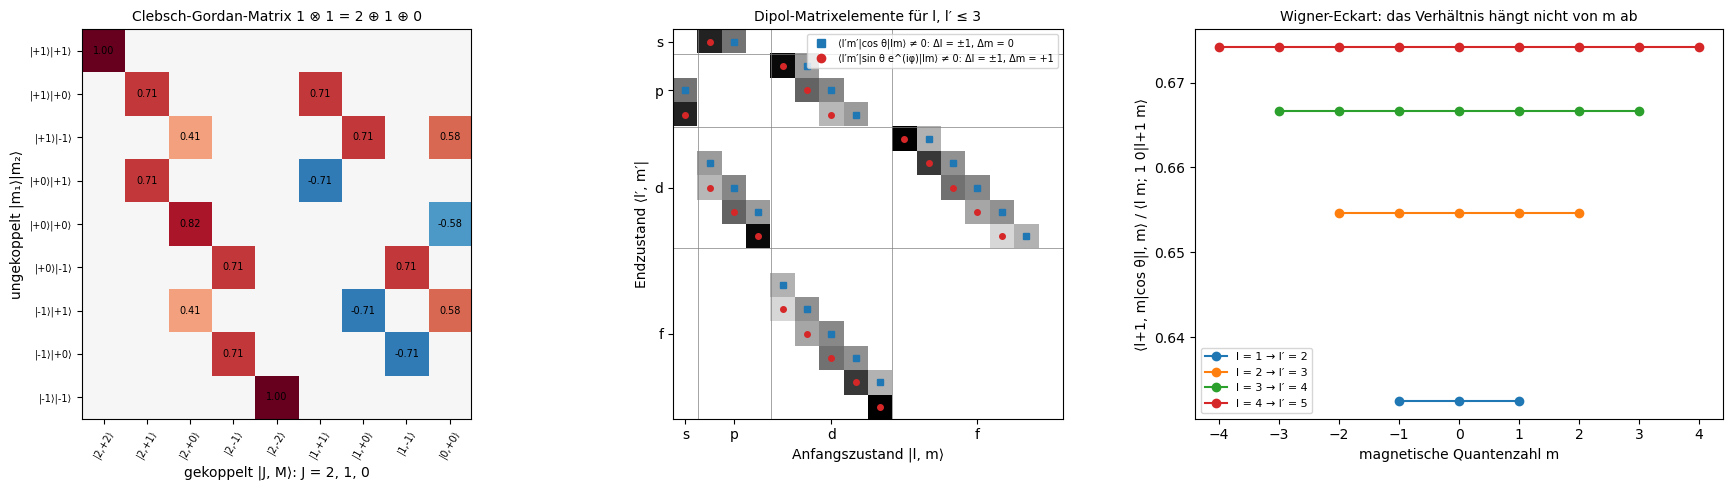

1/2 ⊗ 1/2: 4 Zustände = Σ(2J+1) über J = 0, 1;  größte Abweichung von sympy 1.1e-16
1 ⊗ 1: 9 Zustände = Σ(2J+1) über J = 0, 1, 2;  größte Abweichung von sympy 1.4e-16
3/2 ⊗ 1: 12 Zustände = Σ(2J+1) über J = 1/2, 3/2, 5/2;  größte Abweichung von sympy 3.3e-16
2 ⊗ 3/2: 20 Zustände = Σ(2J+1) über J = 1/2, 3/2, 5/2, 7/2;  größte Abweichung von sympy 6.7e-16
Kugelflächenfunktionen bis l = 3 orthonormal (Quadratur): True
cos θ: 18 von 256 Matrixelementen ≠ 0, alle mit Δl = ±1 und Δm = 0: True;  sin θ e^(iφ): 18 ≠ 0, alle mit Δl = ±1, Δm = +1: True
Reduzierte Matrixelemente (Verhältnis, Streuung über m): {1: (0.632456, 4.9e-15), 2: (0.654654, 7e-15), 3: (0.666667, 8.6e-15), 4: (0.6742, 9.7e-15)}
Beispiel ⟨1,0|cos θ|0,0⟩ = 0.577350 (Formel 1/√3 = 0.577350);  ⟨0,0|cos θ|0,0⟩ = 5.6e-17


In [14]:
def clebsch_gordan(j1, j2):
    """Gekoppelte Zustände |J M⟩ als Vektoren in der Produktbasis |m1⟩⊗|m2⟩ (m absteigend), Condon-Shortley-Phase."""
    _, _, Jz1, Jp1 = spin_matrices(j1); _, _, Jz2, Jp2 = spin_matrices(j2)
    d1, d2 = len(Jz1), len(Jz2)
    Jm = np.real(np.kron(Jp1.T, np.eye(d2)) + np.kron(np.eye(d1), Jp2.T))
    Mtot = np.real(np.diag(np.kron(Jz1, np.eye(d2)) + np.kron(np.eye(d1), Jz2)))
    states, J = {}, j1 + j2
    while J >= abs(j1 - j2) - 1e-9:
        sub = np.eye(d1 * d2)[:, np.isclose(Mtot, J)]
        for (Jo, Mo), v in states.items():
            if np.isclose(Mo, J):
                sub = sub - np.outer(v, v @ sub)
        v = np.linalg.svd(sub)[0][:, 0]
        v = v * np.sign(v[np.argmax(np.abs(v) > 1e-9)])           # erster Eintrag (größtes m1) positiv
        M = J
        while M >= -J - 1e-9:
            states[(J, M)] = v
            v = Jm @ v
            v = v / np.linalg.norm(v) if np.linalg.norm(v) > 1e-12 else v
            M -= 1
        J -= 1
    return states

R_ = lambda q: Rational(int(round(2 * q)), 2)
cg_err = {}
for j1, j2 in ((0.5, 0.5), (1, 1), (1.5, 1), (2, 1.5)):
    st = clebsch_gordan(j1, j2)
    m1s, m2s = np.arange(j1, -j1 - 1, -1), np.arange(j2, -j2 - 1, -1)
    cg_err[(j1, j2)] = (len(st), sorted({J for J, _ in st}), max(abs(v[a * len(m2s) + b] - float(CG(R_(j1), R_(m1), R_(j2), R_(m2), R_(J), R_(M)).doit()))
                                                          for (J, M), v in st.items() for a, m1 in enumerate(m1s) for b, m2 in enumerate(m2s)))
st11 = clebsch_gordan(1, 1)
cols11 = sorted(st11, key=lambda k: (-k[0], -k[1]))
CG11 = np.array([st11[k] for k in cols11]).T

def Ylm(l, m, th, ph):
    if m < 0:
        return (-1) ** m * np.conj(Ylm(l, -m, th, ph))
    norm = np.sqrt((2 * l + 1) / (4 * np.pi) * factorial(l - m) / factorial(l + m))
    return norm * lpmv(m, l, np.cos(th)) * np.exp(1j * m * ph)

xq, wq13 = np.polynomial.legendre.leggauss(40)
thg = np.arccos(xq)[:, None]; phg = np.linspace(0, 2 * np.pi, 64, endpoint=False)[None, :]
wgt = wq13[:, None] * (2 * np.pi / 64)
lm = [(l, m) for l in range(4) for m in range(-l, l + 1)]
Y = {k: Ylm(*k, thg, phg) for k in lm}
braket = lambda f: np.array([[np.sum(wgt * np.conj(Y[a]) * f * Y[b]) for b in lm] for a in lm])
overlap = braket(np.ones_like(thg * phg))
Mz = braket(np.cos(thg) + 0 * phg)
Mplus = braket(np.sin(thg) * np.exp(1j * phg))
nz = [(a, b) for a in range(len(lm)) for b in range(len(lm)) if abs(Mz[a, b]) > 1e-10]
nplus = [(a, b) for a in range(len(lm)) for b in range(len(lm)) if abs(Mplus[a, b]) > 1e-10]
rule_z = all(abs(lm[a][0] - lm[b][0]) == 1 and lm[a][1] == lm[b][1] for a, b in nz)
rule_p = all(abs(lm[a][0] - lm[b][0]) == 1 and lm[a][1] == lm[b][1] + 1 for a, b in nplus)
lm4 = [(l, m) for l in range(6) for m in range(-l, l + 1)]
Y4 = {k: Ylm(*k, thg, phg) for k in lm4}
we = {}
for l in range(1, 5):
    ratios = []
    for m in range(-l, l + 1):
        mel = np.real(np.sum(wgt * np.conj(Y4[(l + 1, m)]) * np.cos(thg) * Y4[(l, m)]))
        ratios.append(mel / float(CG(l, m, 1, 0, l + 1, m).doit()))
    we[l] = np.array(ratios)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
ax = axes[0]
vm = np.abs(CG11).max()
ax.imshow(CG11, cmap="RdBu_r", vmin=-vm, vmax=vm)
for i in range(9):
    for k in range(9):
        if abs(CG11[i, k]) > 1e-9:
            ax.text(k, i, f"{CG11[i, k]:.2f}", ha="center", va="center", fontsize=7)
ax.set_xticks(range(9), [f"|{int(J)},{int(M):+d}⟩" for J, M in cols11], fontsize=7, rotation=60)
ax.set_yticks(range(9), [f"|{m1:+d}⟩|{m2:+d}⟩" for m1 in (1, 0, -1) for m2 in (1, 0, -1)], fontsize=7)
ax.set_xlabel("gekoppelt |J, M⟩: J = 2, 1, 0")
ax.set_ylabel("ungekoppelt |m₁⟩|m₂⟩")
ax.set_title("Clebsch-Gordan-Matrix 1 ⊗ 1 = 2 ⊕ 1 ⊕ 0", fontsize=10)
ax = axes[1]
ax.imshow(np.abs(Mz) + np.abs(Mplus), cmap="Greys")
for a, b in nz:
    ax.plot(b, a, "s", color="C0", ms=5)
for a, b in nplus:
    ax.plot(b, a, "o", color="C3", ms=4)
ax.plot([], [], "s", color="C0", label="⟨l′m′|cos θ|lm⟩ ≠ 0: Δl = ±1, Δm = 0")
ax.plot([], [], "o", color="C3", label="⟨l′m′|sin θ e^(iφ)|lm⟩ ≠ 0: Δl = ±1, Δm = +1")
edges = np.cumsum([2 * l + 1 for l in range(4)])[:-1] - 0.5
for e_ in edges:
    ax.axhline(e_, color="grey", lw=0.5); ax.axvline(e_, color="grey", lw=0.5)
ax.set_xticks([0, 2, 6, 12], ["s", "p", "d", "f"]); ax.set_yticks([0, 2, 6, 12], ["s", "p", "d", "f"])
ax.set_xlabel("Anfangszustand |l, m⟩"); ax.set_ylabel("Endzustand ⟨l′, m′|")
ax.set_title("Dipol-Matrixelemente für l, l′ ≤ 3", fontsize=10)
ax.legend(fontsize=7, loc="upper right")
ax = axes[2]
for l, r in we.items():
    ax.plot(range(-l, l + 1), r, "o-", label=f"l = {l} → l′ = {l + 1}")
ax.set_xlabel("magnetische Quantenzahl m")
ax.set_ylabel("⟨l+1, m|cos θ|l, m⟩ / ⟨l m; 1 0|l+1 m⟩")
ax.set_title("Wigner-Eckart: das Verhältnis hängt nicht von m ab", fontsize=10)
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

for (j1, j2), (cnt, Js, err) in cg_err.items():
    print(f"{Fraction(j1)} ⊗ {Fraction(j2)}: {cnt} Zustände = Σ(2J+1) über J = {', '.join(str(Fraction(J)) for J in Js)};  größte Abweichung von sympy {err:.1e}")
print(f"Kugelflächenfunktionen bis l = 3 orthonormal (Quadratur): {np.allclose(overlap, np.eye(len(lm)))}")
print(f"cos θ: {len(nz)} von {len(lm) ** 2} Matrixelementen ≠ 0, alle mit Δl = ±1 und Δm = 0: {rule_z};  sin θ e^(iφ): {len(nplus)} ≠ 0, alle mit Δl = ±1, Δm = +1: {rule_p}")
print("Reduzierte Matrixelemente (Verhältnis, Streuung über m):", {l: (round(float(r.mean()), 6), float(f"{r.std():.1e}")) for l, r in we.items()})
print(f"Beispiel ⟨1,0|cos θ|0,0⟩ = {np.real(Mz[lm.index((1, 0)), lm.index((0, 0))]):.6f} (Formel 1/√3 = {1 / np.sqrt(3):.6f});  ⟨0,0|cos θ|0,0⟩ = {abs(Mz[0, 0]):.1e}")

* **Links** steht die Clebsch-Gordan-Matrix von $1\otimes1$; jede Spalte ist ein gekoppelter Zustand $\vert J, M\rangle$ in der Produktbasis. $\vert2, \pm2\rangle$ sind einzelne Produkte, $\vert1, 0\rangle = (\vert{+}1\rangle\vert{-}1\rangle - \vert{-}1\rangle\vert{+}1\rangle)/\sqrt2$ ist antisymmetrisch, $\vert0, 0\rangle = (\vert{+}1\rangle\vert{-}1\rangle - \vert0\rangle\vert0\rangle + \vert{-}1\rangle\vert{+}1\rangle)/\sqrt3$ symmetrisch. Allgemein sind die Spin-2- und Spin-0-Zustände symmetrisch unter Vertauschen der beiden Spins, die Spin-1-Zustände antisymmetrisch. Laut **Ausgabe** stimmen alle Koeffizienten für $\tfrac12\otimes\tfrac12$, $1\otimes1$, $\tfrac32\otimes1$ und $2\otimes\tfrac32$ mit sympy überein (Abweichung höchstens $7\cdot10^{-16}$), und die Zahl der Zustände ist jeweils $\sum_J(2J + 1)$. Das beantwortet den ersten Teil der Vorhersage: $1\otimes1 = 2\oplus1\oplus0$.
* In der **Mitte** sind von den 256 Matrixelementen $\langle l'm'\vert\cos\theta\vert lm\rangle$ nur 18 ungleich null, alle mit $\Delta l = \pm1$ und $\Delta m = 0$ (blaue Quadrate); für $\sin\theta\,e^{i\varphi}$ ebenfalls 18, alle mit $\Delta l = \pm1$ und $\Delta m = +1$ (rote Punkte). Die Blöcke $s\to s$, $p\to p$, $s\to d$ usw. bleiben leer. Das beantwortet den zweiten Teil: erlaubt sind nur $s\leftrightarrow p$, $p\leftrightarrow d$, $d\leftrightarrow f$. Laut Ausgabe ist $\langle1, 0\vert\cos\theta\vert0, 0\rangle = 1/\sqrt3$.
* **Rechts** ist das Verhältnis von Matrixelement und Clebsch-Gordan-Koeffizient für jedes $l$ eine waagrechte Linie (Streuung über $m$ unter $10^{-14}$): das Wigner-Eckart-Theorem. Die Werte 0.632, 0.655, 0.667 und 0.674 sind die reduzierten Matrixelemente; sie stimmen mit $\sqrt{(l + 1)/(2l + 3)}$ überein.
* **Wo es vorkommt:** Atom- und Molekülspektroskopie (welche Linien es gibt und wie sie im Magnetfeld aufspalten: Zeeman-Effekt mit $\Delta m = 0$ für linear und $\pm1$ für zirkular polarisiertes Licht), Laserkühlung und optisches Pumpen (geschlossene Übergänge nach den Auswahlregeln), Quantencomputer mit Ionen und neutralen Atomen (welche Laserübergänge ein Qubit adressieren), Kernphysik (Gamma-Übergänge), Quantenchemie (Spin-Bahn-Kopplung) und äquivariante neuronale Netze, die Merkmale mit Clebsch-Gordan-Koeffizienten koppeln (Tensorprodukt-Schichten in e3nn und MACE).

##### *14. SU(3) und der Achtfache Weg*

Warum ordnen sich die Hadronen in Achter- und Zehnergruppen, und wie konnte Gell-Mann ein Teilchen vorhersagen, bevor es gefunden war? Vorher vorhersagen: In wie viele irreduzible Darstellungen zerfällt $\mathbf 3\otimes\mathbf 3\otimes\mathbf 3$ (drei Quarks), und mit welchen Dimensionen?

Der Code baut die Darstellungen $\mathbf 3$ ($T_a = \lambda_a/2$), $\bar{\mathbf 3}$ ($-\bar T_a$) und $\mathbf 8$ (adjungiert, aus den Strukturkonstanten) sowie die Tensorprodukte $\mathbf 3\otimes\bar{\mathbf 3}$, $\mathbf 3\otimes\mathbf 3$ und $\mathbf 3\otimes\mathbf 3\otimes\mathbf 3$, prüft die Vertauschungsrelationen und zerlegt jedes Produkt über die Eigenwerte des Casimir-Operators $C_2 = \sum_aT_a^2$. In jedem irreduziblen Teil werden $T_3$ und die Hyperladung $Y = \frac2{\sqrt3}T_8$ gleichzeitig diagonalisiert; die Gewichte $(T_3, Y)$ ergeben die Bilder mit den Namen der Teilchen. Rechts stehen die Massen des Baryonen-Dekupletts gegen die Hyperladung.

**Hintergrund & Fachbegriffe:**
- **Quarks:** $u$, $d$, $s$ (up, down, strange) bilden das $\mathbf 3$ der Flavour-Symmetrie $SU(3)$, die Antiquarks das $\bar{\mathbf 3}$; Baryonen bestehen aus drei Quarks, Mesonen aus Quark und Antiquark.
- **Isospin** $T_3$ und **Hyperladung** $Y$: die Eigenwerte der beiden vertauschenden Generatoren; die elektrische Ladung ist $Q = T_3 + Y/2$ (Gell-Mann-Nishijima-Formel).
- **Gewichtsdiagramm:** die Gewichte einer Darstellung als Punkte in der $(T_3, Y)$-Ebene.
- **Casimir-Operator** $C_2 = \sum_aT_a^2$: auf der irreduziblen Darstellung $(p, q)$ gleich $(p^2 + q^2 + pq + 3p + 3q)/3$; $\frac43$ für $\mathbf 3$, $3$ für $\mathbf 8$, $6$ für $\mathbf{10}$.
- **Flavour-Symmetrie:** $SU(3)$ ist nur näherungsweise eine Symmetrie, weil das $s$-Quark schwerer ist als $u$ und $d$; deshalb sind die Massen in einem Multiplett nicht gleich.
- **Gell-Mann-Okubo-Massenformel:** In erster Ordnung in der Symmetriebrechung hängt die Masse linear von $Y$ (und $T(T+1)$) ab; im Dekuplett sind die Abstände gleich.

**Theorie:**

- **Zerlegungen:** $\mathbf 3\otimes\bar{\mathbf 3} = \mathbf 8\oplus\mathbf 1$ (die Mesonen-Nonette: Pionen, Kaonen, $\eta$), $\mathbf 3\otimes\mathbf 3 = \mathbf 6\oplus\bar{\mathbf 3}$, $\mathbf 3\otimes\mathbf 3\otimes\mathbf 3 = \mathbf{10}\oplus\mathbf 8\oplus\mathbf 8\oplus\mathbf 1$. Das Oktett mit Spin $\tfrac12$ enthält Proton und Neutron, das Dekuplett mit Spin $\tfrac32$ die $\Delta$-Resonanzen.
- **Gewichte:** Die Gewichte des $\mathbf 3$ bilden ein Dreieck, die des $\mathbf 8$ ein Sechseck mit zwei Zuständen in der Mitte (die Wurzeln aus Exp. 7 plus die Cartan-Unteralgebra), die des $\mathbf{10}$ ein Dreieck mit vier, drei, zwei und einem Zustand.
- **Vorhersage des $\Omega^-$:** 1962 waren neun Teilchen des Dekupletts bekannt; die Spitze mit $Y = -2$, Ladung $-1$ und drei $s$-Quarks fehlte. Gleiche Massenabstände von etwa 150 MeV sagten etwa 1680 MeV voraus; das $\Omega^-$ wurde 1964 in Brookhaven mit 1672 MeV gefunden.
- **Farbe:** Dieselbe Gruppe $SU(3)$ tritt ein zweites Mal als exakte Eichsymmetrie der starken Wechselwirkung auf (Farbe, Quantenchromodynamik); dort sind Hadronen Singuletts $\mathbf 1$, und die acht Gluonen bilden das $\mathbf 8$.

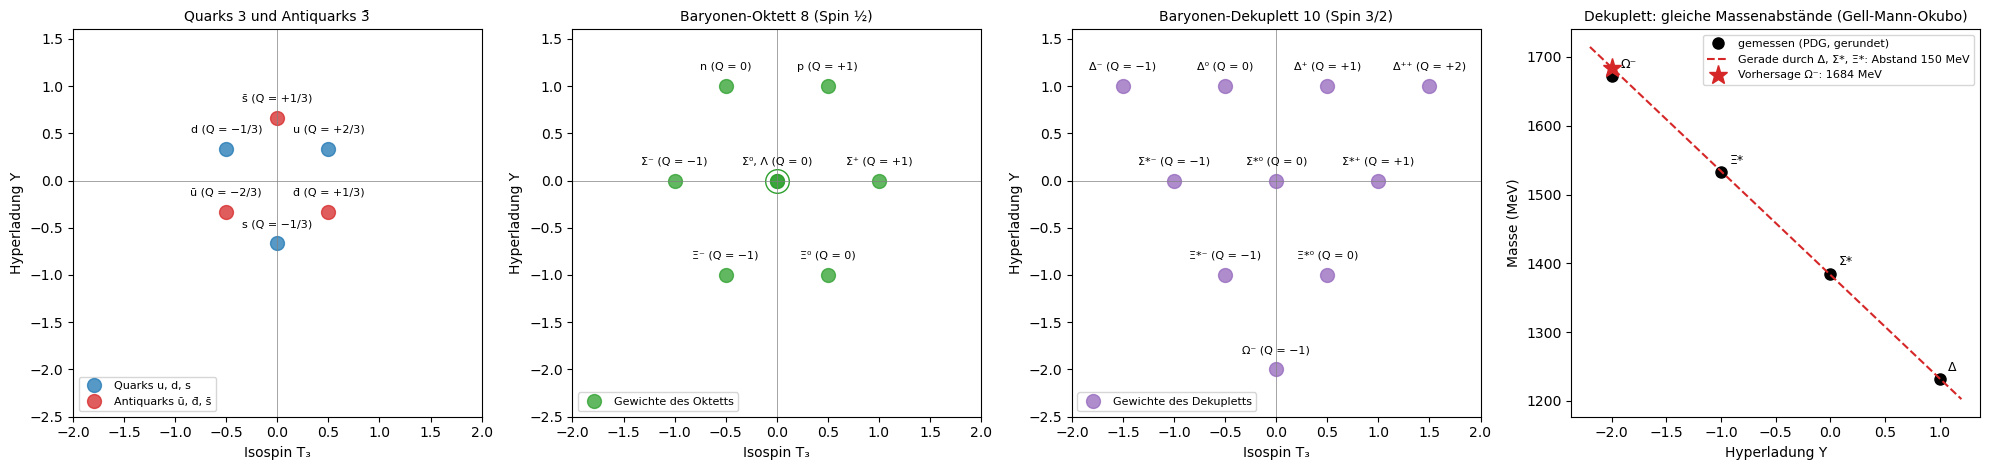

3     : Vertauschungsfehler 1e-16;  Zerlegung über C₂: 3 bzw. 3̄
3̄    : Vertauschungsfehler 1e-16;  Zerlegung über C₂: 3 bzw. 3̄
8     : Vertauschungsfehler 3e-16;  Zerlegung über C₂: 8
3⊗3̄  : Vertauschungsfehler 3e-16;  Zerlegung über C₂: 1 ⊕ 8
3⊗3   : Vertauschungsfehler 2e-16;  Zerlegung über C₂: 3 bzw. 3̄ ⊕ 6 bzw. 6̄
3⊗3⊗3 : Vertauschungsfehler 7e-16;  Zerlegung über C₂: 1 ⊕ 2×8 ⊕ 10
Dimensionsformel (p+1)(q+1)(p+q+2)/2: (1,0) → 3, (1,1) → 8, (2,0) → 6, (3,0) → 10, (2,2) → 27, (3,3) → 64
Strukturkonstanten: f₁₂₃ = 1.0000, f₁₄₇ = 0.5000, f₄₅₈ = 0.8660 (√3/2 = 0.8660)
Dekuplett: 10 Zustände; Massenabstände [153, 148, 139] MeV; Vorhersage Ω⁻ 1684 MeV, gemessen 1672 MeV
Oktett, Gell-Mann-Okubo (N + Ξ)/2 = 1128.5 MeV gegen (3Λ + Σ)/4 = 1135.2 MeV


In [15]:
lam = gell_mann()
T3s = lam / 2
f_abc = np.real(-2j * np.einsum("aij,bjk,cki->abc", T3s, T3s, T3s) + 2j * np.einsum("bij,ajk,cki->abc", T3s, T3s, T3s))   # f_abc = −2i tr([T_a, T_b] T_c)
ksum = lambda A, B: np.kron(A, np.eye(len(B))) + np.kron(np.eye(len(A)), B)
reps14 = {"3": T3s, "3̄": -T3s.conj(), "8": -1j * f_abc}
reps14["3⊗3̄"] = np.array([ksum(T3s[a], -T3s[a].conj()) for a in range(8)])
reps14["3⊗3"] = np.array([ksum(T3s[a], T3s[a]) for a in range(8)])
reps14["3⊗3⊗3"] = np.array([ksum(ksum(T3s[a], T3s[a]), T3s[a]) for a in range(8)])
casimir_of = lambda p, q: (p * p + q * q + p * q + 3 * p + 3 * q) / 3
dim_of = lambda p, q: (p + 1) * (q + 1) * (p + q + 2) // 2
irrep_name = {round(casimir_of(p, q), 6): (nm, dim_of(p, q)) for p, q, nm in [(0, 0, "1"), (1, 0, "3 bzw. 3̄"), (1, 1, "8"), (2, 0, "6 bzw. 6̄"), (3, 0, "10")]}
def qfmt(Q):
    fr = Fraction(Q).limit_denominator(3)
    return "0" if fr == 0 else ("+" if fr > 0 else "−") + str(abs(fr))

def weights(G, C2_value=None):
    C2 = sum(G[a] @ G[a] for a in range(8))
    w, V = np.linalg.eigh(C2)
    P = V[:, np.isclose(w, C2_value)] if C2_value is not None else V
    H = P.conj().T @ (G[2] + 0.37 * G[7]) @ P
    _, U = np.linalg.eigh(H)
    B = P @ U
    return np.array([[np.real(b.conj() @ G[2] @ b), np.real(b.conj() @ G[7] @ b) * 2 / np.sqrt(3)] for b in B.T])

decomp14 = {}
for name, G in reps14.items():
    comm_err = max(np.abs(comm(G[a], G[b]) - 1j * np.tensordot(f_abc[a, b], G, axes=(0, 0))).max() for a in range(8) for b in range(8))
    ev = np.round(np.linalg.eigvalsh(sum(G[a] @ G[a] for a in range(8))), 6)
    vals, cnt = np.unique(ev, return_counts=True)
    decomp14[name] = (comm_err, [(irrep_name[v][0], int(c) // irrep_name[v][1]) for v, c in zip(vals, cnt)])
W3, W3b, W8 = weights(reps14["3"]), weights(reps14["3̄"]), weights(reps14["8"])
W10 = weights(reps14["3⊗3⊗3"], 6.0)
names = {"3": {(0.5, 1 / 3): "u", (-0.5, 1 / 3): "d", (0, -2 / 3): "s"},
         "3̄": {(-0.5, -1 / 3): "ū", (0.5, -1 / 3): "d̄", (0, 2 / 3): "s̄"},
         "8": {(0.5, 1): "p", (-0.5, 1): "n", (1, 0): "Σ⁺", (-1, 0): "Σ⁻", (0, 0): "Σ⁰, Λ", (0.5, -1): "Ξ⁰", (-0.5, -1): "Ξ⁻"},
         "10": {(-1.5, 1): "Δ⁻", (-0.5, 1): "Δ⁰", (0.5, 1): "Δ⁺", (1.5, 1): "Δ⁺⁺", (-1, 0): "Σ*⁻", (0, 0): "Σ*⁰", (1, 0): "Σ*⁺",
                (-0.5, -1): "Ξ*⁻", (0.5, -1): "Ξ*⁰", (0, -2): "Ω⁻"}}
def label(kind, w):
    return next((s for (a, b), s in names[kind].items() if abs(w[0] - a) < 1e-6 and abs(w[1] - b) < 1e-6), "?")
mass10 = {1: 1232, 0: 1385, -1: 1533, -2: 1672}          # MeV: Δ(1232), Σ(1385), Ξ(1530), Ω⁻; gerundete PDG-Mittelwerte
fitY = np.array([1, 0, -1]); fitM = np.array([mass10[y] for y in fitY])
slope14, icpt14 = np.polyfit(fitY, fitM, 1)
octet = {"N": 939, "Λ": 1116, "Σ": 1193, "Ξ": 1318}

fig, axes = plt.subplots(1, 4, figsize=(20, 4.8))
legend14 = {"3": "Quarks u, d, s", "3̄": "Antiquarks ū, d̄, s̄", "8": "Gewichte des Oktetts", "10": "Gewichte des Dekupletts"}
for ax, (title, sets) in zip(axes[:3], [("Quarks 3 und Antiquarks 3̄", [("3", W3, "C0"), ("3̄", W3b, "C3")]),
                                        ("Baryonen-Oktett 8 (Spin ½)", [("8", W8, "C2")]),
                                        ("Baryonen-Dekuplett 10 (Spin 3/2)", [("10", W10, "C4")])]):
    for kind, W, c in sets:
        ax.plot(*W.T, "o", color=c, ms=10, alpha=0.75, label=legend14[kind])
        done = set()
        for w in W:
            k = (round(w[0], 4), round(w[1], 4))
            if k in done:
                ax.plot(*w, "o", ms=17, mfc="none", mec=c)
                continue
            done.add(k)
            Q = w[0] + w[1] / 2
            ax.text(w[0], w[1] + 0.17, f"{label(kind, w)} (Q = {qfmt(Q)})", ha="center", fontsize=8)
    ax.axhline(0, color="grey", lw=0.5); ax.axvline(0, color="grey", lw=0.5)
    ax.set_xlim(-2, 2); ax.set_ylim(-2.5, 1.6)
    ax.set_xlabel("Isospin T₃"); ax.set_ylabel("Hyperladung Y")
    ax.set_title(title, fontsize=10)
    ax.legend(fontsize=8, loc="lower left")
ax = axes[3]
ax.plot(list(mass10), list(mass10.values()), "ko", ms=8, label="gemessen (PDG, gerundet)")
yy = np.linspace(-2.2, 1.2, 10)
ax.plot(yy, slope14 * yy + icpt14, "C3--", label=f"Gerade durch Δ, Σ*, Ξ*: Abstand {abs(slope14):.0f} MeV")
ax.plot(-2, slope14 * -2 + icpt14, "C3*", ms=14, label=f"Vorhersage Ω⁻: {slope14 * -2 + icpt14:.0f} MeV")
for y_, n_ in zip(mass10, ("Δ", "Σ*", "Ξ*", "Ω⁻")):
    ax.text(y_ + 0.08, mass10[y_] + 12, n_, fontsize=9)
ax.set_xlabel("Hyperladung Y")
ax.set_ylabel("Masse (MeV)")
ax.set_title("Dekuplett: gleiche Massenabstände (Gell-Mann-Okubo)", fontsize=10)
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

for name, (err, parts) in decomp14.items():
    print(f"{name:6s}: Vertauschungsfehler {err:.0e};  Zerlegung über C₂: " + " ⊕ ".join(f"{m}×{d}" if m > 1 else d for d, m in parts))
print(f"Dimensionsformel (p+1)(q+1)(p+q+2)/2: " + ", ".join(f"({p},{q}) → {dim_of(p, q)}" for p, q in [(1, 0), (1, 1), (2, 0), (3, 0), (2, 2), (3, 3)]))
print(f"Strukturkonstanten: f₁₂₃ = {f_abc[0, 1, 2]:.4f}, f₁₄₇ = {f_abc[0, 3, 6]:.4f}, f₄₅₈ = {f_abc[3, 4, 7]:.4f} (√3/2 = {np.sqrt(3) / 2:.4f})")
print(f"Dekuplett: {len(W10)} Zustände; Massenabstände {[mass10[-k] - mass10[1 - k] for k in range(3)]} MeV; Vorhersage Ω⁻ {slope14 * -2 + icpt14:.0f} MeV, gemessen {mass10[-2]} MeV")
print(f"Oktett, Gell-Mann-Okubo (N + Ξ)/2 = {(octet['N'] + octet['Ξ']) / 2:.1f} MeV gegen (3Λ + Σ)/4 = {(3 * octet['Λ'] + octet['Σ']) / 4:.1f} MeV")

* Die **drei linken Bilder** zeigen die Gewichtsdiagramme. Die Quarks $u$, $d$, $s$ bilden ein Dreieck, die Antiquarks das gespiegelte Dreieck. Das Oktett ist ein Sechseck mit zwei Zuständen in der Mitte ($\Sigma^0$ und $\Lambda$, Doppelkreis): die Wurzeln aus Exp. 7 plus zwei Nullgewichte. Das Dekuplett ist ein Dreieck mit vier, drei, zwei und einem Zustand, an der Spitze unten das $\Omega^-$. Die Ladungen aus $Q = T_3 + Y/2$ stimmen mit den Teilchen überein: $u$ hat $+\tfrac23$, das Proton $+1$, das $\Delta^{++}$ $+2$.
* Laut **Ausgabe** erfüllen alle Darstellungen die Vertauschungsrelationen (Fehler höchstens $7\cdot10^{-16}$), und die Eigenwerte des Casimir-Operators zerlegen $\mathbf 3\otimes\bar{\mathbf 3} = \mathbf 1\oplus\mathbf 8$, $\mathbf 3\otimes\mathbf 3 = \bar{\mathbf 3}\oplus\mathbf 6$ (der quadratische Casimir-Operator unterscheidet $\mathbf 3$ und $\bar{\mathbf 3}$ nicht, daher „bzw.“) und $\mathbf 3\otimes\mathbf 3\otimes\mathbf 3 = \mathbf 1\oplus\mathbf 8\oplus\mathbf 8\oplus\mathbf{10}$. Das beantwortet die Vorhersage: vier Teile mit den Dimensionen 1, 8, 8 und 10.
* **Rechts** liegen die Massen des Dekupletts auf einer Geraden in $Y$, mit den Abständen 153, 148 und 139 MeV. Die Gerade durch $\Delta$, $\Sigma^\ast$, $\Xi^\ast$ sagt für das $\Omega^-$ 1684 MeV voraus, gemessen sind 1672 MeV (0.7 % daneben). Für das Oktett ergibt die Gell-Mann-Okubo-Formel 1128.5 gegen 1135.2 MeV.
* **Wo es vorkommt:** Die Quarkstruktur der Hadronen (das Quarkmodell von Gell-Mann und Zweig 1964 entstand aus diesen Diagrammen), die Quantenchromodynamik mit Farb-$SU(3)$ (Gluonen im $\mathbf 8$, Hadronen als Farbsinguletts, Gitter-QCD-Rechnungen auf Supercomputern), Flavour-Physik und als Rechentechnik in der Quanteninformation: Qutrits ($d = 3$) beschreibt man mit Gell-Mann-Matrizen wie Qubits mit Pauli-Matrizen.

##### *15. Schur-Weyl-Dualität: Gesamtspin von n Qubits und Mittelung über U(d)*

In welche Spins zerfällt ein Register aus $n$ Qubits, und wie mittelt man einen Operator über alle unitären Drehungen? Vorher vorhersagen: Wie oft kommt in 4 Qubits der Gesamtspin $j = 1$ vor, und wie oft $j = 0$?

Für $n = 1$ bis 8 Qubits diagonalisiert der Code den Gesamtspin $S^2$ mit $\vec S = \sum_i\vec\sigma_i/2$ und zählt, wie oft jeder Spin $j$ vorkommt. Er vergleicht das mit der Formel aus der Schur-Weyl-Dualität und mit den Dimensionen der irreduziblen Darstellungen von $S_n$ (Hakenlängenformel). Links stehen die Vielfachheiten für $n = 10$, in der Mitte der Anteil der Dimension, der auf jeden Gesamtspin fällt, für $n = 10$ bis 400. Rechts wird ein zufälliger Operator $A$ auf zwei Qutrits ($d = 3$) über Haar-zufällige $U\otimes U$ gemittelt und mit der Formel $\alpha\cdot1 + \beta\cdot F$ verglichen ($F$ vertauscht die beiden Qutrits).

**Hintergrund & Fachbegriffe:**
- **Gesamtspin:** $\vec S = \sum_i\vec\sigma_i/2$; $S^2$ hat die Eigenwerte $j(j + 1)$ mit $j = n/2, n/2 - 1, \dots$
- **Vielfachheit** $m_j$: wie oft der Spin $j$ in $(\mathbb C^2)^{\otimes n}$ vorkommt; es gilt $\sum_jm_j(2j + 1) = 2^n$.
- **Young-Diagramm:** eine Zerlegung von $n$ in Zeilen, die von oben nach unten nicht länger werden; nummeriert die irreduziblen Darstellungen von $S_n$. **Hakenlängenformel:** deren Dimension ist $n!/\prod(\text{Hakenlängen})$.
- **Twirl:** die Mittelung $\mathcal T(A) = \int(U\otimes U)A(U\otimes U)^\dagger\,dU$ über das Haar-Maß; **SWAP** $F$: $F(\vert a\rangle\otimes\vert b\rangle) = \vert b\rangle\otimes\vert a\rangle$.
- **Qutrit:** ein Quantensystem mit drei Zuständen ($d = 3$).

**Theorie:**

- **Schur-Weyl:** $(\mathbb C^2)^{\otimes n} = \bigoplus_jV_j\otimes M_j$, wobei $V_j$ der Spin $j$ von $SU(2)$ ist und $M_j$ die irreduzible Darstellung von $S_n$ zum Young-Diagramm mit Zeilen $n/2 + j$ und $n/2 - j$. Deshalb ist $m_j = \dim M_j = \frac{2j + 1}{n/2 + j + 1}\binom{n}{n/2 - j}$. Für $n = 4$: $j = 2$ einmal, $j = 1$ dreimal, $j = 0$ zweimal ($5 + 9 + 2 = 16$).
- **Symmetrischer Unterraum:** $j = n/2$ kommt genau einmal vor; das sind die unter Vertauschung symmetrischen Zustände (Dicke-Zustände), die Bühne der Quantenmetrologie mit $n$ Atomen.
- **Twirl:** $\mathcal T(A)$ vertauscht mit allen $U\otimes U$, liegt also nach Schur-Weyl im Erzeugnis der Permutationen $1$ und $F$: $\mathcal T(A) = \alpha\cdot1 + \beta F$ mit $\alpha = \frac{\mathrm{tr}A - \mathrm{tr}(AF)/d}{d^2 - 1}$ und $\beta = \frac{\mathrm{tr}(AF) - \mathrm{tr}A/d}{d^2 - 1}$ (Weingarten-Kalkül). Monte-Carlo-Mittel konvergieren mit $1/\sqrt N$.

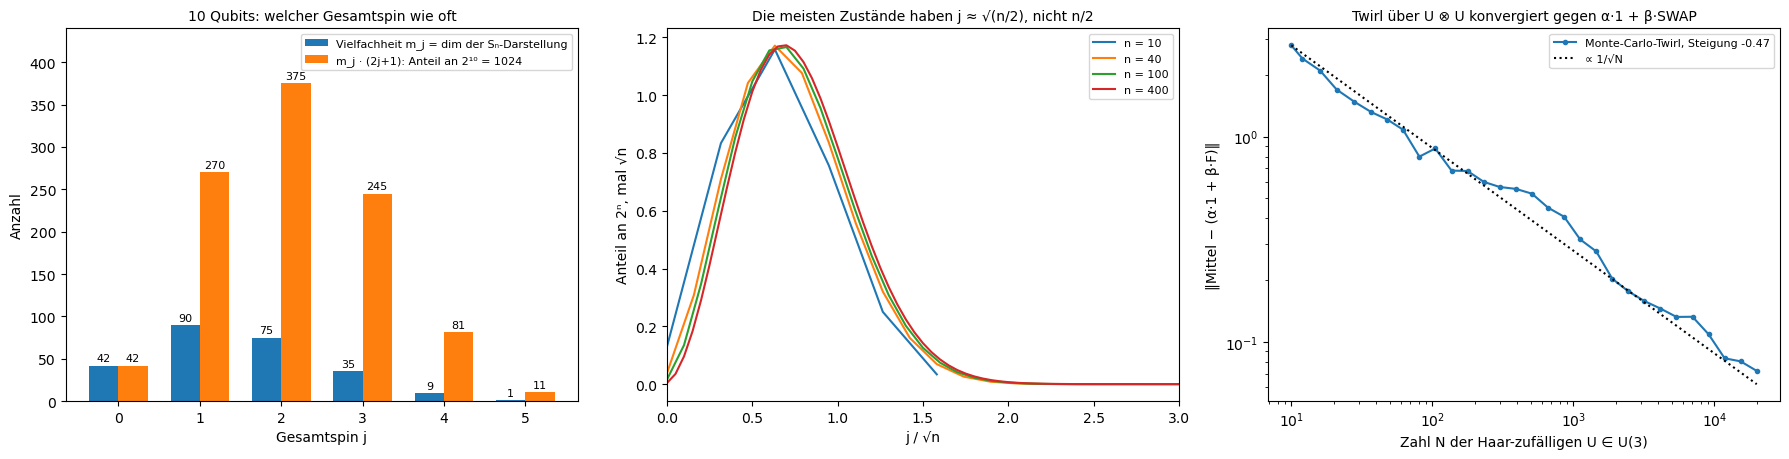

n = 1: Vielfachheiten {0.5: 1}  = Formel = Hakenlänge: True,  Σ m_j(2j+1) = 2ⁿ: True
n = 2: Vielfachheiten {1.0: 1, 0.0: 1}  = Formel = Hakenlänge: True,  Σ m_j(2j+1) = 2ⁿ: True
n = 3: Vielfachheiten {1.5: 1, 0.5: 2}  = Formel = Hakenlänge: True,  Σ m_j(2j+1) = 2ⁿ: True
n = 4: Vielfachheiten {2.0: 1, 1.0: 3, 0.0: 2}  = Formel = Hakenlänge: True,  Σ m_j(2j+1) = 2ⁿ: True
n = 5: Vielfachheiten {2.5: 1, 1.5: 4, 0.5: 5}  = Formel = Hakenlänge: True,  Σ m_j(2j+1) = 2ⁿ: True
n = 6: Vielfachheiten {3.0: 1, 2.0: 5, 1.0: 9, 0.0: 5}  = Formel = Hakenlänge: True,  Σ m_j(2j+1) = 2ⁿ: True
n = 7: Vielfachheiten {3.5: 1, 2.5: 6, 1.5: 14, 0.5: 14}  = Formel = Hakenlänge: True,  Σ m_j(2j+1) = 2ⁿ: True
n = 8: Vielfachheiten {4.0: 1, 3.0: 7, 2.0: 20, 1.0: 28, 0.0: 14}  = Formel = Hakenlänge: True,  Σ m_j(2j+1) = 2ⁿ: True
n = 10: [1, 9, 35, 75, 90, 42] für j = [5.0, 4.0, 3.0, 2.0, 1.0, 0.0]
Twirl auf zwei Qutrits: α = -0.1879, β = -0.4066;  nach 20000 Stichproben Abweichung 0.0723 (Steigung -0.47), Spur bl

In [16]:
def spin_multiplicities(n):
    S = [sum(site_op(P, i, n) for i in range(n)) / 2 for P in (PX, PY, PZ)]
    ev = np.linalg.eigvalsh(np.real(sum(s @ s for s in S)))
    js = (-1 + np.sqrt(1 + 4 * np.round(ev, 6))) / 2
    vals, cnt = np.unique(np.round(js * 2) / 2, return_counts=True)
    return {float(j): int(c // (2 * j + 1)) for j, c in zip(vals, cnt)}

def mult_formula(n, j):
    k = int(round(n / 2 - j))
    return int(round((2 * j + 1) / (n / 2 + j + 1) * comb(n, k)))

def hook_dim(rows):
    n_ = sum(rows)
    cols = [sum(1 for r in rows if r > c) for c in range(rows[0])]
    hooks = [rows[i] - c + cols[c] - i - 1 for i in range(len(rows)) for c in range(rows[i])]
    return factorial(n_) // int(np.prod(hooks))

checks15 = []
for n in range(1, 9):
    num = spin_multiplicities(n)
    form = {j: mult_formula(n, j) for j in num}
    hook = {j: hook_dim([int(n / 2 + j), int(n / 2 - j)] if n / 2 - j > 0 else [n]) for j in num}
    checks15.append((n, num, num == form == hook, sum(m * (2 * j + 1) for j, m in num.items()) == 2 ** n))
rng = np.random.default_rng(15)
d15 = 3
G15 = rng.normal(size=(d15 * d15, d15 * d15)) + 1j * rng.normal(size=(d15 * d15, d15 * d15))
A15 = (G15 + G15.conj().T) / 2                           # hermitesch, damit α und β reell sind
F15 = np.zeros((d15 * d15, d15 * d15))
for a, b in itertools.product(range(d15), repeat=2):
    F15[b * d15 + a, a * d15 + b] = 1
alpha15 = (np.trace(A15) - np.trace(A15 @ F15) / d15) / (d15 ** 2 - 1)
beta15 = (np.trace(A15 @ F15) - np.trace(A15) / d15) / (d15 ** 2 - 1)
twirl_exact = alpha15 * np.eye(d15 * d15) + beta15 * F15
N15 = 20000
Us = stats.unitary_group.rvs(d15, size=N15, random_state=rng)
UU = np.einsum("nij,nkl->nikjl", Us, Us).reshape(N15, d15 * d15, d15 * d15)
samples15 = UU @ A15 @ np.conj(np.transpose(UU, (0, 2, 1)))
running = np.cumsum(samples15, axis=0) / np.arange(1, N15 + 1)[:, None, None]
Ns = np.unique(np.logspace(1, np.log10(N15), 30).astype(int))
tw_err = np.array([np.linalg.norm(running[k - 1] - twirl_exact) for k in Ns])
tw_slope = np.polyfit(np.log(Ns), np.log(tw_err), 1)[0]

fig, axes = plt.subplots(1, 3, figsize=(18, 4.7))
ax = axes[0]
n10 = 10
j10 = np.arange(n10 / 2, -0.1, -1)
m10 = np.array([mult_formula(n10, j) for j in j10])
ax.bar(j10 - 0.18, m10, width=0.36, label="Vielfachheit m_j = dim der Sₙ-Darstellung")
ax.bar(j10 + 0.18, m10 * (2 * j10 + 1), width=0.36, color="C1", label="m_j · (2j+1): Anteil an 2¹⁰ = 1024")
for j, m in zip(j10, m10):
    ax.text(j - 0.18, m + 5, str(m), ha="center", fontsize=8)
    ax.text(j + 0.18, m * (2 * j + 1) + 5, str(int(m * (2 * j + 1))), ha="center", fontsize=8)
ax.set_ylim(0, 440)
ax.set_xlabel("Gesamtspin j")
ax.set_ylabel("Anzahl")
ax.set_title("10 Qubits: welcher Gesamtspin wie oft", fontsize=10)
ax.legend(fontsize=8)
ax = axes[1]
for n_, c in zip((10, 40, 100, 400), ("C0", "C1", "C2", "C3")):
    jj = np.arange(n_ / 2, -0.1, -1)
    share = np.array([mult_formula(n_, j) * (2 * j + 1) for j in jj], float) / 2 ** n_
    ax.plot(jj / np.sqrt(n_), share * np.sqrt(n_), "-", color=c, label=f"n = {n_}")
ax.set_xlim(0, 3)
ax.set_xlabel("j / √n")
ax.set_ylabel("Anteil an 2ⁿ, mal √n")
ax.set_title("Die meisten Zustände haben j ≈ √(n/2), nicht n/2", fontsize=10)
ax.legend(fontsize=8)
ax = axes[2]
ax.loglog(Ns, tw_err, "o-", ms=3, label=f"Monte-Carlo-Twirl, Steigung {tw_slope:.2f}")
ax.loglog(Ns, tw_err[0] * np.sqrt(Ns[0] / Ns), "k:", label="∝ 1/√N")
ax.set_xlabel("Zahl N der Haar-zufälligen U ∈ U(3)")
ax.set_ylabel("‖Mittel − (α·1 + β·F)‖")
ax.set_title("Twirl über U ⊗ U konvergiert gegen α·1 + β·SWAP", fontsize=10)
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

for n, num, ok, dim_ok in checks15:
    print(f"n = {n}: Vielfachheiten {dict(sorted(num.items(), reverse=True))}  = Formel = Hakenlänge: {ok},  Σ m_j(2j+1) = 2ⁿ: {dim_ok}")
print(f"n = 10: {[mult_formula(10, j) for j in j10]} für j = {j10.tolist()}")
print(f"Twirl auf zwei Qutrits: α = {alpha15.real:.4f}, β = {beta15.real:.4f};  nach {N15} Stichproben Abweichung {tw_err[-1]:.4f} (Steigung {tw_slope:.2f}), "
      f"Spur bleibt erhalten: {np.isclose(np.trace(running[-1]), np.trace(A15))}")

* **Links** stehen die Vielfachheiten der Gesamtspins in 10 Qubits (blau): $j = 5$ einmal (der symmetrische Unterraum), $j = 4$ neunmal, dann 35, 75, 90 und 42-mal für $j = 0$; orange die Zahl der Zustände, die auf jeden Spin entfallen (zusammen 1024). Laut **Ausgabe** stimmen für $n = 1$ bis 8 die durch Diagonalisieren von $S^2$ gezählten Vielfachheiten mit der Formel und mit den Dimensionen der $S_n$-Darstellungen aus der Hakenlängenformel überein. Für $n = 4$ kommt $j = 2$ einmal, $j = 1$ dreimal und $j = 0$ zweimal vor; das beantwortet die Vorhersage.
* In der **Mitte** liegt der Anteil der Dimension für große $n$ auf einer Kurve in $j/\sqrt n$ mit Maximum bei $j\approx0.7\sqrt n = \sqrt{n/2}$: Fast alle Zustände haben einen Gesamtspin der Größenordnung $\sqrt n$, weit unter dem Maximum $n/2$. Der symmetrische Unterraum ist ein winziger Teil (11 von 1024 Zuständen bei $n = 10$).
* **Rechts** konvergiert das Monte-Carlo-Mittel von $(U\otimes U)A(U\otimes U)^\dagger$ über Haar-zufällige $U\in U(3)$ gegen $\alpha\cdot1 + \beta F$, mit Steigung $-0.47$, also wie $1/\sqrt N$. Laut Ausgabe sind $\alpha = -0.1879$ und $\beta = -0.4066$, und nach 20 000 Stichproben bleibt eine Abweichung von 0.072. Das Mittel liegt im Raum der Permutationen, wie Schur-Weyl verlangt.
* **Wo es vorkommt:** Rauschfreie Unterräume (der Singulett-Unterraum ist gegen kollektives Rauschen geschützt), Quantenmetrologie mit Dicke- und spingequetschten Zuständen in Atomuhren, Schätzen des Spektrums eines Zustands aus vielen Kopien (Keyl-Werner, Schur-Transformation), Randomized Benchmarking und Shadow-Tomographie (Twirls über Clifford- und Haar-Gruppen machen Rauschen zu wenigen Parametern), Werner-Zustände in der Verschränkungstheorie und Haar-Integrale mit dem Weingarten-Kalkül in der Theorie der Barren Plateaus (Exp. 9).

#### **Ergebnis**

Beim Lauf vom 2026-10-27:

- **Tangentialraum:** Die numerisch linearisierten Gruppenbedingungen geben für $SO(n)$, $SL(n,\mathbb R)$, $U(n)$, $SU(n)$, $Sp(2n,\mathbb R)$ ($n = 2$ bis 5) und $SO(1,3)$ genau die Dimensionen der Formeln; liegt $X$ in der Lie-Algebra, verletzt $1 + \varepsilon X$ die Bedingung mit Steigung 2.00 statt 1.00. Kommutatoren bleiben exakt in $\mathfrak{so}(4)$, Produkte nicht.
- **Exponentialabbildung:** Die Taylor-Reihe erreicht für $\Vert X\Vert = 20$ wegen Auslöschung nur $1.4\cdot10^{-8}$; Formeln für $SL(2,\mathbb R)$ und Rodrigues stimmen auf $10^{-12}$ bzw. $10^{-16}$; zwei Boosts mit $0.5c$ ergeben $0.8c$.
- **Grenzen:** Kein Exponential in $SL(2,\mathbb R)$ hat Spur unter $-2$ (kleinste gemessene $-1.9999$), $\mathrm{diag}(-2, -\tfrac12)$ ist nur ein Produkt zweier Exponentiale; der Logarithmus einer Drehung springt bei $\pi$; in $U(4)$ hat jedes Element einen Logarithmus.
- **BCH:** Abbruch nach Ordnung 1 bis 4 gibt Fehler mit Steigungen 1.999, 2.999, 3.998, 4.999; in der Heisenberg-Algebra ist $A + B + \tfrac12[A, B]$ exakt.
- **Trotter:** Steigungen $-1.02$, $-2.01$, $-3.98$; für einen Fehler unter $10^{-6}$ braucht die Suzuki-Formel 561 Faktoren, die beiden anderen kommen mit 2000 nicht hin.
- **Lie-Gruppen-Integratoren:** Nach 30 s hat das Euler-Verfahren $\det R = 5.444 = (1 + h^2\vert\omega\vert^2)^{3000}$, Runge-Kutta 4 weicht um $10^{-8}$ von $SO(3)$ ab, die Lie-Verfahren bleiben bei $10^{-13}$ mit Konvergenzordnung 1 und 2.
- **Killing-Form:** negativ definit für $\mathfrak{so}(3)$, $\mathfrak{su}(2)$, $\mathfrak{su}(3)$, $\mathfrak{so}(4)$; Signatur $(2, 1)$ für $\mathfrak{sl}(2,\mathbb R)$ und $(3, 3)$ für die Lorentz-Algebra; ausgeartet für die auflösbaren $\mathfrak{se}(2)$, $\mathfrak{aff}(1)$ und null für die nilpotente Heisenberg-Algebra; die Wurzeln von $\mathfrak{su}(3)$ bilden ein Sechseck.
- **Wurzelsysteme:** Wurzelzahlen, Dimensionen, Weyl-Gruppen (bis $E_6$ mit 51 840 Elementen aus der Bahn) und Coxeter-Zahlen stimmen mit den Formeln; die 240 Wurzeln von $E_8$ liegen in der Coxeter-Ebene auf 8 Ringen zu je 30; die einfachen Wurzeln von $F_4$ aus sympy 1.14 sind fehlerhaft.
- **Dynamische Lie-Algebren:** $n$, $3n$, $n(2n - 1)$, $2n(2n - 1)$ und $4^n - 1$ für die fünf Gattersätze; die Varianz tiefer Zufallsschaltkreise stimmt auf wenige Prozent mit $\Vert O_{\mathfrak g}\Vert^2\Vert\rho_{\mathfrak g}\Vert^2/\dim\mathfrak g$ und ist bei 7 Qubits für $\mathfrak{so}(14)$ 8.3-mal größer als für $\mathfrak{su}(128)$.
- **Charaktertafeln:** Für $S_3$, $D_4$, $Q_8$, $A_4$, $S_4$, $A_5$ gelten alle Orthogonalitätsrelationen und $\sum d_i^2 = \vert G\vert$; $D_4$ und $Q_8$ haben dieselbe Tafel; die Permutationsdarstellungen von $S_4$ zerfallen in $1 + 3$, $1 + 2 + 3$ und die reguläre.
- **Molekülschwingungen:** $H_2O$ $2A_1 + B_2$, $NH_3$ $2A_1 + 2E$, $CH_4$ $A_1 + E + 2T_2$, $SF_6$ und Benzol wie in der Literatur, $C_{60}$ 174 Schwingungen auf 46 Frequenzen mit 4 IR- und 10 Raman-Linien wie gemessen; bei Inversionszentrum gilt das Alternativverbot.
- **Spin $j$:** Vertauschungsrelationen und $J^2 = j(j + 1)$ bis auf $10^{-15}$, d-Matrizen wie sympy, Drehung um $2\pi$ gleich $(-1)^{2j}$; der um 60° gedrehte Spin 10 ist binomial verteilt mit Maximum bei $m = 5$.
- **Clebsch-Gordan:** eigene Koeffizienten gleich sympy auf $7\cdot10^{-16}$; Dipol-Matrixelemente nur bei $\Delta l = \pm1$, $\Delta m = 0$ bzw. $+1$; reduzierte Matrixelemente unabhängig von $m$ (Wigner-Eckart).
- **$SU(3)$:** $\mathbf 3\otimes\bar{\mathbf 3} = \mathbf 1\oplus\mathbf 8$, $\mathbf 3\otimes\mathbf 3\otimes\mathbf 3 = \mathbf 1\oplus\mathbf 8\oplus\mathbf 8\oplus\mathbf{10}$; die Gerade durch die Dekuplett-Massen sagt das $\Omega^-$ bei 1684 MeV voraus (gemessen 1672 MeV).
- **Schur-Weyl:** Vielfachheiten der Gesamtspins für $n\leq8$ gleich der Formel und den Hakenlängen-Dimensionen; der Twirl über $U\otimes U$ konvergiert wie $1/\sqrt N$ (Steigung $-0.47$) gegen $\alpha\cdot1 + \beta F$.

#### **Variationen**

Jeweils zuerst die Vorhersage notieren, dann den Code ändern und prüfen:

1. **Thomas-Wigner-Drehung:** Führe in Experiment 2 als $4\times4$-Lorentz-Matrizen einen Boost mit $0.5c$ in $x$-Richtung und danach einen in $y$-Richtung aus und zerlege das Produkt in Boost mal Drehung (Polarzerlegung). *(Vorhersage: Boost-Erzeuger in verschiedene Richtungen vertauschen nicht, ihr Kommutator ist ein Drehgenerator; deshalb bleibt eine Drehung um $\arccos\frac{2\gamma}{1 + \gamma^2} = 8.2°$ mit $\gamma = 1/\sqrt{1 - 0.25}$ übrig. Getestet: 8.21°.)*
2. **Spur genau $-2$:** Suche in Experiment 3 einen reellen Logarithmus von $-\begin{pmatrix}1 & 1\cr 0 & 1\end{pmatrix}$. *(Vorhersage: Es gibt keinen. Ein reelles $X$ mit diesem Exponential bräuchte die Eigenwerte $\pm i\pi$; dann wäre $e^X$ diagonalisierbar, die Matrix ist es nicht. Spur $-2$ hat unter den Exponentialen nur $-1$ selbst. Getestet: `logm` liefert $i\pi$ auf der Diagonale, also keinen reellen Logarithmus.)*
3. **$\mathfrak u(2)$ statt $\mathfrak{su}(2)$:** Ergänze in Experiment 7 die Basis von $\mathfrak{su}(2)$ um $-\tfrac i2\cdot1$. *(Vorhersage: Signatur $(0, 3, 1)$, nicht halbeinfach, weil die Eins im Zentrum liegt und $\mathrm{ad}$ von ihr null ist; die abgeleitete Reihe ist $[4, 3]$, denn $[\mathfrak u(2), \mathfrak u(2)] = \mathfrak{su}(2)$. Getestet: Eigenwerte $-2, -2, -2, 0$, Reihe $[4, 3]$.)*
4. **$XX$ und $YY$ getrennt:** Berechne in Experiment 9 die DLA von `chain(n, "XX", "YY")`. *(Vorhersage: Nach Jordan-Wigner verbinden die Terme die $2n$ Majorana-Operatoren zu zwei getrennten Ketten aus je $n$; die Algebra ist $\mathfrak{so}(n)\oplus\mathfrak{so}(n)$ mit Dimension $n(n - 1)$. Getestet: 2, 6, 12, 20, 30, 42 für $n = 2$ bis 7.)*
5. **$S_5$:** Berechne in Experiment 10 die Charaktertafel von $S_5$. *(Vorhersage: 7 Klassen, eine pro Zyklentyp, also pro Zerlegung von 5; Grade 1, 1, 4, 4, 5, 5, 6 mit $1 + 1 + 16 + 16 + 25 + 25 + 36 = 120$. Getestet: Klassengrößen 1, 10, 15, 20, 20, 24, 30 und genau diese Grade.)*
6. **Gestaffeltes Ethan:** Ergänze in Experiment 11 Ethan ($D_{3d}$, mit Inversionszentrum). *(Vorhersage: 18 Schwingungen, Alternativverbot. Getestet: $3A_{1g} + A_{1u} + 2A_{2u} + 3E_g + 3E_u$, 12 Frequenzen, 5 im IR-, 6 im Raman-Spektrum, stumm nur die Torsion $A_{1u}$.)*
7. **Spin um 90° gedreht:** Setze in Experiment 12 $\beta = \pi/2$. *(Vorhersage: Binomialverteilung mit $p = \tfrac12$, Mittelwert 0, Standardabweichung $\sqrt{j/2} = 2.24$. Getestet: Mittelwert 0, Standardabweichung 2.236.)*
8. **Quadrupolübergänge:** Ersetze in Experiment 13 $\cos\theta$ durch $Y_2^0$. *(Vorhersage: Ein Tensoroperator vom Rang 2 mit gerader Parität erlaubt $\Delta l = 0, \pm2$ und $\Delta m = 0$, aber nicht $s\to s$, weil $0\otimes2$ keinen Spin 0 enthält. Getestet: 21 Matrixelemente ungleich null, alle mit $\vert\Delta l\vert\in\lbrace0, 2\rbrace$ und $\Delta m = 0$, keines zwischen $s$-Zuständen.)*
9. **Quark und Gluon:** Zerlege in Experiment 14 das Tensorprodukt $\mathbf 3\otimes\mathbf 8$. *(Vorhersage: $\mathbf 3\otimes\mathbf 8 = \mathbf{15}\oplus\bar{\mathbf 6}\oplus\mathbf 3$ mit den Casimir-Werten $\tfrac{16}3$, $\tfrac{10}3$, $\tfrac43$. Getestet: Eigenräume der Dimension 15, 6 und 3 mit genau diesen Werten.)*
10. **Catalan-Zahlen:** Wie oft kommt in Experiment 15 der Gesamtspin $j = 0$ in 12 Qubits vor? *(Vorhersage: $m_0 = \frac1{n/2 + 1}\binom{n}{n/2}$ ist die Catalan-Zahl $C_{n/2}$, also $C_6 = 132$; für $n = 10$ ist es $C_5 = 42$. Getestet: Formel 132, durch Diagonalisieren für $n = 10$: 42.)*

#### **Wiederholung**

Erst selbst antworten, dann aufklappen.

<details><summary>1. Was ist eine Lie-Algebra, und wie bekommt man sie aus einer Lie-Gruppe?</summary>

Ein Vektorraum mit einer antisymmetrischen, bilinearen Klammer, die die Jacobi-Identität erfüllt. Für eine Matrix-Lie-Gruppe ist es der Tangentialraum an der Eins: die Ableitungen $\dot g(0)$ aller Kurven durch die Eins, mit dem Kommutator als Klammer.
</details>

<details><summary>2. Warum besteht so(n) aus den schiefsymmetrischen Matrizen, und warum hat es die Dimension n(n−1)/2?</summary>

Linearisiert man $g^Tg = 1$ mit $g = 1 + \varepsilon X$, bleibt $X^T + X = 0$. Eine schiefsymmetrische Matrix hat eine Nulldiagonale und ist durch die $n(n - 1)/2$ Einträge oberhalb der Diagonale bestimmt.
</details>

<details><summary>3. Warum bleibt der Kommutator zweier Elemente in der Lie-Algebra, das Produkt aber nicht?</summary>

Für schiefsymmetrische $X, Y$ ist $[X, Y]^T = YX - XY = -[X, Y]$, dagegen $(XY)^T = YX$, im Allgemeinen nicht $-XY$. Allgemein liegt $e^{sX}Ye^{-sX}$ für jedes $s$ in der Lie-Algebra (es ist die Ableitung der Kurve $t\mapsto e^{sX}e^{tY}e^{-sX}$ in der Gruppe), und seine Ableitung nach $s$ bei $s = 0$ ist $[X, Y]$.
</details>

<details><summary>4. Welche Rechenregeln gelten für die Exponentialabbildung, und welche nicht?</summary>

$e^{(s + t)X} = e^{sX}e^{tX}$, $\det e^X = e^{\mathrm{tr}X}$, $ge^Xg^{-1} = e^{gXg^{-1}}$. Dagegen ist $e^{X + Y} = e^Xe^Y$ nur für vertauschende $X, Y$ richtig; sonst braucht man BCH oder Trotter.
</details>

<details><summary>5. Warum berechnet man e^X großer Matrizen nicht einfach mit der Taylor-Reihe?</summary>

Die Terme $\Vert X\Vert^k/k!$ werden bei $k\approx\Vert X\Vert$ riesig und löschen sich danach weitgehend aus; dabei gehen Stellen verloren (bei $\Vert X\Vert = 20$ etwa acht). Skalieren und Quadrieren rechnet $e^{X/2^s}$ für eine kleine Matrix und quadriert $s$-mal.
</details>

<details><summary>6. Ist jedes Element einer Lie-Gruppe ein Exponential?</summary>

Bei kompakten zusammenhängenden Gruppen wie $SO(n)$, $SU(n)$ ja. In $SL(2,\mathbb R)$ nicht: Jedes $e^X$ hat Spur $\geq-2$, also ist $\mathrm{diag}(-2, -\tfrac12)$ keines; es ist aber ein Produkt zweier Exponentiale.
</details>

<details><summary>7. Was sagt die Baker-Campbell-Hausdorff-Formel, und wann bricht sie ab?</summary>

$\log(e^Ae^B) = A + B + \tfrac12[A, B] + \tfrac1{12}([A, [A, B]] + [B, [B, A]]) + \dots$, nur Kommutatoren. Ist $[A, B]$ zentral, wie bei $[x, p] = i\hbar$, bricht sie nach dem zweiten Term ab.
</details>

<details><summary>8. Wie groß sind die Fehler der Trotter-Formeln erster, zweiter und vierter Ordnung?</summary>

Bei $n$ Schritten $O(t^2/n)$ mit einer Schranke $t^2\Vert[A, B]\Vert/(2n)$, $O(t^3/n^2)$ für die symmetrische Strang-Formel und $O(t^5/n^4)$ für Suzuki. Doppelt so viele Schritte teilen den Fehler durch 2, 4 und 16.
</details>

<details><summary>9. Warum verlässt das Euler-Verfahren die Drehgruppe, ein Lie-Gruppen-Integrator aber nicht?</summary>

$1 + hX$ ist keine Drehung; $\det(1 + h[\omega]_\times) = 1 + h^2\vert\omega\vert^2$, und die Fehler multiplizieren sich. Ein Lie-Integrator multipliziert mit $e^{h[\omega]_\times}$, einer exakten Drehung, und Produkte von Drehungen sind Drehungen.
</details>

<details><summary>10. Was verrät die Killing-Form über eine Lie-Algebra?</summary>

$K(X, Y) = \mathrm{tr}(\mathrm{ad}_X\mathrm{ad}_Y)$. Nicht ausgeartet heißt halbeinfach (Cartan), negativ definit heißt zusätzlich kompakt; positive Richtungen sind nichtkompakte wie Boosts. In auflösbaren Algebren ist sie ausgeartet, in nilpotenten null.
</details>

<details><summary>11. Was sind Wurzeln, und wie entstehen aus ihnen Cartan-Matrix und Dynkin-Diagramm?</summary>

Die gemeinsamen Eigenwerte der $\mathrm{ad}_H$ für $H$ in der Cartan-Unteralgebra. Aus den einfachen Wurzeln bildet man $a_{ij} = 2(\alpha_i, \alpha_j)/(\alpha_j, \alpha_j)$; das Diagramm hat einen Knoten pro einfacher Wurzel und $a_{ij}a_{ji}$ Linien zwischen zwei Knoten, mit Pfeil zur kürzeren Wurzel.
</details>

<details><summary>12. Welche einfachen Lie-Algebren über ℂ gibt es?</summary>

Vier Familien $A_n = \mathfrak{sl}(n + 1)$, $B_n = \mathfrak{so}(2n + 1)$, $C_n = \mathfrak{sp}(2n)$, $D_n = \mathfrak{so}(2n)$ und fünf Ausnahmen $G_2$, $F_4$, $E_6$, $E_7$, $E_8$ (Killing, Cartan). $E_8$ hat Dimension 248 und 240 Wurzeln.
</details>

<details><summary>13. Was ist die dynamische Lie-Algebra eines Schaltkreises, und was hat sie mit Barren Plateaus zu tun?</summary>

Der Lie-Abschluss der Erzeuger $iG_k$ der Gatter; die erreichbaren Operationen sind $e^{\mathfrak g}$. Für tiefe zufällige Schaltkreise ist die Varianz der Ausgaben etwa $\Vert O_{\mathfrak g}\Vert^2\Vert\rho_{\mathfrak g}\Vert^2/\dim\mathfrak g$: exponentiell klein für $\mathfrak{su}(2^n)$, nur polynomiell klein für kleine Algebren wie $\mathfrak{so}(2n)$.
</details>

<details><summary>14. Was ist ein Charakter, und welche Relationen erfüllt eine Charaktertafel?</summary>

Die Spur $\chi(g) = \mathrm{tr}\,\rho(g)$, konstant auf Konjugationsklassen. So viele irreduzible Darstellungen wie Klassen, Zeilen orthonormal mit Gewicht $\vert C\vert/\vert G\vert$, Spalten orthogonal, Grade teilen $\vert G\vert$, $\sum d_i^2 = \vert G\vert$.
</details>

<details><summary>15. Bestimmt die Charaktertafel die Gruppe?</summary>

Nein: $D_4$ und $Q_8$ haben dieselbe Tafel, aber verschieden viele Elemente der Ordnung 2. Die Tafel kennt die Klassen und die Darstellungen, aber nicht, wie sich die Elemente innerhalb der Klassen multiplizieren.
</details>

<details><summary>16. Wie sagt man voraus, welche Molekülschwingungen im IR- und im Raman-Spektrum erscheinen?</summary>

Man zerlegt die Darstellung der Auslenkungen ($\chi = N_{\mathrm{fest}}\cdot\mathrm{tr}\,R$, minus Verschiebungen und Drehungen) in irreduzible. IR-aktiv sind die Typen, die wie $x, y, z$ transformieren, Raman-aktiv die wie $x^2, xy, \dots$. Mit Inversionszentrum schließen sich beide aus.
</details>

<details><summary>17. Wie konstruiert man die Spin-j-Darstellung, und warum ist 2j ganzzahlig?</summary>

Man startet beim höchsten Gewicht $\vert j, j\rangle$ und steigt mit $J_-$ ab, $J_-\vert j, m\rangle = \sqrt{j(j + 1) - m(m - 1)}\,\vert j, m - 1\rangle$. Die Leiter muss nach endlich vielen Schritten bei $m = -j$ enden; von $j$ nach $-j$ in ganzen Schritten geht nur, wenn $2j$ ganzzahlig ist.
</details>

<details><summary>18. Was ergibt eine Drehung um 360° für einen Spin ½?</summary>

$e^{-2\pi iJ_z} = -1$; erst 720° geben die Eins. Halbzahlige Spins sind Darstellungen von $SU(2)$, nicht von $SO(3)$; ihre Charaktere haben die Periode $4\pi$.
</details>

<details><summary>19. Was sagt das Wigner-Eckart-Theorem, und woher kommen die Dipol-Auswahlregeln?</summary>

Matrixelemente eines Tensoroperators sind ein Clebsch-Gordan-Koeffizient mal ein reduziertes Matrixelement, das nicht von $m$ abhängt. Der Dipoloperator hat Rang 1 und ungerade Parität; deshalb sind nur $\Delta l = \pm1$ und $\Delta m = 0, \pm1$ erlaubt.
</details>

<details><summary>20. Wie zerfällt 3⊗3⊗3 in SU(3), und wie wurde das Ω⁻ vorhergesagt?</summary>

$\mathbf 3\otimes\mathbf 3\otimes\mathbf 3 = \mathbf{10}\oplus\mathbf 8\oplus\mathbf 8\oplus\mathbf 1$. Im Dekuplett fehlte 1962 die Spitze mit Hyperladung $-2$; die gleichen Massenabstände von etwa 150 MeV sagten etwa 1680 MeV voraus, gefunden wurde das $\Omega^-$ 1964 mit 1672 MeV.
</details>

<details><summary>21. Was besagt die Schur-Weyl-Dualität, und was folgt daraus für Mittelungen über U⊗U?</summary>

Auf $(\mathbb C^d)^{\otimes n}$ sind die Operatoren, die mit allen $U^{\otimes n}$ vertauschen, genau die Kombinationen von Permutationen, und der Raum zerfällt in Paare irreduzibler Darstellungen von $U(d)$ und $S_n$. Deshalb ist das Haar-Mittel von $(U\otimes U)A(U\otimes U)^\dagger$ eine Kombination $\alpha\cdot1 + \beta\cdot\mathrm{SWAP}$.
</details>

#### **Nächste Schritte**

- **Lorentz- und Poincaré-Gruppe:** Spinoren und $SL(2,\mathbb C)$, die Dirac-Gleichung, Wigners Klassifikation der Teilchen nach Masse und Spin.
- **Unendlichdimensionale Darstellungen:** der harmonische Oszillator als Darstellung von $\mathfrak{sl}(2,\mathbb R)$ und der Heisenberg-Algebra, Virasoro- und Kac-Moody-Algebren der konformen Feldtheorie.
- **Lie-Gruppen im maschinellen Lernen:** Riemannsche Optimierung auf $SO(n)$ und Stiefel-Mannigfaltigkeiten, Gruppenfaltungen, äquivariante Netze mit Spin-$l$-Merkmalen und Clebsch-Gordan-Schichten.
- **Darstellungstheorie in der Quanteninformation:** unitäre Designs und die Clifford-Gruppe, die Schur-Transformation als Quantenschaltkreis, symmetrieangepasste variationelle Ansätze.
- **Harmonische Analysis auf Gruppen:** der Satz von Peter und Weyl ausführlich, Fourier-Transformation auf $S_n$ für Ranking-Daten, Kugelflächenfunktionen und Spektralmethoden auf der Kugel (Wetter- und Klimamodelle).
- **Algebraische Gruppen und Zahlentheorie:** Gruppen vom Lie-Typ über endlichen Körpern, Galois-Darstellungen und das Langlands-Programm.

#### **Referenzen**

- Hall, B. C. (2015): *Lie Groups, Lie Algebras, and Representations: An Elementary Introduction*, 2nd ed., Springer.
- Fulton, W. & Harris, J. (1991): *Representation Theory: A First Course*, Springer.
- Humphreys, J. E. (1972): *Introduction to Lie Algebras and Representation Theory*, Springer.
- Serre, J.-P. (1977): *Linear Representations of Finite Groups*, Springer.
- Georgi, H. (1999): *Lie Algebras in Particle Physics*, 2nd ed., Westview Press.
- Cotton, F. A. (1990): *Chemical Applications of Group Theory*, 3rd ed., Wiley.
- Sakurai, J. J. & Napolitano, J. (2017): *Modern Quantum Mechanics*, 2nd ed., Cambridge University Press, Kap. 3 (Drehimpuls, Clebsch-Gordan, Wigner-Eckart).
- Wigner, E. P. (1931): *Gruppentheorie und ihre Anwendung auf die Quantenmechanik der Atomspektren*, Vieweg.
- Higham, N. J. (2005): *The scaling and squaring method for the matrix exponential revisited*, SIAM Journal on Matrix Analysis and Applications 26, 1179.
- Iserles, A., Munthe-Kaas, H. Z., Nørsett, S. P. & Zanna, A. (2000): *Lie-group methods*, Acta Numerica 9, 215.
- Suzuki, M. (1991): *General theory of fractal path integrals with applications to many-body theories and statistical physics*, Journal of Mathematical Physics 32, 400.
- Childs, A. M., Su, Y., Tran, M. C., Wiebe, N. & Zhu, S. (2021): *Theory of Trotter Error with Commutator Scaling*, Physical Review X 11, 011020.
- Ragone, M. et al. (2024): *A Lie algebraic theory of barren plateaus for deep parameterized quantum circuits*, Nature Communications 15, 7172.
- Fontana, E. et al. (2024): *Characterizing barren plateaus in quantum ansätze with the adjoint representation*, Nature Communications 15, 7171.
- Gell-Mann, M. (1961): *The Eightfold Way: A Theory of Strong Interaction Symmetry*, Caltech Report CTSL-20.
- Barnes, V. E. et al. (1964): *Observation of a Hyperon with Strangeness Minus Three*, Physical Review Letters 12, 204.
- Krätschmer, W., Lamb, L. D., Fostiropoulos, K. & Huffman, D. R. (1990): *Solid C60: a new form of carbon*, Nature 347, 354.
- Bethune, D. S. et al. (1991): *Vibrational Raman and infrared spectra of chromatographically separated C60 and C70 fullerene clusters*, Chemical Physics Letters 179, 181.
- Coldea, R. et al. (2010): *Quantum Criticality in an Ising Chain: Experimental Evidence for Emergent E8 Symmetry*, Science 327, 177.
- Particle Data Group (2024): *Review of Particle Physics*, Physical Review D 110, 030001.